<a href="https://colab.research.google.com/github/Aadarshmishra13/ai-driven-drug-discovery/blob/main/notebooks/01_EGFR_Target_and_ChEMBL_Data_Audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# EGFR Target Selection and ChEMBL Data Audit

**Project:** AI-Driven Drug Discovery

**Phase:** 1 — Target Selection and Data Audit

**Therapeutic Area:** Oncology

**Target:** Epidermal Growth Factor Receptor (EGFR)

**ChEMBL Target ID:** CHEMBL203

## Objective

To validate EGFR as a suitable therapeutic target for an ML-based drug discovery project and assess the availability, quality and distribution of experimentally measured compound bioactivity data from ChEMBL.

In [ ]:
!pip install -q pandas numpy requests matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Environment setup successful!")

Environment setup successful!


In [ ]:
print("HTTP Status:", response.status_code)
print("Response URL:", response.url)
print("Content-Type:", response.headers.get("Content-Type"))

print("\nResponse JSON:")
print(response.json())

HTTP Status: 200
Response URL: https://www.ebi.ac.uk/chembl/api/data/target/CHEMBL203.json
Content-Type: application/json

Response JSON:
{'cross_references': [], 'organism': 'Homo sapiens', 'pref_name': 'Epidermal growth factor receptor', 'species_group_flag': False, 'target_chembl_id': 'CHEMBL203', 'target_components': [{'accession': 'P00533', 'component_description': 'Epidermal growth factor receptor', 'component_id': 147, 'component_type': 'PROTEIN', 'relationship': 'SINGLE PROTEIN', 'target_component_synonyms': [{'component_synonym': '2.7.10.1', 'syn_type': 'EC_NUMBER'}, {'component_synonym': 'EGFR', 'syn_type': 'GENE_SYMBOL'}, {'component_synonym': 'Epidermal growth factor receptor', 'syn_type': 'UNIPROT'}, {'component_synonym': 'ERBB', 'syn_type': 'GENE_SYMBOL_OTHER'}, {'component_synonym': 'ERBB1', 'syn_type': 'GENE_SYMBOL_OTHER'}, {'component_synonym': 'HER1', 'syn_type': 'GENE_SYMBOL_OTHER'}, {'component_synonym': 'Proto-oncogene c-ErbB-1', 'syn_type': 'UNIPROT'}, {'component

In [ ]:
BASE_URL = "https://www.ebi.ac.uk/chembl/api/data"
TARGET_ID = "CHEMBL203"

url = f"{BASE_URL}/target/{TARGET_ID}.json"

response = requests.get(url, timeout=30)
response.raise_for_status()

# ChEMBL returns target information directly
target_data = response.json()

print("EGFR TARGET INFORMATION")
print("=" * 50)

print("Target ID:", target_data.get("target_chembl_id"))
print("Target Name:", target_data.get("pref_name"))
print("Organism:", target_data.get("organism"))

print("\nTARGET COMPONENT DETAILS")
print("=" * 50)

for component in target_data.get("target_components", []):

    print("Component ID:", component.get("component_id"))
    print("Description:", component.get("component_description"))
    print("UniProt Accession:", component.get("accession"))
    print("Component Type:", component.get("component_type"))
    print("Relationship:", component.get("relationship"))

EGFR TARGET INFORMATION
Target ID: CHEMBL203
Target Name: Epidermal growth factor receptor
Organism: Homo sapiens

TARGET COMPONENT DETAILS
Component ID: 147
Description: Epidermal growth factor receptor
UniProt Accession: P00533
Component Type: PROTEIN
Relationship: SINGLE PROTEIN


In [ ]:

# Step 2: Retrieve EGFR IC50 activity data from ChEMBL

BASE_URL = "https://www.ebi.ac.uk/chembl/api/data"
TARGET_ID = "CHEMBL203"

activity_url = f"{BASE_URL}/activity.json"

params = {
    "target_chembl_id": TARGET_ID,
    "standard_type": "IC50",
    "standard_relation": "=",
    "standard_units": "nM",
    "confidence_score": 9,
    "limit": 1000
}

response = requests.get(
    activity_url,
    params=params,
    timeout=60
)

response.raise_for_status()

data = response.json()

activities = data.get("activities", [])

print("EGFR ACTIVITY DATA")
print("=" * 45)
print("HTTP Status:", response.status_code)
print("Records retrieved:", len(activities))
print("Total matching records:", data["page_meta"]["total_count"])


EGFR ACTIVITY DATA
HTTP Status: 200
Records retrieved: 1000
Total matching records: 19646


In [ ]:

from urllib.parse import urljoin
import time

def fetch_all_chembl_records(url, params):

    records = []

    session = requests.Session()

    # First API request
    response = session.get(
        url,
        params=params,
        timeout=60
    )
    response.raise_for_status()

    data = response.json()

    records.extend(data.get("activities", []))

    total_expected = data["page_meta"]["total_count"]

    next_page = data["page_meta"].get("next")

    # Retrieve remaining pages
    while next_page:

        next_url = urljoin(
            "https://www.ebi.ac.uk",
            next_page
        )

        time.sleep(0.2)

        response = session.get(
            next_url,
            timeout=60
        )
        response.raise_for_status()

        data = response.json()

        records.extend(data.get("activities", []))

        next_page = data["page_meta"].get("next")

    print("PAGINATION REPORT")
    print("=" * 45)
    print("Expected records:", total_expected)
    print("Downloaded records:", len(records))
    print("Records remaining:", total_expected - len(records))

    if len(records) != total_expected:
        print("WARNING: Download count does not match API total.")
    else:
        print("SUCCESS: All matching records retrieved.")

    return records


egfr_activities = fetch_all_chembl_records(
    activity_url,
    params
)


PAGINATION REPORT
Expected records: 19646
Downloaded records: 19646
Records remaining: 0
SUCCESS: All matching records retrieved.


In [ ]:
df = pd.DataFrame(egfr_activities)

print("DATASET OVERVIEW")
print("=" * 45)

print("Total activity records:", len(df))
print("Total columns:", len(df.columns))
print("Unique compounds:", df["molecule_chembl_id"].nunique())
print("Unique assays:", df["assay_chembl_id"].nunique())

print("\nDataset dimensions:", df.shape)

DATASET OVERVIEW
Total activity records: 19646
Total columns: 47
Unique compounds: 10853
Unique assays: 2044

Dataset dimensions: (19646, 47)


In [ ]:
important_columns = [
    "molecule_chembl_id",
    "assay_chembl_id",
    "assay_type",
    "standard_type",
    "standard_value",
    "standard_units",
    "standard_relation",
    "pchembl_value",
    "confidence_score",
    "data_validity_comment",
    "potential_duplicate"
]

available_columns = [
    col for col in important_columns
    if col in df.columns
]

display(df[available_columns].head(10))

,molecule_chembl_id,assay_chembl_id,assay_type,standard_type,standard_value,standard_units,standard_relation,pchembl_value,data_validity_comment,potential_duplicate
0,CHEMBL68920,CHEMBL674637,B,IC50,41.0,nM,=,7.39,None,0
1,CHEMBL68920,CHEMBL621151,F,IC50,300.0,nM,=,6.52,None,0
2,CHEMBL68920,CHEMBL615325,F,IC50,7820.0,nM,=,5.11,None,0
3,CHEMBL69960,CHEMBL674637,B,IC50,170.0,nM,=,6.77,None,0
4,CHEMBL69960,CHEMBL621151,F,IC50,40.0,nM,=,7.40,None,0
5,CHEMBL69960,CHEMBL615325,F,IC50,440.0,nM,=,6.36,None,0
6,CHEMBL137635,CHEMBL677833,B,IC50,9300.0,nM,=,5.03,None,0
7,CHEMBL306988,CHEMBL674643,B,IC50,500000.0,nM,=,None,Outside typical range,0
8,CHEMBL66879,CHEMBL674643,B,IC50,3000000.0,nM,=,None,Outside typical range,0
9,CHEMBL77085,CHEMBL674643,B,IC50,96000.0,nM,=,4.02,None,0


In [ ]:
print("ASSAY TYPE DISTRIBUTION")
print("=" * 45)

print(df["assay_type"].value_counts(dropna=False))

print("\nDATA VALIDITY COMMENTS")
print("=" * 45)

print(df["data_validity_comment"].value_counts(dropna=False))

print("\nPOTENTIAL DUPLICATES")
print("=" * 45)

print(df["potential_duplicate"].value_counts(dropna=False))

print("\nMISSING VALUES IN IMPORTANT COLUMNS")
print("=" * 45)

audit_columns = [
    "molecule_chembl_id",
    "assay_chembl_id",
    "standard_value",
    "pchembl_value",
    "assay_type",
    "data_validity_comment"
]

display(df[audit_columns].isnull().sum().to_frame("Missing values"))

ASSAY TYPE DISTRIBUTION
assay_type
B    18381
F      745
A      498
T       22
Name: count, dtype: int64

DATA VALIDITY COMMENTS
data_validity_comment
None                             19381
Outside typical range              206
Potential transcription error       59
Name: count, dtype: int64

POTENTIAL DUPLICATES
potential_duplicate
0    17463
1     2183
Name: count, dtype: int64

MISSING VALUES IN IMPORTANT COLUMNS


,Missing values
molecule_chembl_id,0
assay_chembl_id,0
standard_value,3
pchembl_value,268
assay_type,0
data_validity_comment,19381


In [ ]:
# Convert activity values to numeric
df["standard_value"] = pd.to_numeric(
    df["standard_value"],
    errors="coerce"
)

df["pchembl_value"] = pd.to_numeric(
    df["pchembl_value"],
    errors="coerce"
)

# Calculate pIC50 from IC50 values in nM
df["pIC50"] = np.where(
    df["standard_value"] > 0,
    9 - np.log10(df["standard_value"]),
    np.nan
)

print("pIC50 CALCULATION REPORT")
print("=" * 45)

print("Total records:", len(df))
print("Valid pIC50 values:", df["pIC50"].notna().sum())
print("Missing pIC50 values:", df["pIC50"].isna().sum())

print("\nPIC50 DESCRIPTIVE STATISTICS")
print("=" * 45)

display(df["pIC50"].describe())

print("\nCOMPARISON WITH ORIGINAL pChEMBL VALUES")
print("=" * 45)

display(
    df[["standard_value", "pchembl_value", "pIC50"]].head(15)
)

pIC50 CALCULATION REPORT
Total records: 19646
Valid pIC50 values: 19643
Missing pIC50 values: 3

PIC50 DESCRIPTIVE STATISTICS


,pIC50
count,19643.000000
mean,7.058429
std,1.382552
min,1.080922
25%,6.112034
50%,7.154902
75%,8.091515
max,17.299989



COMPARISON WITH ORIGINAL pChEMBL VALUES


,standard_value,pchembl_value,pIC50
0,41.0,7.39,7.387216
1,300.0,6.52,6.522879
2,7820.0,5.11,5.106793
3,170.0,6.77,6.769551
4,40.0,7.40,7.397940
5,440.0,6.36,6.356547
6,9300.0,5.03,5.031517
7,500000.0,NaN,3.301030
8,3000000.0,NaN,2.522879
9,96000.0,4.02,4.017729


In [ ]:
# Highest pIC50 values
print("TOP 15 HIGHEST pIC50 RECORDS")
print("=" * 70)

display(
    df.sort_values("pIC50", ascending=False)[
        [
            "molecule_chembl_id",
            "assay_chembl_id",
            "assay_type",
            "standard_value",
            "standard_units",
            "pchembl_value",
            "pIC50",
            "data_validity_comment",
            "potential_duplicate"
        ]
    ].head(15)
)


# Lowest pIC50 values
print("\nTOP 15 LOWEST pIC50 RECORDS")
print("=" * 70)

display(
    df.sort_values("pIC50", ascending=True)[
        [
            "molecule_chembl_id",
            "assay_chembl_id",
            "assay_type",
            "standard_value",
            "standard_units",
            "pchembl_value",
            "pIC50",
            "data_validity_comment",
            "potential_duplicate"
        ]
    ].head(15)
)

TOP 15 HIGHEST pIC50 RECORDS


,molecule_chembl_id,assay_chembl_id,assay_type,standard_value,standard_units,pchembl_value,pIC50,data_validity_comment,potential_duplicate
11416,CHEMBL5073622,CHEMBL5031734,B,5.012000e-09,nM,NaN,17.299989,Outside typical range,0
10876,CHEMBL3353410,CHEMBL4721173,B,2.000000e-03,nM,NaN,11.698970,Potential transcription error,1
1596,CHEMBL63786,CHEMBL683040,B,3.000000e-03,nM,NaN,11.522879,Outside typical range,0
1085,CHEMBL53711,CHEMBL674648,B,6.000000e-03,nM,NaN,11.221849,Outside typical range,1
1527,CHEMBL35820,CHEMBL680017,B,6.000000e-03,nM,NaN,11.221849,Outside typical range,0
1711,CHEMBL53711,CHEMBL680021,B,6.000000e-03,nM,NaN,11.221849,Outside typical range,0
224,CHEMBL53711,CHEMBL680030,F,6.000000e-03,nM,NaN,11.221849,Outside typical range,1
2992,CHEMBL35820,CHEMBL939337,B,6.000000e-03,nM,NaN,11.221849,Outside typical range,1
331,CHEMBL35820,CHEMBL677389,B,6.000000e-03,nM,NaN,11.221849,Outside typical range,1
2939,CHEMBL35820,CHEMBL952131,B,6.026000e-03,nM,NaN,11.219971,Outside typical range,1



TOP 15 LOWEST pIC50 RECORDS


,molecule_chembl_id,assay_chembl_id,assay_type,standard_value,standard_units,pchembl_value,pIC50,data_validity_comment,potential_duplicate
13383,CHEMBL607707,CHEMBL5386735,B,83000000.00,nM,NaN,1.080922,Potential transcription error,1
11097,CHEMBL4798627,CHEMBL4732637,B,55000000.00,nM,NaN,1.259637,Outside typical range,0
3495,CHEMBL45068,CHEMBL970971,B,25000000.00,nM,NaN,1.602060,Outside typical range,0
3494,CHEMBL490510,CHEMBL970971,B,19000000.00,nM,NaN,1.721246,Outside typical range,0
5112,CHEMBL113996,CHEMBL3056386,B,13567505.30,nM,NaN,1.867500,Outside typical range,0
6202,CHEMBL3353400,CHEMBL3389022,B,11000000.00,nM,NaN,1.958607,Outside typical range,0
5108,CHEMBL114073,CHEMBL3056386,B,10590098.51,nM,NaN,1.975100,Outside typical range,0
5119,CHEMBL116012,CHEMBL3056386,B,10320482.46,nM,NaN,1.986300,Outside typical range,0
6205,CHEMBL3353401,CHEMBL3389022,B,10300000.00,nM,NaN,1.987163,Outside typical range,0
6187,CHEMBL3353395,CHEMBL3389022,B,10000000.00,nM,NaN,2.000000,Outside typical range,0


In [ ]:
print("RECORDS WITH DATA VALIDITY WARNINGS")
print("=" * 60)

display(
    df[df["data_validity_comment"].notna()][
        [
            "molecule_chembl_id",
            "assay_chembl_id",
            "standard_value",
            "pchembl_value",
            "pIC50",
            "data_validity_comment"
        ]
    ].head(20)
)

RECORDS WITH DATA VALIDITY WARNINGS


,molecule_chembl_id,assay_chembl_id,standard_value,pchembl_value,pIC50,data_validity_comment
7,CHEMBL306988,CHEMBL674643,500000.0,NaN,3.301030,Outside typical range
8,CHEMBL66879,CHEMBL674643,3000000.0,NaN,2.522879,Outside typical range
11,CHEMBL76979,CHEMBL674643,264000.0,NaN,3.578396,Outside typical range
14,CHEMBL1009,CHEMBL674643,900000.0,NaN,3.045757,Outside typical range
18,CHEMBL77825,CHEMBL674643,600000.0,NaN,3.221849,Outside typical range
19,CHEMBL421877,CHEMBL674643,850000.0,NaN,3.070581,Outside typical range
22,CHEMBL309866,CHEMBL674643,1300000.0,NaN,2.886057,Outside typical range
23,CHEMBL77381,CHEMBL674643,1360000.0,NaN,2.866461,Outside typical range
24,CHEMBL76602,CHEMBL674643,165000.0,NaN,3.782516,Outside typical range
25,CHEMBL77737,CHEMBL674643,250000.0,NaN,3.602060,Outside typical range


In [ ]:
# Inspect all available fields
print("AVAILABLE DATASET COLUMNS")
print("=" * 60)

for col in df.columns:
    print(col)

AVAILABLE DATASET COLUMNS
action_type
activity_comment
activity_id
activity_properties
assay_chembl_id
assay_description
assay_type
assay_variant_accession
assay_variant_mutation
bao_endpoint
bao_format
bao_label
canonical_smiles
data_validity_comment
data_validity_description
document_chembl_id
document_journal
document_year
ligand_efficiency
modality
molecule_chembl_id
molecule_pref_name
parent_molecule_chembl_id
pchembl_value
potential_duplicate
qudt_units
record_id
relation
src_id
standard_flag
standard_relation
standard_text_value
standard_type
standard_units
standard_upper_value
standard_value
target_chembl_id
target_organism
target_pref_name
target_tax_id
text_value
toid
type
units
uo_units
upper_value
value
pIC50


In [ ]:
# Inspect metadata for representative assays
metadata_columns = [
    "assay_chembl_id",
    "assay_type",
    "assay_description",
    "assay_organism",
    "assay_tissue",
    "assay_cell_type",
    "assay_variant_accession",
    "assay_variant_mutation",
    "target_organism",
    "target_pref_name",
    "bao_label",
    "document_chembl_id"
]

available_metadata = [
    col for col in metadata_columns
    if col in df.columns
]

assay_metadata = (
    df[available_metadata]
    .drop_duplicates(subset=["assay_chembl_id"])
)

print("UNIQUE ASSAY METADATA")
print("=" * 60)
print("Unique assays:", len(assay_metadata))

display(assay_metadata.head(20))

UNIQUE ASSAY METADATA
Unique assays: 2044


,assay_chembl_id,assay_type,assay_description,assay_variant_accession,assay_variant_mutation,target_organism,target_pref_name,bao_label,document_chembl_id
0,CHEMBL674637,B,Inhibitory activity towards tyrosine phosphorylation for the epidermal growth factor-receptor ki...,None,None,Homo sapiens,Epidermal growth factor receptor,single protein format,CHEMBL1134862
1,CHEMBL621151,F,Inhibition of autophosphorylation of human epidermal growth factor-receptor (EGF-R) expressed in...,None,None,Homo sapiens,Epidermal growth factor receptor,cell-based format,CHEMBL1134862
2,CHEMBL615325,F,Inhibition of ligand-induced proliferation in human EGF-R Kinase expressing 3T3 cells,None,None,Homo sapiens,Epidermal growth factor receptor,cell-based format,CHEMBL1134862
6,CHEMBL677833,B,In vitro inhibition of Epidermal growth factor receptor tyrosine kinase isolated from A431 (huma...,None,None,Homo sapiens,Epidermal growth factor receptor,single protein format,CHEMBL1145114
7,CHEMBL674643,B,Inhibitory concentration of EGF dependent autophosphorylation of epidermal growth factor recepto...,None,None,Homo sapiens,Epidermal growth factor receptor,single protein format,CHEMBL1124610
89,CHEMBL679674,B,Inhibition of Epidermal growth factor receptor,None,None,Homo sapiens,Epidermal growth factor receptor,single protein format,CHEMBL1132739
127,CHEMBL679949,B,Evaluated for inhibitory activity towards tyrosine kinase Epidermal growth factor receptor,None,None,Homo sapiens,Epidermal growth factor receptor,single protein format,CHEMBL1133768
128,CHEMBL674698,B,Inhibition of Epidermal growth factor receptor,None,None,Homo sapiens,Epidermal growth factor receptor,single protein format,CHEMBL1134917
131,CHEMBL673925,B,Inhibition of phosphorylation of a polyglutamic acid/tyrosine random copolymer by EGFR enzyme (f...,None,None,Homo sapiens,Epidermal growth factor receptor,single protein format,CHEMBL1134843
132,CHEMBL677216,B,Inhibition of autophosphorylation of EGFR in A431 cells,None,None,Homo sapiens,Epidermal growth factor receptor,cell-based format,CHEMBL1134843


In [ ]:
extreme_record = df.loc[
    df["molecule_chembl_id"] == "CHEMBL5073622"
]

display(extreme_record.T)

,11416
action_type,"{'action_type': 'INHIBITOR', 'description': 'Negatively effects (inhibits) the normal functionin..."
activity_comment,None
activity_id,24348978
activity_properties,[]
assay_chembl_id,CHEMBL5031734
assay_description,Inhibition of human EGFR
assay_type,B
assay_variant_accession,None
assay_variant_mutation,None
bao_endpoint,BAO_0000190


In [ ]:
# Inspect the extreme record at full numerical precision

extreme = df.loc[
    df["molecule_chembl_id"] == "CHEMBL5073622"
].iloc[0]

print("EXTREME ACTIVITY RECORD")
print("=" * 55)

print("Compound:", extreme["molecule_chembl_id"])
print("Compound name:", extreme["molecule_pref_name"])
print("Assay:", extreme["assay_chembl_id"])
print("Standard value:", repr(extreme["standard_value"]))
print("Standard value (precision):", format(extreme["standard_value"], ".15g"))
print("Calculated pIC50:", extreme["pIC50"])
print("Original pChEMBL:", extreme["pchembl_value"])
print("Validity comment:", extreme["data_validity_comment"])

print("\nRecalculated pIC50:")

if extreme["standard_value"] > 0:
    print(9 - np.log10(extreme["standard_value"]))
else:
    print("Cannot calculate: value is zero or negative.")

EXTREME ACTIVITY RECORD
Compound: CHEMBL5073622
Compound name: TAK-020
Assay: CHEMBL5031734
Standard value: np.float64(5.012e-09)
Standard value (precision): 5.012e-09
Calculated pIC50: 17.299988937677888
Original pChEMBL: nan
Validity comment: Outside typical range

Recalculated pIC50:
17.299988937677888


In [ ]:
print("ASSAY TYPE DISTRIBUTION")
display(
    assay_metadata["assay_type"]
    .value_counts(dropna=False)
    .to_frame("Unique assays")
)

print("\nBIOLOGICAL ASSAY FORMAT DISTRIBUTION")
display(
    assay_metadata["bao_label"]
    .value_counts(dropna=False)
    .to_frame("Unique assays")
)

print("\nASSAY TYPE × BIOLOGICAL FORMAT")
display(
    pd.crosstab(
        assay_metadata["assay_type"],
        assay_metadata["bao_label"],
        margins=True
    )
)

ASSAY TYPE DISTRIBUTION


,Unique assays
assay_type,
B,1910
F,82
A,50
T,2



BIOLOGICAL ASSAY FORMAT DISTRIBUTION


,Unique assays
bao_label,
single protein format,1215
cell-based format,557
assay format,207
protein format,55
cell membrane format,8
cell-free format,1
organism-based format,1



ASSAY TYPE × BIOLOGICAL FORMAT


bao_label,assay format,cell membrane format,cell-based format,cell-free format,organism-based format,protein format,single protein format,All
assay_type,,,,,,,,
A,17,0,12,0,0,0,21,50
B,168,8,483,1,1,55,1194,1910
F,21,0,61,0,0,0,0,82
T,1,0,1,0,0,0,0,2
All,207,8,557,1,1,55,1215,2044


In [ ]:
mutation_keywords = (
    r"mutant|mutation|L858R|T790M|C797S|exon 19|deletion"
)

mutation_assays = assay_metadata[
    assay_metadata["assay_description"]
    .str.contains(mutation_keywords, case=False, na=False)
]

print("ASSAYS WITH POTENTIAL MUTATION REFERENCES")
print("Count:", len(mutation_assays))

display(
    mutation_assays[
        [
            "assay_chembl_id",
            "assay_type",
            "assay_description",
            "assay_variant_mutation"
        ]
    ].head(30)
)

ASSAYS WITH POTENTIAL MUTATION REFERENCES
Count: 649


,assay_chembl_id,assay_type,assay_description,assay_variant_mutation
2990,CHEMBL939338,B,Inhibition of EGFR L858R mutant,L858R
2991,CHEMBL939339,B,Inhibition of EGFR L861Q mutant,L861Q
3211,CHEMBL964130,B,Inhibition of EGFR L858R mutant by time resolved fluorescence assay,L858R
3542,CHEMBL1044057,B,Inhibition of Her1 T790M mutant by fluorescence polarization assay,T790M
3792,CHEMBL1108837,B,Inhibition of EGFR L858R mutant by time resolved fluorescence assay,L858R
3822,CHEMBL1105218,B,Inhibition of EGFR Leu858Arg and Thr790Met mutant by HTRF assay,"L858R,T790M"
3831,CHEMBL1105217,B,Inhibition of EGFR Leu858Arg mutant by HTRF assay,L858R
3961,CHEMBL1176123,B,Inhibition of EGFR L858R/T790M double mutant,"L858R,T790M"
4149,CHEMBL1244583,B,Inhibition of EGFR T790M mutant,T790M
4191,CHEMBL1273339,B,Inhibition of EGFR L858R/T790M double mutant,"L858R,T790M"


In [ ]:
# Create a working copy for assay-level classification
audit_df = df.copy()

# Identify assays with explicit mutation annotations
mutation_pattern = (
    r"mutant|mutation|L858R|T790M|C797S|L861Q|"
    r"exon 19|deletion|L834R"
)

audit_df["mutation_flag"] = (
    audit_df["assay_variant_mutation"].notna()
    | audit_df["assay_description"].str.contains(
        mutation_pattern,
        case=False,
        na=False
    )
)

print("ACTIVITY RECORD DISTRIBUTION")
print("=" * 55)

print("Total records:", len(audit_df))
print("Records with mutation references:",
      audit_df["mutation_flag"].sum())
print("Records without explicit mutation references:",
      (~audit_df["mutation_flag"]).sum())

print("\nRECORDS BY ASSAY TYPE")
display(
    audit_df.groupby("assay_type")
    .size()
    .to_frame("Activity records")
)

print("\nRECORDS BY BIOLOGICAL FORMAT")
display(
    audit_df.groupby("bao_label")
    .size()
    .sort_values(ascending=False)
    .to_frame("Activity records")
)

print("\nMUTATION STATUS × ASSAY TYPE")
display(
    pd.crosstab(
        audit_df["mutation_flag"],
        audit_df["assay_type"],
        margins=True
    )
)

ACTIVITY RECORD DISTRIBUTION
Total records: 19646
Records with mutation references: 6368
Records without explicit mutation references: 13278

RECORDS BY ASSAY TYPE


,Activity records
assay_type,
A,498
B,18381
F,745
T,22



RECORDS BY BIOLOGICAL FORMAT


,Activity records
bao_label,
single protein format,11746
cell-based format,4914
assay format,2420
protein format,495
cell membrane format,40
cell-free format,27
organism-based format,4



MUTATION STATUS × ASSAY TYPE


assay_type,A,B,F,T,All
mutation_flag,,,,,
False,498,12013,745,22,13278
True,0,6368,0,0,6368
All,498,18381,745,22,19646


In [ ]:
print("MUTATION ANNOTATION DISTRIBUTION")
print("=" * 55)

display(
    audit_df.loc[
        audit_df["mutation_flag"],
        "assay_variant_mutation"
    ]
    .fillna("Description-only annotation")
    .value_counts()
    .head(20)
)

MUTATION ANNOTATION DISTRIBUTION


,count
assay_variant_mutation,
Description-only annotation,2102
"L858R,T790M",1640
UNDEFINED MUTATION,823
L858R,734
"L858R,T790M,C797S",673
T790M,246
L861Q,45
"C797S,L858R",42
"T790M,L858M",30


In [ ]:
candidate_records = audit_df[
    (audit_df["assay_type"] == "B")
    & (audit_df["bao_label"] == "single protein format")
    & (~audit_df["mutation_flag"])
]

print("INITIAL CANDIDATE RECORDS")
print("=" * 55)

print("Candidate activity records:", len(candidate_records))
print(
    "Unique compounds:",
    candidate_records["molecule_chembl_id"].nunique()
)
print(
    "Unique assays:",
    candidate_records["assay_chembl_id"].nunique()
)

display(
    candidate_records[
        [
            "molecule_chembl_id",
            "assay_chembl_id",
            "assay_description",
            "standard_value",
            "pIC50",
            "data_validity_comment",
            "potential_duplicate"
        ]
    ].head(10)
)

INITIAL CANDIDATE RECORDS
Candidate activity records: 8082
Unique compounds: 6217
Unique assays: 853


,molecule_chembl_id,assay_chembl_id,assay_description,standard_value,pIC50,data_validity_comment,potential_duplicate
0,CHEMBL68920,CHEMBL674637,Inhibitory activity towards tyrosine phosphorylation for the epidermal growth factor-receptor ki...,41.0,7.387216,None,0
3,CHEMBL69960,CHEMBL674637,Inhibitory activity towards tyrosine phosphorylation for the epidermal growth factor-receptor ki...,170.0,6.769551,None,0
6,CHEMBL137635,CHEMBL677833,In vitro inhibition of Epidermal growth factor receptor tyrosine kinase isolated from A431 (huma...,9300.0,5.031517,None,0
7,CHEMBL306988,CHEMBL674643,Inhibitory concentration of EGF dependent autophosphorylation of epidermal growth factor recepto...,500000.0,3.301030,Outside typical range,0
8,CHEMBL66879,CHEMBL674643,Inhibitory concentration of EGF dependent autophosphorylation of epidermal growth factor recepto...,3000000.0,2.522879,Outside typical range,0
9,CHEMBL77085,CHEMBL674643,Inhibitory concentration of EGF dependent autophosphorylation of epidermal growth factor recepto...,96000.0,4.017729,None,0
10,CHEMBL443268,CHEMBL674637,Inhibitory activity towards tyrosine phosphorylation for the epidermal growth factor-receptor ki...,5310.0,5.274905,None,0
11,CHEMBL76979,CHEMBL674643,Inhibitory concentration of EGF dependent autophosphorylation of epidermal growth factor recepto...,264000.0,3.578396,Outside typical range,0
12,CHEMBL76589,CHEMBL674643,Inhibitory concentration of EGF dependent autophosphorylation of epidermal growth factor recepto...,125.0,6.903090,None,0
13,CHEMBL76904,CHEMBL674643,Inhibitory concentration of EGF dependent autophosphorylation of epidermal growth factor recepto...,35000.0,4.455932,None,0


In [ ]:
# Create a separate candidate dataset
candidate_df = candidate_records.copy()

# Apply quality checks independently
quality_checks = {
    "Initial candidate records": pd.Series(
        True, index=candidate_df.index
    ),
    "No validity warning": (
        candidate_df["data_validity_comment"].isna()
    ),
    "No potential duplicate flag": (
        candidate_df["potential_duplicate"] == 0
    ),
    "Positive IC50 value": (
        candidate_df["standard_value"] > 0
    ),
    "Available canonical SMILES": (
        candidate_df["canonical_smiles"].notna()
    ),
    "Available pIC50": (
        candidate_df["pIC50"].notna()
    )
}

print("DATA QUALITY AUDIT")
print("=" * 60)

for criterion, mask in quality_checks.items():
    print(f"{criterion}: {mask.sum():,}")

DATA QUALITY AUDIT
Initial candidate records: 8,082
No validity warning: 7,949
No potential duplicate flag: 7,118
Positive IC50 value: 8,081
Available canonical SMILES: 8,073
Available pIC50: 8,081


In [ ]:
clean_mask = (
    candidate_df["data_validity_comment"].isna()
    & (candidate_df["potential_duplicate"] == 0)
    & (candidate_df["standard_value"] > 0)
    & candidate_df["canonical_smiles"].notna()
    & candidate_df["pIC50"].notna()
)

clean_candidates = candidate_df.loc[clean_mask].copy()

print("INITIAL CLEAN DATASET")
print("=" * 55)

print("Activity records:", len(clean_candidates))
print(
    "Unique compounds:",
    clean_candidates["molecule_chembl_id"].nunique()
)
print(
    "Unique assays:",
    clean_candidates["assay_chembl_id"].nunique()
)

print("\npIC50 statistics:")
display(clean_candidates["pIC50"].describe().to_frame())

INITIAL CLEAN DATASET
Activity records: 7000
Unique compounds: 5938
Unique assays: 752

pIC50 statistics:


,pIC50
count,7000.000000
mean,7.118543
std,1.357325
min,4.000000
25%,6.111579
50%,7.200659
75%,8.200659
max,11.000000


In [ ]:
print("DUPLICATE FLAG AUDIT")
print("=" * 55)

display(
    candidate_df.groupby("potential_duplicate")
    .agg(
        activity_records=("activity_id", "count"),
        unique_compounds=("molecule_chembl_id", "nunique"),
        unique_assays=("assay_chembl_id", "nunique")
    )
)

DUPLICATE FLAG AUDIT


,activity_records,unique_compounds,unique_assays
potential_duplicate,,,
0,7118,6022,759
1,964,627,324


In [ ]:
# Isolate records flagged as potential duplicates
duplicate_df = candidate_df[
    candidate_df["potential_duplicate"] == 1
].copy()

# Examine repeated compound-assay combinations
duplicate_groups = (
    duplicate_df
    .groupby(["molecule_chembl_id", "assay_chembl_id"])
    .agg(
        record_count=("activity_id", "count"),
        unique_ic50_values=("standard_value", "nunique"),
        unique_documents=("document_chembl_id", "nunique"),
        unique_relations=("standard_relation", "nunique")
    )
    .reset_index()
)

print("DUPLICATE RECORD INVESTIGATION")
print("=" * 60)

print("Flagged activity records:", len(duplicate_df))
print("Unique compound-assay combinations:", len(duplicate_groups))

print(
    "Repeated compound-assay combinations:",
    (duplicate_groups["record_count"] > 1).sum()
)

print(
    "Combinations with multiple IC50 values:",
    (duplicate_groups["unique_ic50_values"] > 1).sum()
)

print(
    "Combinations reported in multiple documents:",
    (duplicate_groups["unique_documents"] > 1).sum()
)

print("\nEXAMPLE FLAGGED GROUPS")
display(
    duplicate_groups
    .sort_values("record_count", ascending=False)
    .head(15)
)

DUPLICATE RECORD INVESTIGATION
Flagged activity records: 964
Unique compound-assay combinations: 956
Repeated compound-assay combinations: 7
Combinations with multiple IC50 values: 2
Combinations reported in multiple documents: 0

EXAMPLE FLAGGED GROUPS


,molecule_chembl_id,assay_chembl_id,record_count,unique_ic50_values,unique_documents,unique_relations
674,CHEMBL5744203,CHEMBL5735011,3,1,1,1
30,CHEMBL1173655,CHEMBL5230889,2,2,1,1
118,CHEMBL1873475,CHEMBL3888240,2,1,1,1
761,CHEMBL5916409,CHEMBL5735011,2,1,1,1
783,CHEMBL5952540,CHEMBL5735011,2,1,1,1
338,CHEMBL3647967,CHEMBL3888240,2,1,1,1
678,CHEMBL5752119,CHEMBL5735965,2,2,1,1
638,CHEMBL554,CHEMBL5150423,1,1,1,1
637,CHEMBL554,CHEMBL5138507,1,1,1,1
636,CHEMBL554,CHEMBL4729717,1,1,1,1


In [ ]:
# Identify compound-assay combinations with repeated records
repeated_pairs = duplicate_groups[
    duplicate_groups["record_count"] > 1
][["molecule_chembl_id", "assay_chembl_id"]]

# Retrieve the original activity records
repeated_records = duplicate_df.merge(
    repeated_pairs,
    on=["molecule_chembl_id", "assay_chembl_id"],
    how="inner"
)

columns_to_inspect = [
    "activity_id",
    "molecule_chembl_id",
    "assay_chembl_id",
    "standard_value",
    "standard_units",
    "standard_relation",
    "pIC50",
    "document_chembl_id",
    "assay_description",
    "data_validity_comment"
]

display(
    repeated_records[columns_to_inspect]
    .sort_values(
        ["molecule_chembl_id", "assay_chembl_id"]
    )
    .reset_index(drop=True)
)

,activity_id,molecule_chembl_id,assay_chembl_id,standard_value,standard_units,standard_relation,pIC50,document_chembl_id,assay_description,data_validity_comment
0,24993700,CHEMBL1173655,CHEMBL5230889,4.0,nM,=,8.397940,CHEMBL5230100,Inhibition of EGFR (unknown origin) using FAM-labeled peptide as substrate incubated for 10 mins...,None
1,24993702,CHEMBL1173655,CHEMBL5230889,5.0,nM,=,8.301030,CHEMBL5230100,Inhibition of EGFR (unknown origin) using FAM-labeled peptide as substrate incubated for 10 mins...,None
2,17758419,CHEMBL1873475,CHEMBL3888240,0.5,nM,=,9.301030,CHEMBL3886627,In Vitro HotSpot Kinase Assay: IC50s were determined using the in vitro HotSpot kinase assay (pu...,None
3,17758501,CHEMBL1873475,CHEMBL3888240,0.5,nM,=,9.301030,CHEMBL3886627,In Vitro HotSpot Kinase Assay: IC50s were determined using the in vitro HotSpot kinase assay (pu...,None
4,17758440,CHEMBL3647967,CHEMBL3888240,20.6,nM,=,7.686133,CHEMBL3886627,In Vitro HotSpot Kinase Assay: IC50s were determined using the in vitro HotSpot kinase assay (pu...,None
5,17758509,CHEMBL3647967,CHEMBL3888240,20.6,nM,=,7.686133,CHEMBL3886627,In Vitro HotSpot Kinase Assay: IC50s were determined using the in vitro HotSpot kinase assay (pu...,None
6,27916565,CHEMBL5744203,CHEMBL5735011,550.0,nM,=,6.259637,CHEMBL5727616,EGFR Binding Affinity: EGFR binding affinity was determined using a time-resolved fluorescence r...,None
7,27916574,CHEMBL5744203,CHEMBL5735011,550.0,nM,=,6.259637,CHEMBL5727616,EGFR Binding Affinity: EGFR binding affinity was determined using a time-resolved fluorescence r...,None
8,27916583,CHEMBL5744203,CHEMBL5735011,550.0,nM,=,6.259637,CHEMBL5727616,EGFR Binding Affinity: EGFR binding affinity was determined using a time-resolved fluorescence r...,None
9,28162787,CHEMBL5752119,CHEMBL5735965,214.0,nM,=,6.669586,CHEMBL5728067,TR-FRET LanthaScreen Assay: EGFR: TR-FRET LanthaScreen assays were performed by incubating a dil...,None


In [ ]:
# Apply the same quality criteria, but do not exclude
# records solely because of the potential_duplicate flag.

sensitivity_df = candidate_df[
    candidate_df["data_validity_comment"].isna()
    & (candidate_df["standard_value"] > 0)
    & candidate_df["canonical_smiles"].notna()
    & candidate_df["pIC50"].notna()
].copy()

# Identify exact repeated experimental measurements
deduplication_columns = [
    "molecule_chembl_id",
    "assay_chembl_id",
    "standard_value",
    "standard_units",
    "standard_relation",
    "document_chembl_id"
]

before_deduplication = len(sensitivity_df)

sensitivity_df = sensitivity_df.drop_duplicates(
    subset=deduplication_columns,
    keep="first"
).copy()

print("SENSITIVITY DATASET")
print("=" * 55)

print("Records before deduplication:", before_deduplication)
print("Records after deduplication:", len(sensitivity_df))
print("Exact repeated entries removed:",
      before_deduplication - len(sensitivity_df))

print("Unique compounds:",
      sensitivity_df["molecule_chembl_id"].nunique())

print("Unique assays:",
      sensitivity_df["assay_chembl_id"].nunique())

print("\npIC50 statistics:")
display(sensitivity_df["pIC50"].describe().to_frame())

SENSITIVITY DATASET
Records before deduplication: 7939
Records after deduplication: 7907
Exact repeated entries removed: 32
Unique compounds: 6128
Unique assays: 844

pIC50 statistics:


,pIC50
count,7907.000000
mean,7.139292
std,1.359177
min,4.000000
25%,6.142668
50%,7.229148
75%,8.221849
max,11.000000


In [ ]:
comparison = pd.DataFrame({
    "Primary dataset": clean_candidates["pIC50"].describe(),
    "Sensitivity dataset": sensitivity_df["pIC50"].describe()
})

display(comparison)

,Primary dataset,Sensitivity dataset
count,7000.000000,7907.000000
mean,7.118543,7.139292
std,1.357325,1.359177
min,4.000000,4.000000
25%,6.111579,6.142668
50%,7.200659,7.229148
75%,8.200659,8.221849
max,11.000000,11.000000


In [ ]:
# Summarise measurements for each compound

compound_measurements = (
    sensitivity_df
    .groupby("molecule_chembl_id")
    .agg(
        activity_records=("activity_id", "count"),
        unique_assays=("assay_chembl_id", "nunique"),
        unique_pIC50=("pIC50", "nunique"),
        mean_pIC50=("pIC50", "mean"),
        median_pIC50=("pIC50", "median"),
        std_pIC50=("pIC50", "std"),
        min_pIC50=("pIC50", "min"),
        max_pIC50=("pIC50", "max")
    )
    .reset_index()
)

compound_measurements["pIC50_range"] = (
    compound_measurements["max_pIC50"]
    - compound_measurements["min_pIC50"]
)

print("COMPOUND-LEVEL MEASUREMENT AUDIT")
print("=" * 60)

print("Total unique compounds:", len(compound_measurements))

print(
    "Compounds with multiple activity records:",
    (compound_measurements["activity_records"] > 1).sum()
)

print(
    "Compounds measured in multiple assays:",
    (compound_measurements["unique_assays"] > 1).sum()
)

print(
    "Compounds with varying pIC50 values:",
    (compound_measurements["unique_pIC50"] > 1).sum()
)

print("\nACTIVITY RECORD DISTRIBUTION PER COMPOUND")

display(
    compound_measurements["activity_records"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of activity records")
    .to_frame("Number of compounds")
)

print("\nCOMPOUNDS WITH THE LARGEST pIC50 RANGE")

display(
    compound_measurements
    .sort_values("pIC50_range", ascending=False)
    .head(10)
)

COMPOUND-LEVEL MEASUREMENT AUDIT
Total unique compounds: 6128
Compounds with multiple activity records: 1027
Compounds measured in multiple assays: 953
Compounds with varying pIC50 values: 561

ACTIVITY RECORD DISTRIBUTION PER COMPOUND


,Number of compounds
Number of activity records,
1,5101
2,768
3,185
4,31
5,18
6,6
8,4
12,2
13,1



COMPOUNDS WITH THE LARGEST pIC50 RANGE


,molecule_chembl_id,activity_records,unique_assays,unique_pIC50,mean_pIC50,median_pIC50,std_pIC50,min_pIC50,max_pIC50,pIC50_range
5888,CHEMBL607707,12,12,10,7.396479,7.411737,1.341290,4.097000,9.619789,5.522789
3987,CHEMBL553,75,75,46,7.943591,7.692504,1.006165,5.206908,10.537602,5.330694
6108,CHEMBL939,92,92,59,7.957306,7.688375,0.963869,4.809668,10.000000,5.190332
1420,CHEMBL285063,13,12,7,8.310552,8.698970,1.361620,5.455932,10.096910,4.640978
4635,CHEMBL5832255,3,3,3,6.489631,6.982967,2.186402,4.098711,8.387216,4.288506
1434,CHEMBL29197,20,20,12,8.663271,8.336832,1.657077,6.638272,10.602060,3.963788
4410,CHEMBL5786240,4,4,4,7.188017,7.267450,1.621745,5.217169,9.000000,3.782831
5472,CHEMBL5985978,4,4,4,7.690725,7.852107,1.692955,5.660747,9.397940,3.737193
5255,CHEMBL5948958,3,3,3,7.928385,8.698970,1.971245,5.688246,9.397940,3.709694
4611,CHEMBL5828125,3,3,3,7.913182,8.744727,1.942073,5.693789,9.301030,3.607241


In [ ]:
# Analyse measurements at the compound-assay level

compound_assay_audit = (
    sensitivity_df
    .groupby(["molecule_chembl_id", "assay_chembl_id"])
    .agg(
        activity_records=("activity_id", "count"),
        unique_pIC50=("pIC50", "nunique"),
        mean_pIC50=("pIC50", "mean"),
        min_pIC50=("pIC50", "min"),
        max_pIC50=("pIC50", "max")
    )
    .reset_index()
)

compound_assay_audit["pIC50_range"] = (
    compound_assay_audit["max_pIC50"]
    - compound_assay_audit["min_pIC50"]
)

print("WITHIN-ASSAY VARIABILITY")
print("=" * 60)

print(
    "Total compound-assay combinations:",
    len(compound_assay_audit)
)

print(
    "Combinations with repeated measurements:",
    (compound_assay_audit["activity_records"] > 1).sum()
)

print(
    "Combinations with varying pIC50:",
    (compound_assay_audit["unique_pIC50"] > 1).sum()
)

print("\nREPEATED MEASUREMENTS WITHIN THE SAME ASSAY")

display(
    compound_assay_audit[
        compound_assay_audit["activity_records"] > 1
    ]
    .sort_values("pIC50_range", ascending=False)
    .head(15)
)

print("\nDISTRIBUTION OF WITHIN-ASSAY pIC50 RANGES")

display(
    compound_assay_audit.loc[
        compound_assay_audit["activity_records"] > 1,
        "pIC50_range"
    ].describe().to_frame()
)

WITHIN-ASSAY VARIABILITY
Total compound-assay combinations: 7804
Combinations with repeated measurements: 98
Combinations with varying pIC50: 98

REPEATED MEASUREMENTS WITHIN THE SAME ASSAY


,molecule_chembl_id,assay_chembl_id,activity_records,unique_pIC50,mean_pIC50,min_pIC50,max_pIC50,pIC50_range
6530,CHEMBL5939157,CHEMBL5736995,2,2,7.199840,5.399681,9.000000,3.600319
6636,CHEMBL5952854,CHEMBL5730778,2,2,8.489985,6.924453,10.055517,3.131064
6420,CHEMBL5924696,CHEMBL5736995,3,3,7.951705,6.156145,9.000000,2.843855
5588,CHEMBL5805378,CHEMBL5736995,5,5,8.168328,6.397940,9.000000,2.602060
6635,CHEMBL5952854,CHEMBL5730777,2,2,8.819987,7.537602,10.102373,2.564771
6634,CHEMBL5952854,CHEMBL5730776,2,2,7.875034,6.595166,9.154902,2.559736
5449,CHEMBL5779576,CHEMBL5736995,2,2,7.211945,6.025949,8.397940,2.371991
6142,CHEMBL5885640,CHEMBL5736995,2,2,7.403438,6.283997,8.522879,2.238882
5255,CHEMBL5747445,CHEMBL5736995,2,2,6.879538,5.935168,7.823909,1.888741
5742,CHEMBL5826541,CHEMBL5736995,3,3,7.744133,6.612610,8.397940,1.785330



DISTRIBUTION OF WITHIN-ASSAY pIC50 RANGES


,pIC50_range
count,98.000000
mean,0.681230
std,0.774200
min,0.000022
25%,0.096910
50%,0.467880
75%,0.903090
max,3.600319


In [ ]:
# Retrieve the five most variable compound-assay combinations
top_variable_records = sensitivity_df.merge(
    top_variable_pairs[
        ["molecule_chembl_id", "assay_chembl_id", "pIC50_range"]
    ],
    on=["molecule_chembl_id", "assay_chembl_id"],
    how="inner"
)

columns_to_inspect = [
    "activity_id",
    "molecule_chembl_id",
    "assay_chembl_id",
    "standard_value",
    "standard_units",
    "pIC50",
    "pIC50_range",
    "assay_type",
    "bao_label",
    "assay_description",
    "document_chembl_id",
    "document_year"
]

display(
    top_variable_records[columns_to_inspect]
    .sort_values(
        ["pIC50_range", "molecule_chembl_id"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

,activity_id,molecule_chembl_id,assay_chembl_id,standard_value,standard_units,pIC50,pIC50_range,assay_type,bao_label,assay_description,document_chembl_id,document_year
0,28404131,CHEMBL5939157,CHEMBL5736995,1.000,nM,9.000000,3.600319,B,single protein format,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",CHEMBL5728555,2021.0
1,28406027,CHEMBL5939157,CHEMBL5736995,3984.000,nM,5.399681,3.600319,B,single protein format,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",CHEMBL5728555,2021.0
2,26749487,CHEMBL5952854,CHEMBL5730778,0.088,nM,10.055517,3.131064,B,single protein format,TBD: TBD,CHEMBL5725419,2017.0
3,26749901,CHEMBL5952854,CHEMBL5730778,119.000,nM,6.924453,3.131064,B,single protein format,TBD: TBD,CHEMBL5725419,2017.0
4,28403171,CHEMBL5924696,CHEMBL5736995,2.000,nM,8.698970,2.843855,B,single protein format,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",CHEMBL5728555,2021.0
5,28403327,CHEMBL5924696,CHEMBL5736995,1.000,nM,9.000000,2.843855,B,single protein format,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",CHEMBL5728555,2021.0
6,28403474,CHEMBL5924696,CHEMBL5736995,698.000,nM,6.156145,2.843855,B,single protein format,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",CHEMBL5728555,2021.0
7,28403330,CHEMBL5805378,CHEMBL5736995,1.000,nM,9.000000,2.602060,B,single protein format,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",CHEMBL5728555,2021.0
8,28403333,CHEMBL5805378,CHEMBL5736995,400.000,nM,6.397940,2.602060,B,single protein format,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",CHEMBL5728555,2021.0
9,28403363,CHEMBL5805378,CHEMBL5736995,2.000,nM,8.698970,2.602060,B,single protein format,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",CHEMBL5728555,2021.0


In [ ]:
# Select the five most variable compound-assay combinations
# and retrieve their original activity records.

metadata_columns = [
    "activity_id",
    "molecule_chembl_id",
    "assay_chembl_id",
    "standard_value",
    "standard_units",
    "standard_relation",
    "pIC50",
    "pchembl_value",
    "activity_comment",
    "standard_text",
    "standard_flag",
    "data_validity_comment",
    "potential_duplicate",
    "assay_type",
    "assay_description",
    "assay_variant_accession",
    "assay_variant_mutation",
    "bao_format",
    "bao_label",
    "document_chembl_id",
    "document_journal",
    "document_year",
    "src_id",
    "record_id"
]

# Keep only columns actually available in the dataset
available_columns = [
    col for col in metadata_columns
    if col in sensitivity_df.columns
]

# Inspect the original records
display(
    top_variable_records[available_columns]
    .sort_values(
        ["molecule_chembl_id", "standard_value"]
    )
    .reset_index(drop=True)
)

,activity_id,molecule_chembl_id,assay_chembl_id,standard_value,standard_units,standard_relation,pIC50,pchembl_value,activity_comment,standard_flag,data_validity_comment,potential_duplicate,assay_type,assay_description,assay_variant_accession,assay_variant_mutation,bao_format,bao_label,document_chembl_id,document_journal,document_year,src_id,record_id
0,28403330,CHEMBL5805378,CHEMBL5736995,1.000,nM,=,9.000000,9.00,1058663,1,None,0,B,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",None,None,BAO_0000357,single protein format,CHEMBL5728555,None,2021.0,37,4509570
1,28403363,CHEMBL5805378,CHEMBL5736995,2.000,nM,=,8.698970,8.70,1058674,1,None,0,B,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",None,None,BAO_0000357,single protein format,CHEMBL5728555,None,2021.0,37,4509570
2,28403510,CHEMBL5805378,CHEMBL5736995,3.000,nM,=,8.522879,8.52,1058723,1,None,0,B,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",None,None,BAO_0000357,single protein format,CHEMBL5728555,None,2021.0,37,4509628
3,28403480,CHEMBL5805378,CHEMBL5736995,6.000,nM,=,8.221849,8.22,1058713,1,None,0,B,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",None,None,BAO_0000357,single protein format,CHEMBL5728555,None,2021.0,37,4509618
4,28403333,CHEMBL5805378,CHEMBL5736995,400.000,nM,=,6.397940,6.40,1058664,1,None,0,B,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",None,None,BAO_0000357,single protein format,CHEMBL5728555,None,2021.0,37,4509570
5,28403327,CHEMBL5924696,CHEMBL5736995,1.000,nM,=,9.000000,9.00,1058662,1,None,0,B,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",None,None,BAO_0000357,single protein format,CHEMBL5728555,None,2021.0,37,4509518
6,28403171,CHEMBL5924696,CHEMBL5736995,2.000,nM,=,8.698970,8.70,1058610,1,None,0,B,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",None,None,BAO_0000357,single protein format,CHEMBL5728555,None,2021.0,37,4509518
7,28403474,CHEMBL5924696,CHEMBL5736995,698.000,nM,=,6.156145,6.16,1058711,1,None,0,B,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",None,None,BAO_0000357,single protein format,CHEMBL5728555,None,2021.0,37,4509616
8,28404131,CHEMBL5939157,CHEMBL5736995,1.000,nM,=,9.000000,9.00,1058930,1,None,0,B,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",None,None,BAO_0000357,single protein format,CHEMBL5728555,None,2021.0,37,4509835
9,28406027,CHEMBL5939157,CHEMBL5736995,3984.000,nM,=,5.399681,5.40,1059562,1,None,0,B,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",None,None,BAO_0000357,single protein format,CHEMBL5728555,None,2021.0,37,4509835


In [ ]:
# Assays and publications requiring further investigation

assay_ids = [
    "CHEMBL5736995",
    "CHEMBL5730777",
    "CHEMBL5730778"
]

document_ids = [
    "CHEMBL5728555",
    "CHEMBL5725419"
]

# Retrieve assay metadata
assay_details = []

for assay_id in assay_ids:

    response = requests.get(
        f"{BASE_URL}/assay/{assay_id}.json",
        timeout=30
    )
    response.raise_for_status()

    assay_details.append(response.json())

assay_metadata_df = pd.DataFrame(assay_details)

assay_fields = [
    "assay_chembl_id",
    "assay_type",
    "assay_description",
    "assay_category",
    "assay_test_type",
    "bao_format",
    "target_chembl_id",
    "confidence_score",
    "assay_variant_accession",
    "assay_variant_mutation",
    "document_chembl_id"
]

display(
    assay_metadata_df[
        [col for col in assay_fields if col in assay_metadata_df.columns]
    ].T
)

# Retrieve publication metadata
document_details = []

for document_id in document_ids:

    response = requests.get(
        f"{BASE_URL}/document/{document_id}.json",
        timeout=30
    )
    response.raise_for_status()

    document_details.append(response.json())

document_metadata_df = pd.DataFrame(document_details)

document_fields = [
    "document_chembl_id",
    "title",
    "journal",
    "year",
    "doi",
    "pubmed_id",
    "authors"
]

display(
    document_metadata_df[
        [col for col in document_fields if col in document_metadata_df.columns]
    ].T
)

,0,1,2
assay_chembl_id,CHEMBL5736995,CHEMBL5730777,CHEMBL5730778
assay_type,B,B,B
assay_category,None,None,None
assay_test_type,None,None,None
bao_format,BAO_0000357,BAO_0000357,BAO_0000357
target_chembl_id,CHEMBL203,CHEMBL203,CHEMBL203
confidence_score,9,8,8
document_chembl_id,CHEMBL5728555,CHEMBL5725419,CHEMBL5725419


,0,1
document_chembl_id,CHEMBL5728555,CHEMBL5725419
title,Cot modulators and methods of use thereof,Fused tricyclic amide compounds as multiple kinase inhibitors
journal,None,None
year,2021,2017
doi,None,None
pubmed_id,None,None
authors,None,None


In [ ]:
print("Columns containing 'confidence':")

print([
    col for col in df.columns
    if "confidence" in col.lower()
])

print("\nAvailable confidence-related fields:")
print([
    col for col in assay_metadata_df.columns
    if "confidence" in col.lower()
])

Columns containing 'confidence':
[]

Available confidence-related fields:
['confidence_description', 'confidence_score']


In [ ]:
print("Activity DataFrame columns:")
print(df.columns.tolist())

print("\nAssay metadata columns:")
print(assay_metadata_df.columns.tolist())

Activity DataFrame columns:
['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_units', 'record_id', 'relation', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'target_chembl_id', 'target_organism', 'target_pref_name', 'target_tax_id', 'text_value', 'toid', 'type', 'units', 'uo_units', 'upper_value', 'value', 'pIC50']

Assay metadata columns:
['aidx', 'assay_category', 'assay_cell_type', 'assay_chembl_id', 'assay_classifications', 'assay_

In [ ]:
print(
    assay_metadata_df[
        ["assay_chembl_id", "confidence_score"]
    ].to_string(index=False)
)

assay_chembl_id  confidence_score
  CHEMBL5736995                 9
  CHEMBL5730777                 8
  CHEMBL5730778                 8


In [ ]:
assay_check = (
    df[df["assay_chembl_id"].isin(assay_ids)]
    .groupby("assay_chembl_id")
    .agg(
        activity_records=("activity_id", "count"),
        unique_compounds=("molecule_chembl_id", "nunique"),
        document=("document_chembl_id", "first")
    )
    .reset_index()
)

assay_check = assay_check.merge(
    assay_metadata_df[
        ["assay_chembl_id", "confidence_score"]
    ],
    on="assay_chembl_id",
    how="left"
)

display(assay_check)

,assay_chembl_id,activity_records,unique_compounds,document,confidence_score
0,CHEMBL5730777,83,82,CHEMBL5725419,8
1,CHEMBL5730778,82,80,CHEMBL5725419,8
2,CHEMBL5736995,975,911,CHEMBL5728555,9


In [ ]:
assay_url = f"{BASE_URL}/assay.json"

assay_params = {
    "target_chembl_id": TARGET_ID,
    "limit": 1000
}

all_assay_metadata = fetch_all_chembl_records(
    assay_url,
    assay_params
)

PAGINATION REPORT
Expected records: 5966
Downloaded records: 0
Records remaining: 5966


In [ ]:
import time
import requests

def fetch_assays_in_batches(target_id, batch_size=250):

    session = requests.Session()
    records = []
    offset = 0
    total_expected = None

    while True:

        params = {
            "target_chembl_id": target_id,
            "limit": batch_size,
            "offset": offset
        }

        for attempt in range(4):

            try:
                response = session.get(
                    f"{BASE_URL}/assay.json",
                    params=params,
                    timeout=90
                )

                response.raise_for_status()
                data = response.json()
                break

            except requests.exceptions.RequestException as error:

                print(
                    f"Batch offset {offset}, "
                    f"attempt {attempt + 1}: {error}"
                )

                if attempt == 3:
                    raise

                time.sleep(3 * (attempt + 1))

        batch = data.get("assays", [])

        if total_expected is None:
            total_expected = data["page_meta"]["total_count"]

        records.extend(batch)

        print(
            f"Retrieved {len(records)} / {total_expected}"
        )

        if not batch or len(records) >= total_expected:
            break

        offset += batch_size
        time.sleep(0.5)

    return records

In [ ]:
all_assay_metadata = fetch_assays_in_batches(
    TARGET_ID,
    batch_size=250
)

all_assay_metadata_df = pd.DataFrame(
    all_assay_metadata
)

print("\nFinal assay dataset shape:",
      all_assay_metadata_df.shape)

Retrieved 250 / 5966
Retrieved 500 / 5966
Retrieved 750 / 5966
Retrieved 1000 / 5966
Retrieved 1250 / 5966
Retrieved 1500 / 5966
Retrieved 1750 / 5966
Retrieved 2000 / 5966
Retrieved 2250 / 5966
Retrieved 2500 / 5966
Retrieved 2750 / 5966
Retrieved 3000 / 5966
Retrieved 3250 / 5966
Retrieved 3500 / 5966
Retrieved 3750 / 5966
Retrieved 4000 / 5966
Retrieved 4250 / 5966
Retrieved 4500 / 5966
Retrieved 4750 / 5966
Retrieved 5000 / 5966
Retrieved 5250 / 5966
Retrieved 5500 / 5966
Retrieved 5750 / 5966
Retrieved 5966 / 5966

Final assay dataset shape: (5966, 29)


In [ ]:
display(
    all_assay_metadata_df["confidence_score"]
    .value_counts(dropna=False)
    .sort_index()
)

,count
confidence_score,
8,729
9,5237


In [ ]:
# Keep the assay ID and confidence score from the complete metadata
assay_confidence = (
    all_assay_metadata_df[
        ["assay_chembl_id", "confidence_score"]
    ]
    .drop_duplicates(subset="assay_chembl_id")
)

# Attach assay confidence to the original activity dataset
df_audited = df.merge(
    assay_confidence,
    on="assay_chembl_id",
    how="left",
    validate="many_to_one"
)

print("ACTIVITY-LEVEL CONFIDENCE AUDIT")
print("=" * 50)

print("\nActivity records by assay confidence:")
print(
    df_audited["confidence_score"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nUnique assays represented in activity data:")
print(df_audited["assay_chembl_id"].nunique())

print("\nUnique assays by confidence:")
print(
    df_audited.groupby("confidence_score")["assay_chembl_id"]
    .nunique()
)

ACTIVITY-LEVEL CONFIDENCE AUDIT

Activity records by assay confidence:
confidence_score
8     4838
9    14808
Name: count, dtype: int64

Unique assays represented in activity data:
2044

Unique assays by confidence:
confidence_score
8     349
9    1695
Name: assay_chembl_id, dtype: int64


In [ ]:
confidence_8_records = df_audited[
    df_audited["confidence_score"] == 8
]

print("Confidence-8 activity records:",
      len(confidence_8_records))

print("Unique confidence-8 assays:",
      confidence_8_records["assay_chembl_id"].nunique())

print("Unique confidence-8 compounds:",
      confidence_8_records["molecule_chembl_id"].nunique())

display(
    confidence_8_records[
        [
            "assay_chembl_id",
            "molecule_chembl_id",
            "standard_value",
            "standard_units",
            "document_chembl_id"
        ]
    ].head(10)
)

Confidence-8 activity records: 4838
Unique confidence-8 assays: 349
Unique confidence-8 compounds: 3267


,assay_chembl_id,molecule_chembl_id,standard_value,standard_units,document_chembl_id
0,CHEMBL674637,CHEMBL68920,41.0,nM,CHEMBL1134862
3,CHEMBL674637,CHEMBL69960,170.0,nM,CHEMBL1134862
6,CHEMBL677833,CHEMBL137635,9300.0,nM,CHEMBL1145114
7,CHEMBL674643,CHEMBL306988,500000.0,nM,CHEMBL1124610
8,CHEMBL674643,CHEMBL66879,3000000.0,nM,CHEMBL1124610
9,CHEMBL674643,CHEMBL77085,96000.0,nM,CHEMBL1124610
10,CHEMBL674637,CHEMBL443268,5310.0,nM,CHEMBL1134862
11,CHEMBL674643,CHEMBL76979,264000.0,nM,CHEMBL1124610
12,CHEMBL674643,CHEMBL76589,125.0,nM,CHEMBL1124610
13,CHEMBL674643,CHEMBL76904,35000.0,nM,CHEMBL1124610


In [ ]:
# Recreate the preliminary mutation annotation
confidence_audit_df = df_audited.copy()

mutation_pattern = (
    r"mutant|mutation|L858R|T790M|C797S|"
    r"exon 19|deletion|L834R"
)

confidence_audit_df["mutation_flag"] = (
    confidence_audit_df["assay_variant_mutation"].notna()
    | confidence_audit_df["assay_description"].str.contains(
        mutation_pattern,
        case=False,
        na=False
    )
)

# Apply the original assay-selection criteria
confidence9_candidates = confidence_audit_df[
    (confidence_audit_df["confidence_score"] == 9)
    & (confidence_audit_df["assay_type"] == "B")
    & (confidence_audit_df["bao_label"] == "single protein format")
    & (~confidence_audit_df["mutation_flag"])
].copy()

# Apply the existing strict data-quality criteria
confidence9_clean = confidence9_candidates[
    confidence9_candidates["data_validity_comment"].isna()
    & (confidence9_candidates["potential_duplicate"] == 0)
    & (confidence9_candidates["standard_value"] > 0)
    & confidence9_candidates["canonical_smiles"].notna()
    & confidence9_candidates["pIC50"].notna()
].copy()

# Summary
print("CONFIDENCE-9 DATASET RECONSTRUCTION")
print("=" * 55)

print("\nPreliminary candidate records:",
      len(confidence9_candidates))

print("Unique candidate compounds:",
      confidence9_candidates["molecule_chembl_id"].nunique())

print("Unique candidate assays:",
      confidence9_candidates["assay_chembl_id"].nunique())

print("\nStrict clean records:",
      len(confidence9_clean))

print("Unique clean compounds:",
      confidence9_clean["molecule_chembl_id"].nunique())

print("Unique clean assays:",
      confidence9_clean["assay_chembl_id"].nunique())

print("\nClean dataset pIC50 statistics:")
display(confidence9_clean["pIC50"].describe())

CONFIDENCE-9 DATASET RECONSTRUCTION

Preliminary candidate records: 5406
Unique candidate compounds: 4386
Unique candidate assays: 627

Strict clean records: 4696
Unique clean compounds: 4181
Unique clean assays: 538

Clean dataset pIC50 statistics:


,pIC50
count,4696.000000
mean,7.255847
std,1.266323
min,4.000000
25%,6.276093
50%,7.376751
75%,8.267606
max,11.000000


In [ ]:
comparison = pd.DataFrame({
    "Dataset": [
        "Previous primary clean dataset",
        "Reconstructed confidence-9 clean dataset"
    ],
    "Activity records": [
        len(clean_candidates),
        len(confidence9_clean)
    ],
    "Unique compounds": [
        clean_candidates["molecule_chembl_id"].nunique(),
        confidence9_clean["molecule_chembl_id"].nunique()
    ],
    "Unique assays": [
        clean_candidates["assay_chembl_id"].nunique(),
        confidence9_clean["assay_chembl_id"].nunique()
    ],
    "Mean pIC50": [
        clean_candidates["pIC50"].mean(),
        confidence9_clean["pIC50"].mean()
    ],
    "Median pIC50": [
        clean_candidates["pIC50"].median(),
        confidence9_clean["pIC50"].median()
    ]
})

display(comparison)

,Dataset,Activity records,Unique compounds,Unique assays,Mean pIC50,Median pIC50
0,Previous primary clean dataset,7000,5938,752,7.118543,7.200659
1,Reconstructed confidence-9 clean dataset,4696,4181,538,7.255847,7.376751


In [ ]:
test_pages = []

for offset in [0, 1000]:

    test_params = {
        "target_chembl_id": TARGET_ID,
        "standard_type": "IC50",
        "standard_relation": "=",
        "standard_units": "nM",
        "confidence_score": 9,
        "limit": 1000,
        "offset": offset
    }

    response = requests.get(
        activity_url,
        params=test_params,
        timeout=90
    )

    response.raise_for_status()

    page_data = response.json()

    page_df = pd.DataFrame(
        page_data.get("activities", [])
    )

    page_df["requested_offset"] = offset

    test_pages.append(page_df)

test_df = pd.concat(test_pages, ignore_index=True)

test_audit = test_df.merge(
    assay_confidence,
    on="assay_chembl_id",
    how="left"
)

print("TEST RECORDS:", len(test_audit))

print("\nAssay confidence distribution by requested page:")

display(
    test_audit.groupby(
        ["requested_offset", "confidence_score"]
    ).size().unstack(fill_value=0)
)

TEST RECORDS: 2000

Assay confidence distribution by requested page:


confidence_score,8,9
requested_offset,,
0,851,149
1000,749,251


In [ ]:
print("ACTIVITY RESPONSE PAGE METADATA")
print("=" * 45)

print(page_data["page_meta"])

print("\nACTIVITY RECORD CONFIDENCE FIELD")

sample_record = page_data["activities"][0]

print("Available fields:")
print(sample_record.keys())

print("\nConfidence score in activity record:")
print(sample_record.get("confidence_score"))

print("\nAssay ID:")
print(sample_record.get("assay_chembl_id"))

ACTIVITY RESPONSE PAGE METADATA
{'limit': 1000, 'next': '/chembl/api/data/activity.json?limit=1000&offset=2000&target_chembl_id=CHEMBL203&standard_type=IC50&standard_relation=%3D&standard_units=nM&confidence_score=9', 'offset': 1000, 'previous': '/chembl/api/data/activity.json?limit=1000&offset=0&target_chembl_id=CHEMBL203&standard_type=IC50&standard_relation=%3D&standard_units=nM&confidence_score=9', 'total_count': 19646}

ACTIVITY RECORD CONFIDENCE FIELD
Available fields:
dict_keys(['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'pchembl_value', 'potential_duplicate', 'qudt_un

In [ ]:
print(response.url)

https://www.ebi.ac.uk/chembl/api/data/activity.json?target_chembl_id=CHEMBL203&standard_type=IC50&standard_relation=%3D&standard_units=nM&confidence_score=9&limit=1000&offset=1000


In [ ]:
test_params_8 = {
    "target_chembl_id": TARGET_ID,
    "standard_type": "IC50",
    "standard_relation": "=",
    "standard_units": "nM",
    "confidence_score": 8,
    "limit": 1000
}

response_8 = requests.get(
    activity_url,
    params=test_params_8,
    timeout=90
)

response_8.raise_for_status()

data_8 = response_8.json()

print("CONFIDENCE PARAMETER TEST")
print("=" * 45)

print("Requested confidence: 8")
print("API total count:", data_8["page_meta"]["total_count"])

print("\nRequested confidence: 9")
print("API total count:", data["page_meta"]["total_count"])

CONFIDENCE PARAMETER TEST
Requested confidence: 8
API total count: 19646

Requested confidence: 9
API total count: 19646


In [ ]:
confidence_filter_results = []

for score in [8, 9]:

    test_params = {
        "target_chembl_id": TARGET_ID,
        "standard_type": "IC50",
        "standard_relation": "=",
        "standard_units": "nM",
        "assay__confidence_score": score,
        "limit": 1000
    }

    response = requests.get(
        activity_url,
        params=test_params,
        timeout=90
    )

    response.raise_for_status()

    page_data = response.json()

    page_df = pd.DataFrame(
        page_data.get("activities", [])
    )

    page_df = page_df.merge(
        assay_confidence,
        on="assay_chembl_id",
        how="left"
    )

    confidence_filter_results.append({
        "requested_confidence": score,
        "api_total_count": page_data["page_meta"]["total_count"],
        "records_on_first_page": len(page_df),
        "confidence_8_records": (
            page_df["confidence_score"] == 8
        ).sum(),
        "confidence_9_records": (
            page_df["confidence_score"] == 9
        ).sum()
    })

display(pd.DataFrame(confidence_filter_results))

,requested_confidence,api_total_count,records_on_first_page,confidence_8_records,confidence_9_records
0,8,19646,1000,851,149
1,9,19646,1000,851,149


In [ ]:
print("CONFIDENCE SCORE VALIDATION")
print("=" * 45)

print(
    confidence9_clean["confidence_score"]
    .value_counts(dropna=False)
)

print("\nUnique confidence scores:",
      confidence9_clean["confidence_score"].unique())

assert confidence9_clean["confidence_score"].eq(9).all()

print("\nSUCCESS: All records belong to confidence-9 assays.")

CONFIDENCE SCORE VALIDATION
confidence_score
9    4696
Name: count, dtype: int64

Unique confidence scores: [9]

SUCCESS: All records belong to confidence-9 assays.


In [ ]:
assay_profile = (
    confidence9_clean
    .groupby("assay_chembl_id")
    .agg(
        activity_records=("activity_id", "count"),
        unique_compounds=("molecule_chembl_id", "nunique"),
        mean_pIC50=("pIC50", "mean"),
        median_pIC50=("pIC50", "median"),
        std_pIC50=("pIC50", "std"),
        min_pIC50=("pIC50", "min"),
        max_pIC50=("pIC50", "max"),
        assay_description=("assay_description", "first"),
        document_chembl_id=("document_chembl_id", "first"),
        document_year=("document_year", "first")
    )
    .reset_index()
    .sort_values("activity_records", ascending=False)
)

print("ASSAY-LEVEL DATASET PROFILE")
print("=" * 50)

print("Total unique assays:", len(assay_profile))
print("Total activity records:", assay_profile["activity_records"].sum())
print("Median records per assay:", assay_profile["activity_records"].median())
print("Maximum records in one assay:", assay_profile["activity_records"].max())

print("\nTOP 20 ASSAYS BY ACTIVITY RECORD COUNT")

display(assay_profile.head(20))

ASSAY-LEVEL DATASET PROFILE
Total unique assays: 538
Total activity records: 4696
Median records per assay: 2.0
Maximum records in one assay: 966

TOP 20 ASSAYS BY ACTIVITY RECORD COUNT


,assay_chembl_id,activity_records,unique_compounds,mean_pIC50,median_pIC50,std_pIC50,min_pIC50,max_pIC50,assay_description,document_chembl_id,document_year
432,CHEMBL5736995,966,902,8.144406,8.301030,0.617478,5.015743,9.000000,"High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-res...",CHEMBL5728555,2021.0
76,CHEMBL3705421,173,170,7.356859,7.443697,0.669994,5.000000,8.698970,Tyrosine Kinase Assay: EGFR1 (HER-1) enzyme assay was carried out by using Tyrosine Kinase Assay...,CHEMBL3638799,2014.0
406,CHEMBL5729820,173,170,7.356859,7.443697,0.669994,5.000000,8.698970,Tyrosine Kinase Assay: EGFR1 (HER-1) enzyme assay was carried out by using Tyrosine Kinase Assay...,CHEMBL3638799,2014.0
534,CHEMBL944276,106,106,8.088191,8.569925,1.399316,4.867420,9.799971,Inhibition of human recombinant EGFR,CHEMBL1140899,2009.0
415,CHEMBL5731823,94,94,5.685169,5.259637,0.538604,5.259637,7.259637,HotSpot kinase Assay: The degree of inhibition of a panel of kinases is determined using the in ...,CHEMBL5725990,2017.0
411,CHEMBL5730776,85,83,8.107110,8.522879,1.025270,5.462433,9.366532,TBD: TBD,CHEMBL5725419,2017.0
422,CHEMBL5734361,82,77,5.857198,6.259637,0.625779,5.259637,7.259637,EGFR Binding Affinity: EGFR binding affinity was determined using a time-resolved fluorescence r...,CHEMBL5727286,2019.0
414,CHEMBL5731481,60,60,7.341595,7.442659,0.539202,5.887730,8.886057,EGFR Inhibitory Activity: With regard to the setting of the conditions for a method for measurin...,CHEMBL5725787,2017.0
71,CHEMBL3625155,54,54,7.755031,8.091515,0.833466,6.241391,9.045757,Inhibition of EGFR (unknown origin) by ELISA method,CHEMBL3621102,2015.0
435,CHEMBL5737421,50,48,5.579556,5.641591,0.307133,5.045227,5.999132,Kinase Inhibition Assay: EGFR: The working concentration of each component in 10 μl wild-type EG...,CHEMBL5728771,2021.0


In [ ]:
# 1. Assay concentration analysis

assay_counts = (
    confidence9_clean
    .groupby("assay_chembl_id")
    .size()
    .sort_values(ascending=False)
)

total_records = len(confidence9_clean)

print("ASSAY CONCENTRATION")
print("=" * 50)

for n in [1, 3, 5, 10, 20]:
    records = assay_counts.head(n).sum()
    print(
        f"Top {n:2} assays: {records:4} records "
        f"({records / total_records * 100:.2f}%)"
    )

print("\nAssay count distribution:")
print(
    assay_counts.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90]
    )
)

print("\nNumber of assays by record count:")
print(
    assay_counts.value_counts()
    .sort_index()
    .head(20)
)


# 2. Investigate the two matching assay IDs

assay_a = "CHEMBL3705421"
assay_b = "CHEMBL5729820"

records_a = confidence9_clean[
    confidence9_clean["assay_chembl_id"] == assay_a
]

records_b = confidence9_clean[
    confidence9_clean["assay_chembl_id"] == assay_b
]

compounds_a = set(records_a["molecule_chembl_id"])
compounds_b = set(records_b["molecule_chembl_id"])

print("\n\nASSAY PAIR INVESTIGATION")
print("=" * 50)

print("Assay A:", assay_a)
print("Assay B:", assay_b)

print("Records in A:", len(records_a))
print("Records in B:", len(records_b))

print("Compounds in both:", len(compounds_a & compounds_b))
print("Compounds only in A:", len(compounds_a - compounds_b))
print("Compounds only in B:", len(compounds_b - compounds_a))

# Compare compound-level IC50 measurements

comparison = records_a[
    ["molecule_chembl_id", "standard_value", "pIC50"]
].merge(
    records_b[
        ["molecule_chembl_id", "standard_value", "pIC50"]
    ],
    on="molecule_chembl_id",
    how="inner",
    suffixes=("_A", "_B")
)

print("\nShared compound measurement comparison:")
print("Shared measurement rows:", len(comparison))

print(
    "Identical IC50 values:",
    (
        comparison["standard_value_A"]
        == comparison["standard_value_B"]
    ).sum()
)

print(
    "Identical pIC50 values:",
    np.isclose(
        comparison["pIC50_A"],
        comparison["pIC50_B"]
    ).sum()
)

display(comparison.head(10))

ASSAY CONCENTRATION
Top  1 assays:  966 records (20.57%)
Top  3 assays: 1312 records (27.94%)
Top  5 assays: 1512 records (32.20%)
Top 10 assays: 1843 records (39.25%)
Top 20 assays: 2241 records (47.72%)

Assay count distribution:
count    538.000000
mean       8.728625
std       44.044551
min        1.000000
25%        1.000000
50%        2.000000
75%        7.000000
90%       17.300000
max      966.000000
dtype: float64

Number of assays by record count:
1     223
2      69
3      44
4      28
5      17
6      15
7      20
8      13
9      13
10     12
11      3
12      5
13     11
14      5
15      1
16      2
17      3
18      2
19      3
20      1
Name: count, dtype: int64


ASSAY PAIR INVESTIGATION
Assay A: CHEMBL3705421
Assay B: CHEMBL5729820
Records in A: 173
Records in B: 173
Compounds in both: 170
Compounds only in A: 0
Compounds only in B: 0

Shared compound measurement comparison:
Shared measurement rows: 179
Identical IC50 values: 173
Identical pIC50 values: 173


,molecule_chembl_id,standard_value_A,pIC50_A,standard_value_B,pIC50_B
0,CHEMBL3676392,956.0,6.019542,956.0,6.019542
1,CHEMBL3676391,246.0,6.609065,246.0,6.609065
2,CHEMBL3676393,172.0,6.764472,172.0,6.764472
3,CHEMBL3676394,149.0,6.826814,149.0,6.826814
4,CHEMBL3671475,3.0,8.522879,3.0,8.522879
5,CHEMBL3671476,47.0,7.327902,47.0,7.327902
6,CHEMBL3671477,26.0,7.585027,26.0,7.585027
7,CHEMBL3671478,15.0,7.823909,15.0,7.823909
8,CHEMBL3671479,3.0,8.522879,3.0,8.522879
9,CHEMBL3671480,56.0,7.251812,56.0,7.251812


In [ ]:
# 1. Compare assay-level source metadata

assay_pair_metadata = all_assay_metadata_df[
    all_assay_metadata_df["assay_chembl_id"].isin(
        [assay_a, assay_b]
    )
][[
    "assay_chembl_id",
    "assay_type",
    "confidence_score",
    "bao_format",
    "bao_label",
    "description",
    "document_chembl_id",
    "src_id",
    "src_assay_id",
    "target_chembl_id"
]]

print("ASSAY SOURCE METADATA")
print("=" * 60)
display(assay_pair_metadata.T)


# 2. Compare measurement frequencies by compound and IC50

def measurement_frequency(data):

    return (
        data.groupby(
            ["molecule_chembl_id", "standard_value"]
        )
        .size()
        .reset_index(name="record_count")
    )

freq_a = measurement_frequency(records_a)
freq_b = measurement_frequency(records_b)

measurement_comparison = freq_a.merge(
    freq_b,
    on=["molecule_chembl_id", "standard_value"],
    how="outer",
    suffixes=("_A", "_B")
).fillna(0)

measurement_comparison[
    ["record_count_A", "record_count_B"]
] = measurement_comparison[
    ["record_count_A", "record_count_B"]
].astype(int)

print("\nMEASUREMENT FREQUENCY COMPARISON")
print("=" * 60)

print(
    "Matching compound-IC50 combinations:",
    (
        measurement_comparison["record_count_A"]
        == measurement_comparison["record_count_B"]
    ).sum()
)

print(
    "Different combinations:",
    (
        measurement_comparison["record_count_A"]
        != measurement_comparison["record_count_B"]
    ).sum()
)

display(
    measurement_comparison[
        measurement_comparison["record_count_A"]
        != measurement_comparison["record_count_B"]
    ]
)


# 3. Compare activity record source identifiers

source_columns = [
    "molecule_chembl_id",
    "activity_id",
    "record_id",
    "src_id",
    "document_chembl_id",
    "standard_value"
]

print("\nSOURCE RECORDS — ASSAY A")
display(records_a[source_columns].head(10))

print("\nSOURCE RECORDS — ASSAY B")
display(records_b[source_columns].head(10))

ASSAY SOURCE METADATA


,1714,5613
assay_chembl_id,CHEMBL3705421,CHEMBL5729820
assay_type,B,B
confidence_score,9,9
bao_format,BAO_0000357,BAO_0000357
bao_label,single protein format,single protein format
description,Tyrosine Kinase Assay: EGFR1 (HER-1) enzyme assay was carried out by using Tyrosine Kinase Assay...,Tyrosine Kinase Assay: EGFR1 (HER-1) enzyme assay was carried out by using Tyrosine Kinase Assay...
document_chembl_id,CHEMBL3638799,CHEMBL3638799
src_id,37,37
src_assay_id,6500_2_pol_4952,6500_2_pol_520
target_chembl_id,CHEMBL203,CHEMBL203



MEASUREMENT FREQUENCY COMPARISON
Matching compound-IC50 combinations: 173
Different combinations: 0


,molecule_chembl_id,standard_value,record_count_A,record_count_B



SOURCE RECORDS — ASSAY A


,molecule_chembl_id,activity_id,record_id,src_id,document_chembl_id,standard_value
7849,CHEMBL3676392,17601741,2552133,37,CHEMBL3638799,956.0
7850,CHEMBL3676391,17601742,2552132,37,CHEMBL3638799,246.0
7851,CHEMBL3676393,17601745,2552134,37,CHEMBL3638799,172.0
7852,CHEMBL3676394,17601747,2552135,37,CHEMBL3638799,149.0
7874,CHEMBL3671475,17649031,2546829,37,CHEMBL3638799,3.0
7875,CHEMBL3671476,17649032,2546830,37,CHEMBL3638799,47.0
7876,CHEMBL3671477,17649033,2546831,37,CHEMBL3638799,26.0
7877,CHEMBL3671478,17649034,2546832,37,CHEMBL3638799,15.0
7878,CHEMBL3671479,17649035,2546833,37,CHEMBL3638799,3.0
7879,CHEMBL3671480,17649036,2546834,37,CHEMBL3638799,56.0



SOURCE RECORDS — ASSAY B


,molecule_chembl_id,activity_id,record_id,src_id,document_chembl_id,standard_value
14090,CHEMBL3676392,26575867,2552133,37,CHEMBL3638799,956.0
14091,CHEMBL3676391,26575873,2552132,37,CHEMBL3638799,246.0
14092,CHEMBL3676393,26575876,2552134,37,CHEMBL3638799,172.0
14093,CHEMBL3676394,26575879,2552135,37,CHEMBL3638799,149.0
14122,CHEMBL3671475,26587352,2546829,37,CHEMBL3638799,3.0
14123,CHEMBL3671476,26587355,2546830,37,CHEMBL3638799,47.0
14124,CHEMBL3671477,26587358,2546831,37,CHEMBL3638799,26.0
14125,CHEMBL3671478,26587361,2546832,37,CHEMBL3638799,15.0
14126,CHEMBL3671479,26587364,2546833,37,CHEMBL3638799,3.0
14127,CHEMBL3671480,26587367,2546834,37,CHEMBL3638799,56.0


In [ ]:
# Create a separate dataset for assay-level deduplication

assay_deduplicated = confidence9_clean.copy()

duplicate_assay_id = "CHEMBL5729820"

before_count = len(assay_deduplicated)

assay_deduplicated = assay_deduplicated[
    assay_deduplicated["assay_chembl_id"] != duplicate_assay_id
].copy()

removed_count = before_count - len(assay_deduplicated)

print("ASSAY-LEVEL DUPLICATE REMOVAL")
print("=" * 50)

print("Original records:", before_count)
print("Records removed:", removed_count)
print("Remaining records:", len(assay_deduplicated))

print(
    "\nRemaining records from retained assay:",
    (
        assay_deduplicated["assay_chembl_id"]
        == "CHEMBL3705421"
    ).sum()
)

print(
    "Records from excluded assay:",
    (
        assay_deduplicated["assay_chembl_id"]
        == duplicate_assay_id
    ).sum()
)

ASSAY-LEVEL DUPLICATE REMOVAL
Original records: 4696
Records removed: 173
Remaining records: 4523

Remaining records from retained assay: 173
Records from excluded assay: 0


### Assay-Level Duplicate Investigation

Two assay IDs, CHEMBL3705421 and CHEMBL5729820, were identified as duplicate representations of the same source measurements.

Both records were associated with publication CHEMBL3638799 and source ID 37. Their 173 compound–IC50 combinations had identical measurements and matching source record IDs.

To prevent duplicate experimental entries from receiving additional weight during model training, CHEMBL5729820 was excluded from the working dataset while CHEMBL3705421 was retained.

The original activity records and assay metadata were preserved for traceability.

In [ ]:
from collections import defaultdict

assay_signatures = defaultdict(list)

for assay_id, group in assay_deduplicated.groupby("assay_chembl_id"):

    measurements = tuple(sorted(
        zip(
            group["molecule_chembl_id"],
            group["standard_value"],
            group["standard_units"],
            group["standard_relation"]
        )
    ))

    assay_signatures[measurements].append(assay_id)


# Identify identical measurement sets across different assay IDs

duplicate_assay_groups = [
    assay_ids
    for assay_ids in assay_signatures.values()
    if len(assay_ids) > 1
]

print("DUPLICATE ASSAY SIGNATURE AUDIT")
print("=" * 55)

print("Total unique assays:",
      assay_deduplicated["assay_chembl_id"].nunique())

print("Groups with identical measurement sets:",
      len(duplicate_assay_groups))

for i, assay_ids in enumerate(duplicate_assay_groups, 1):
    print(f"\nPotential duplicate group {i}:")
    print("Assay IDs:", assay_ids)

DUPLICATE ASSAY SIGNATURE AUDIT
Total unique assays: 537
Groups with identical measurement sets: 4

Potential duplicate group 1:
Assay IDs: ['CHEMBL3705330', 'CHEMBL5729840']

Potential duplicate group 2:
Assay IDs: ['CHEMBL3705522', 'CHEMBL5729936']

Potential duplicate group 3:
Assay IDs: ['CHEMBL3705672', 'CHEMBL5729933']

Potential duplicate group 4:
Assay IDs: ['CHEMBL3705968', 'CHEMBL5729875']


In [ ]:
# Inspect source metadata and measurement overlap
# for all four potential duplicate assay pairs.

for i, assay_ids in enumerate(duplicate_assay_groups, 1):

    print("\n" + "=" * 75)
    print(f"POTENTIAL DUPLICATE GROUP {i}")
    print("=" * 75)

    # Assay metadata
    metadata = all_assay_metadata_df[
        all_assay_metadata_df["assay_chembl_id"].isin(assay_ids)
    ]

    metadata_columns = [
        "assay_chembl_id",
        "assay_type",
        "confidence_score",
        "bao_label",
        "description",
        "document_chembl_id",
        "src_id",
        "src_assay_id",
        "target_chembl_id"
    ]

    display(
        metadata[
            [c for c in metadata_columns if c in metadata.columns]
        ].T
    )

    # Activity records
    for assay_id in assay_ids:

        subset = assay_deduplicated[
            assay_deduplicated["assay_chembl_id"] == assay_id
        ]

        print(f"\nAssay: {assay_id}")
        print("Activity records:", len(subset))
        print("Unique compounds:",
              subset["molecule_chembl_id"].nunique())
        print("Publication:",
              subset["document_chembl_id"].unique())

        print("Source IDs:", subset["src_id"].unique())
        print("Source record count:", subset["record_id"].nunique())


POTENTIAL DUPLICATE GROUP 1


,1707,5614
assay_chembl_id,CHEMBL3705330,CHEMBL5729840
assay_type,B,B
confidence_score,9,9
bao_label,single protein format,single protein format
description,Inhibition Assay: EGFR inhibitory activity of compounds of the present invention is quantified e...,Inhibition Assay: EGFR inhibitory activity of compounds of the present invention is quantified e...
document_chembl_id,CHEMBL3638553,CHEMBL3638553
src_id,37,37
src_assay_id,5931_1_pol_4952,5931_1_pol_520
target_chembl_id,CHEMBL203,CHEMBL203



Assay: CHEMBL3705330
Activity records: 21
Unique compounds: 21
Publication: ['CHEMBL3638553']
Source IDs: [37]
Source record count: 21

Assay: CHEMBL5729840
Activity records: 21
Unique compounds: 21
Publication: ['CHEMBL3638553']
Source IDs: [37]
Source record count: 21

POTENTIAL DUPLICATE GROUP 2


,1712,5617
assay_chembl_id,CHEMBL3705522,CHEMBL5729936
assay_type,B,B
confidence_score,9,9
bao_label,single protein format,single protein format
description,In Vitro Kinase Assay: In vitro kinase analysis was performed by using HTScan EGF Receptor Kinas...,In Vitro Kinase Assay: In vitro kinase analysis was performed by using HTScan EGF Receptor Kinas...
document_chembl_id,CHEMBL3638441,CHEMBL3638441
src_id,37,37
src_assay_id,6599_1_pol_4952,6599_1_pol_520
target_chembl_id,CHEMBL203,CHEMBL203



Assay: CHEMBL3705522
Activity records: 6
Unique compounds: 6
Publication: ['CHEMBL3638441']
Source IDs: [37]
Source record count: 6

Assay: CHEMBL5729936
Activity records: 6
Unique compounds: 6
Publication: ['CHEMBL3638441']
Source IDs: [37]
Source record count: 6

POTENTIAL DUPLICATE GROUP 3


,1711,5616
assay_chembl_id,CHEMBL3705672,CHEMBL5729933
assay_type,B,B
confidence_score,9,9
bao_label,single protein format,single protein format
description,Time-Resolved Fluorescence Assay: The following assay may be used to determine the activity of t...,Time-Resolved Fluorescence Assay: The following assay may be used to determine the activity of t...
document_chembl_id,CHEMBL3639095,CHEMBL3639095
src_id,37,37
src_assay_id,6583_1_pol_4952,6583_1_pol_520
target_chembl_id,CHEMBL203,CHEMBL203



Assay: CHEMBL3705672
Activity records: 7
Unique compounds: 7
Publication: ['CHEMBL3639095']
Source IDs: [37]
Source record count: 7

Assay: CHEMBL5729933
Activity records: 7
Unique compounds: 7
Publication: ['CHEMBL3639095']
Source IDs: [37]
Source record count: 7

POTENTIAL DUPLICATE GROUP 4


,1708,5615
assay_chembl_id,CHEMBL3705968,CHEMBL5729875
assay_type,B,B
confidence_score,9,9
bao_label,single protein format,single protein format
description,ELISA-Based Kinase Assay: Inhibition of erbB tyrosine kinase activity was assessed using an ELIS...,ELISA-Based Kinase Assay: Inhibition of erbB tyrosine kinase activity was assessed using an ELIS...
document_chembl_id,CHEMBL3639119,CHEMBL3639119
src_id,37,37
src_assay_id,6153_1_pol_4952,6153_1_pol_520
target_chembl_id,CHEMBL203,CHEMBL203



Assay: CHEMBL3705968
Activity records: 7
Unique compounds: 7
Publication: ['CHEMBL3639119']
Source IDs: [37]
Source record count: 7

Assay: CHEMBL5729875
Activity records: 7
Unique compounds: 7
Publication: ['CHEMBL3639119']
Source IDs: [37]
Source record count: 7


In [ ]:
potential_pairs = [
    ("CHEMBL3705330", "CHEMBL5729840"),
    ("CHEMBL3705522", "CHEMBL5729936"),
    ("CHEMBL3705672", "CHEMBL5729933"),
    ("CHEMBL3705968", "CHEMBL5729875")
]

comparison_columns = [
    "molecule_chembl_id",
    "standard_value",
    "standard_units",
    "standard_relation",
    "record_id"
]

for assay_a, assay_b in potential_pairs:

    a = (
        assay_deduplicated[
            assay_deduplicated["assay_chembl_id"] == assay_a
        ][comparison_columns]
        .sort_values(comparison_columns)
        .reset_index(drop=True)
    )

    b = (
        assay_deduplicated[
            assay_deduplicated["assay_chembl_id"] == assay_b
        ][comparison_columns]
        .sort_values(comparison_columns)
        .reset_index(drop=True)
    )

    print("\n" + "=" * 65)
    print(f"{assay_a} vs {assay_b}")
    print("=" * 65)

    print("Records in A:", len(a))
    print("Records in B:", len(b))

    print(
        "Entire source measurement tables identical:",
        a.equals(b)
    )

    print(
        "Matching source record IDs:",
        len(set(a["record_id"]) & set(b["record_id"]))
    )

    print(
        "Matching compound IDs:",
        len(set(a["molecule_chembl_id"]) &
            set(b["molecule_chembl_id"]))
    )


CHEMBL3705330 vs CHEMBL5729840
Records in A: 21
Records in B: 21
Entire source measurement tables identical: True
Matching source record IDs: 21
Matching compound IDs: 21

CHEMBL3705522 vs CHEMBL5729936
Records in A: 6
Records in B: 6
Entire source measurement tables identical: True
Matching source record IDs: 6
Matching compound IDs: 6

CHEMBL3705672 vs CHEMBL5729933
Records in A: 7
Records in B: 7
Entire source measurement tables identical: True
Matching source record IDs: 7
Matching compound IDs: 7

CHEMBL3705968 vs CHEMBL5729875
Records in A: 7
Records in B: 7
Entire source measurement tables identical: True
Matching source record IDs: 7
Matching compound IDs: 7


In [ ]:
# Confirmed duplicate assay IDs to exclude

duplicate_assay_ids = [
    "CHEMBL5729840",
    "CHEMBL5729936",
    "CHEMBL5729933",
    "CHEMBL5729875"
]

before_count = len(assay_deduplicated)

assay_deduplicated = assay_deduplicated[
    ~assay_deduplicated["assay_chembl_id"].isin(
        duplicate_assay_ids
    )
].copy()

removed_count = before_count - len(assay_deduplicated)

print("CONFIRMED DUPLICATE ASSAY REMOVAL")
print("=" * 55)

print("Records before removal:", before_count)
print("Records removed:", removed_count)
print("Records remaining:", len(assay_deduplicated))
print("Unique assays remaining:",
      assay_deduplicated["assay_chembl_id"].nunique())

print("\nExcluded assay verification:")

for assay_id in duplicate_assay_ids:
    count = (
        assay_deduplicated["assay_chembl_id"] == assay_id
    ).sum()
    print(assay_id, ":", count)

CONFIRMED DUPLICATE ASSAY REMOVAL
Records before removal: 4523
Records removed: 41
Records remaining: 4482
Unique assays remaining: 533

Excluded assay verification:
CHEMBL5729840 : 0
CHEMBL5729936 : 0
CHEMBL5729933 : 0
CHEMBL5729875 : 0


In [ ]:
# Final integrity audit

final_df = assay_deduplicated.copy()

integrity_checks = {
    "Confidence score 9": final_df["confidence_score"].eq(9).all(),
    "Binding assay type": final_df["assay_type"].eq("B").all(),
    "Single protein format": final_df["bao_label"].eq(
        "single protein format"
    ).all(),
    "No explicit mutation annotations": (~final_df["mutation_flag"]).all(),
    "No ChEMBL validity warnings": final_df["data_validity_comment"].isna().all(),
    "No potential duplicate flags": final_df["potential_duplicate"].eq(0).all(),
    "Positive IC50 values": final_df["standard_value"].gt(0).all(),
    "Available canonical SMILES": final_df["canonical_smiles"].notna().all(),
    "Available pIC50": final_df["pIC50"].notna().all(),
    "IC50 measurement type": final_df["standard_type"].eq("IC50").all(),
    "Exact measurement relation": final_df["standard_relation"].eq("=").all(),
    "IC50 units in nM": final_df["standard_units"].eq("nM").all(),
    "Human target organism": final_df["target_organism"].eq("Homo sapiens").all(),
    "Unique activity IDs": final_df["activity_id"].is_unique
}

print("FINAL DATA INTEGRITY AUDIT")
print("=" * 55)

for check, result in integrity_checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

print("\nOVERALL RESULT")
print("=" * 55)

if all(integrity_checks.values()):
    print("SUCCESS: All integrity checks passed.")
else:
    print("WARNING: Some checks failed. Investigate before proceeding.")

print("\nFINAL DATASET SUMMARY")
print("=" * 55)

print("Activity records:", len(final_df))
print("Unique compounds:", final_df["molecule_chembl_id"].nunique())
print("Unique assays:", final_df["assay_chembl_id"].nunique())
print("Unique publications:", final_df["document_chembl_id"].nunique())

print("\npIC50 distribution:")
display(final_df["pIC50"].describe())

FINAL DATA INTEGRITY AUDIT
Confidence score 9: PASS
Binding assay type: PASS
Single protein format: PASS
No explicit mutation annotations: PASS
No ChEMBL validity warnings: PASS
No potential duplicate flags: PASS
Positive IC50 values: PASS
Available canonical SMILES: PASS
Available pIC50: PASS
IC50 measurement type: PASS
Exact measurement relation: PASS
IC50 units in nM: PASS
Human target organism: PASS
Unique activity IDs: PASS

OVERALL RESULT
SUCCESS: All integrity checks passed.

FINAL DATASET SUMMARY
Activity records: 4482
Unique compounds: 4181
Unique assays: 533
Unique publications: 445

pIC50 distribution:


,pIC50
count,4482.000000
mean,7.242603
std,1.284400
min,4.000000
25%,6.259637
50%,7.365523
75%,8.301030
max,11.000000


### Additional Source-Level Duplicate Assay Removal

Four additional pairs of duplicate assay representations were identified through exact measurement-signature comparison.

The pairs were:

- CHEMBL3705330 / CHEMBL5729840
- CHEMBL3705522 / CHEMBL5729936
- CHEMBL3705672 / CHEMBL5729933
- CHEMBL3705968 / CHEMBL5729875

Each pair shared the same publication, source ID, compound identifiers, IC50 measurements, measurement units, relations, and source record IDs.

One representation from each pair was retained, while the duplicate representation was excluded to prevent repeated source measurements from receiving additional weight.

All original records were preserved in the unmodified source dataset.

In [ ]:
final_df.drop(
    columns=["rdkit_mol", "smiles_valid"],
    errors="ignore"
).to_csv(
    "EGFR_final_curated_dataset.csv",
    index=False
)

In [ ]:
from google.colab import files

files.download("EGFR_final_curated_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Check whether the curated dataset is available

if "final_df" in globals():
    print("Dataset already available!")
    print("Shape:", final_df.shape)

else:
    print("Dataset not found in runtime.")
    print("Please upload EGFR_final_curated_dataset.csv")

    from google.colab import files
    uploaded = files.upload()

    import pandas as pd

    final_df = pd.read_csv("EGFR_final_curated_dataset.csv")

    print("Dataset loaded successfully!")
    print("Shape:", final_df.shape)

Dataset not found in runtime.
Please upload EGFR_final_curated_dataset.csv


Saving EGFR_final_curated_dataset.csv to EGFR_final_curated_dataset.csv
Dataset loaded successfully!
Shape: (4482, 50)


In [ ]:
!pip install -q rdkit

In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

print("RDKit version:", __import__("rdkit").__version__)
print("RDKit environment successfully initialized.")

RDKit version: 2026.09.2
RDKit environment successfully initialized.


In [ ]:
# Create a separate structure-validation dataframe
structure_df = final_df.copy()

# Convert SMILES strings into RDKit molecular objects
structure_df["rdkit_mol"] = (
    structure_df["canonical_smiles"].apply(
        lambda smiles: Chem.MolFromSmiles(smiles)
    )
)

# Identify valid and invalid structures
structure_df["smiles_valid"] = (
    structure_df["rdkit_mol"].notna()
)

# Validation summary
print("MOLECULAR STRUCTURE VALIDATION")
print("=" * 50)

print("Total activity records:", len(structure_df))

print(
    "Unique compounds:",
    structure_df["molecule_chembl_id"].nunique()
)

print(
    "Valid SMILES records:",
    structure_df["smiles_valid"].sum()
)

print(
    "Invalid SMILES records:",
    (~structure_df["smiles_valid"]).sum()
)

print(
    "Unique compounds with valid SMILES:",
    structure_df.loc[
        structure_df["smiles_valid"],
        "molecule_chembl_id"
    ].nunique()
)

MOLECULAR STRUCTURE VALIDATION
Total activity records: 4482
Unique compounds: 4181
Valid SMILES records: 4482
Invalid SMILES records: 0
Unique compounds with valid SMILES: 4181


In [ ]:
# Inspect five unique compounds

unique_structures = (
    structure_df[
        ["molecule_chembl_id", "canonical_smiles", "rdkit_mol"]
    ]
    .drop_duplicates(subset="molecule_chembl_id")
    .head(5)
    .copy()
)

for _, row in unique_structures.iterrows():

    mol = row["rdkit_mol"]

    print("\nCompound:", row["molecule_chembl_id"])
    print("SMILES:", row["canonical_smiles"])
    print("Number of atoms:", mol.GetNumAtoms())
    print("Number of bonds:", mol.GetNumBonds())
    print("Molecular formula:", rdMolDescriptors.CalcMolFormula(mol))


Compound: CHEMBL939
SMILES: COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1
Number of atoms: 31
Number of bonds: 34
Molecular formula: C22H24ClFN4O3

Compound: CHEMBL95320
SMILES: C#Cc1cccc(Nc2c(C#N)cnc3cc(OCCOC)c(OCCOC)cc23)c1
Number of atoms: 31
Number of bonds: 33
Molecular formula: C24H23N3O4

Compound: CHEMBL293261
SMILES: O=C(CCc1c(SSc2[nH]c3ccccc3c2CCC(=O)NCc2ccccc2)[nH]c2ccccc12)NCc1ccccc1
Number of atoms: 44
Number of bonds: 49
Molecular formula: C36H34N4O2S2

Compound: CHEMBL31965
SMILES: C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN1CCOCC1
Number of atoms: 34
Number of bonds: 37
Molecular formula: C24H25ClFN5O3

Compound: CHEMBL95774
SMILES: C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)c(C#N)cnc2cc1OCCCN1CCOCC1
Number of atoms: 36
Number of bonds: 39
Molecular formula: C26H25ClFN5O3


In [ ]:
# Analyse disconnected molecular fragments

unique_compounds = (
    structure_df[
        ["molecule_chembl_id", "canonical_smiles", "rdkit_mol"]
    ]
    .drop_duplicates(subset="molecule_chembl_id")
    .copy()
)

# Count fragments in each molecular structure
unique_compounds["fragment_count"] = (
    unique_compounds["rdkit_mol"].apply(
        lambda mol: len(Chem.GetMolFrags(mol))
    )
)

# Calculate the number of compounds with multiple fragments
single_fragment = (
    unique_compounds["fragment_count"] == 1
).sum()

multiple_fragments = (
    unique_compounds["fragment_count"] > 1
).sum()

print("DISCONNECTED FRAGMENT ANALYSIS")
print("=" * 50)

print("Total unique compounds:", len(unique_compounds))
print("Single-fragment compounds:", single_fragment)
print("Multiple-fragment compounds:", multiple_fragments)

print("\nFragment count distribution:")
print(
    unique_compounds["fragment_count"]
    .value_counts()
    .sort_index()
)

# Display examples of compounds with multiple fragments
multi_fragment_df = unique_compounds[
    unique_compounds["fragment_count"] > 1
]

print("\nMULTI-FRAGMENT COMPOUND EXAMPLES")
print("=" * 50)

for _, row in multi_fragment_df.head(10).iterrows():

    fragments = Chem.GetMolFrags(
        row["rdkit_mol"],
        asMols=True
    )

    print("\nCompound:", row["molecule_chembl_id"])
    print("Number of fragments:", len(fragments))

    for i, fragment in enumerate(fragments, start=1):
        print(
            f"Fragment {i}:",
            Chem.MolToSmiles(fragment)
        )

DISCONNECTED FRAGMENT ANALYSIS
Total unique compounds: 4181
Single-fragment compounds: 4125
Multiple-fragment compounds: 56

Fragment count distribution:
fragment_count
1    4125
2      52
3       3
4       1
Name: count, dtype: int64

MULTI-FRAGMENT COMPOUND EXAMPLES

Compound: CHEMBL555321
Number of fragments: 2
Fragment 1: Cl
Fragment 2: Clc1cccc(Nc2ncnc3ccccc23)c1

Compound: CHEMBL5416410
Number of fragments: 2
Fragment 1: Cc1nc(Nc2ncc(C(=O)Nc3c(C)cccc3Cl)s2)cc(N2CCN(CCO)CC2)n1
Fragment 2: O

Compound: CHEMBL534948
Number of fragments: 2
Fragment 1: Cc1cccc(C)c1Nc1ncc(-c2ccc(OCC3CCCN(C)C3)cc2)n2cncc12
Fragment 2: Cl

Compound: CHEMBL2048911
Number of fragments: 2
Fragment 1: Cl
Fragment 2: O=C(NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc45)c(Cl)c3)c21)[C@@H]1CCCN1

Compound: CHEMBL2048910
Number of fragments: 2
Fragment 1: CC(C)(C)C(=O)NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc45)c(Cl)c3)c21
Fragment 2: CS(=O)(=O)O

Compound: CHEMBL2048907
Number of fragments: 2
Fragment 1: CC(C)(O)C(=O)NCCn1ccc2ncnc(

In [ ]:
# Detailed audit of multi-fragment structures

fragment_audit = []

for _, row in multi_fragment_df.iterrows():

    fragments = Chem.GetMolFrags(
        row["rdkit_mol"],
        asMols=True
    )

    for i, fragment in enumerate(fragments, start=1):

        fragment_audit.append({
            "molecule_chembl_id": row["molecule_chembl_id"],
            "fragment_number": i,
            "fragment_smiles": Chem.MolToSmiles(fragment),
            "heavy_atoms": fragment.GetNumHeavyAtoms(),
            "molecular_formula": rdMolDescriptors.CalcMolFormula(fragment)
        })

fragment_audit_df = pd.DataFrame(fragment_audit)

print("FRAGMENT COMPOSITION SUMMARY")
print("=" * 50)

print("Total fragments:", len(fragment_audit_df))
print(
    "Unique compounds:",
    fragment_audit_df["molecule_chembl_id"].nunique()
)

print("\nFragment heavy-atom distribution:")
print(
    fragment_audit_df["heavy_atoms"]
    .value_counts()
    .sort_index()
)

print("\nDETAILED FRAGMENT AUDIT")
display(
    fragment_audit_df.sort_values(
        ["molecule_chembl_id", "heavy_atoms"],
        ascending=[True, False]
    ).head(25)
)

FRAGMENT COMPOSITION SUMMARY
Total fragments: 117
Unique compounds: 56

Fragment heavy-atom distribution:
heavy_atoms
1     38
5      2
7      5
8      2
11    14
18     1
22     1
23     1
24     1
25     1
26     2
27     3
28     6
29     3
30     4
33     2
34     2
35     2
36     2
37     8
38     1
39     3
40     3
41     2
42     3
43     2
44     2
48     1
Name: count, dtype: int64

DETAILED FRAGMENT AUDIT


,molecule_chembl_id,fragment_number,fragment_smiles,heavy_atoms,molecular_formula
20,CHEMBL1201179,1,CS(=O)(=O)CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5ccc...,40,C29H26ClFN4O4S
21,CHEMBL1201179,2,Cc1ccc(S(=O)(=O)O)cc1,11,C7H8O3S
22,CHEMBL1201179,3,Cc1ccc(S(=O)(=O)O)cc1,11,C7H8O3S
23,CHEMBL1201179,4,O,1,H2O
10,CHEMBL2048907,1,CC(C)(O)C(=O)NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc...,36,C25H23ClN6O3S
11,CHEMBL2048907,2,CS(=O)(=O)O,5,CH4O3S
8,CHEMBL2048910,1,CC(C)(C)C(=O)NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc...,36,C26H25ClN6O2S
9,CHEMBL2048910,2,CS(=O)(=O)O,5,CH4O3S
7,CHEMBL2048911,2,O=C(NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc45)c(Cl)c...,37,C26H24ClN7O2S
6,CHEMBL2048911,1,Cl,1,HCl


In [ ]:
# Compare the two largest fragments per compound

fragment_comparison = []

for _, row in multi_fragment_df.iterrows():

    fragments = Chem.GetMolFrags(
        row["rdkit_mol"],
        asMols=True
    )

    fragment_sizes = sorted(
        [fragment.GetNumHeavyAtoms() for fragment in fragments],
        reverse=True
    )

    largest = fragment_sizes[0]
    second_largest = fragment_sizes[1]

    fragment_comparison.append({
        "molecule_chembl_id": row["molecule_chembl_id"],
        "fragment_count": len(fragments),
        "largest_fragment_atoms": largest,
        "second_largest_atoms": second_largest,
        "size_difference": largest - second_largest,
        "size_ratio": round(largest / second_largest, 2)
    })

fragment_comparison_df = pd.DataFrame(fragment_comparison)

print("PARENT STRUCTURE AMBIGUITY AUDIT")
print("=" * 55)

print(
    fragment_comparison_df[
        "size_ratio"
    ].describe()
)

print("\nCOMPOUNDS WITH CLOSELY SIZED FRAGMENTS")

display(
    fragment_comparison_df[
        fragment_comparison_df["size_ratio"] < 2
    ].sort_values("size_ratio")
)

print("\nALL MULTI-FRAGMENT COMPOUNDS")

display(
    fragment_comparison_df.sort_values(
        "size_ratio"
    )
)

PARENT STRUCTURE AMBIGUITY AUDIT
count    56.000000
mean     21.033214
std      13.019904
min       3.450000
25%       5.562500
50%      27.000000
75%      30.000000
max      37.000000
Name: size_ratio, dtype: float64

COMPOUNDS WITH CLOSELY SIZED FRAGMENTS


,molecule_chembl_id,fragment_count,largest_fragment_atoms,second_largest_atoms,size_difference,size_ratio



ALL MULTI-FRAGMENT COMPOUNDS


,molecule_chembl_id,fragment_count,largest_fragment_atoms,second_largest_atoms,size_difference,size_ratio
15,CHEMBL2437223,2,38,11,27,3.45
14,CHEMBL2437224,2,39,11,28,3.55
18,CHEMBL3436356,2,39,11,28,3.55
16,CHEMBL3436354,2,39,11,28,3.55
12,CHEMBL2437226,2,40,11,29,3.64
17,CHEMBL3436355,2,40,11,29,3.64
10,CHEMBL1201179,4,40,11,29,3.64
13,CHEMBL2437225,2,41,11,30,3.73
22,CHEMBL3436360,2,41,11,30,3.73
21,CHEMBL3436359,2,42,11,31,3.82


In [ ]:
from rdkit.Chem.MolStandardize import rdMolStandardize

In [ ]:
# Create a separate compound-level standardisation dataset

parent_df = unique_compounds.copy()

# Apply RDKit FragmentParent standardisation
parent_df["parent_mol"] = parent_df["rdkit_mol"].apply(
    lambda mol: rdMolStandardize.FragmentParent(mol)
)

# Generate standardised parent SMILES
parent_df["parent_smiles"] = parent_df["parent_mol"].apply(
    lambda mol: Chem.MolToSmiles(mol, canonical=True)
)

# Calculate parent molecular formula
parent_df["parent_formula"] = parent_df["parent_mol"].apply(
    rdMolDescriptors.CalcMolFormula
)

# Compare original and parent structures
parent_df["original_fragment_count"] = (
    parent_df["rdkit_mol"].apply(
        lambda mol: len(Chem.GetMolFrags(mol))
    )
)

parent_df["parent_fragment_count"] = (
    parent_df["parent_mol"].apply(
        lambda mol: len(Chem.GetMolFrags(mol))
    )
)

parent_df["structure_changed"] = (
    parent_df["canonical_smiles"] != parent_df["parent_smiles"]
)

print("PARENT STRUCTURE STANDARDISATION AUDIT")
print("=" * 55)

print("Total unique compounds:", len(parent_df))

print(
    "Compounds with changed SMILES:",
    parent_df["structure_changed"].sum()
)

print(
    "Compounds with unchanged SMILES:",
    (~parent_df["structure_changed"]).sum()
)

print(
    "Parents with multiple fragments:",
    (parent_df["parent_fragment_count"] > 1).sum()
)

print("\nSTANDARDISATION EXAMPLES")

display(
    parent_df.loc[
        parent_df["original_fragment_count"] > 1,
        [
            "molecule_chembl_id",
            "canonical_smiles",
            "parent_smiles",
            "original_fragment_count",
            "parent_fragment_count",
            "structure_changed"
        ]
    ].head(15)
)

PARENT STRUCTURE STANDARDISATION AUDIT
Total unique compounds: 4181
Compounds with changed SMILES: 57
Compounds with unchanged SMILES: 4124
Parents with multiple fragments: 0

STANDARDISATION EXAMPLES


,molecule_chembl_id,canonical_smiles,parent_smiles,original_fragment_count,parent_fragment_count,structure_changed
25,CHEMBL555321,Cl.Clc1cccc(Nc2ncnc3ccccc23)c1,Clc1cccc(Nc2ncnc3ccccc23)c1,2,1,True
327,CHEMBL5416410,Cc1nc(Nc2ncc(C(=O)Nc3c(C)cccc3Cl)s2)cc(N2CCN(C...,Cc1nc(Nc2ncc(C(=O)Nc3c(C)cccc3Cl)s2)cc(N2CCN(C...,2,1,True
328,CHEMBL534948,Cc1cccc(C)c1Nc1ncc(-c2ccc(OCC3CCCN(C)C3)cc2)n2...,Cc1cccc(C)c1Nc1ncc(-c2ccc(OCC3CCCN(C)C3)cc2)n2...,2,1,True
575,CHEMBL2048911,Cl.O=C(NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc45)c(C...,O=C(NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc45)c(Cl)c...,2,1,True
576,CHEMBL2048910,CC(C)(C)C(=O)NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc...,CC(C)(C)C(=O)NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc...,2,1,True
579,CHEMBL2048907,CC(C)(O)C(=O)NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc...,CC(C)(O)C(=O)NCCn1ccc2ncnc(Nc3ccc(Oc4cccc5sncc...,2,1,True
621,CHEMBL2070045,COc1ccc2cc(-c3nn(C(C)C)c4ncnc(N)c34)ccc2c1.Cl,COc1ccc2cc(-c3nn(C(C)C)c4ncnc(N)c34)ccc2c1,2,1,True
622,CHEMBL2070048,CCOc1ccc2cc(-c3nn(C(C)C)c4ncnc(N)c34)ccc2c1.Cl,CCOc1ccc2cc(-c3nn(C(C)C)c4ncnc(N)c34)ccc2c1,2,1,True
730,CHEMBL2419762,Cl.c1ccc(-c2cccc(Nc3ncnc4cc5c(cc34)OCCCO5)c2)cc1,c1ccc(-c2cccc(Nc3ncnc4cc5c(cc34)OCCCO5)c2)cc1,2,1,True
731,CHEMBL2419760,Cl.c1ccc(-c2cccc(Nc3ncnc4cc5c(cc34)OCO5)c2)cc1,c1ccc(-c2cccc(Nc3ncnc4cc5c(cc34)OCO5)c2)cc1,2,1,True


In [ ]:
# Find structures that changed despite having only one original fragment

single_fragment_changes = parent_df[
    (parent_df["original_fragment_count"] == 1)
    & (parent_df["structure_changed"])
].copy()

print("SINGLE-FRAGMENT STRUCTURES WITH CHANGES")
print("=" * 55)

print("Number of affected compounds:", len(single_fragment_changes))

display(
    single_fragment_changes[
        [
            "molecule_chembl_id",
            "canonical_smiles",
            "parent_smiles",
            "parent_formula"
        ]
    ]
)

SINGLE-FRAGMENT STRUCTURES WITH CHANGES
Number of affected compounds: 1


,molecule_chembl_id,canonical_smiles,parent_smiles,parent_formula
1479,CHEMBL3903713,C(=C/c1ccccc1)\C(=N\Nc1nncc2ccccc12)c1ccccc1,C(=C\c1ccccc1)/C(=N/Nc1nncc2ccccc12)c1ccccc1,C23H18N4


In [ ]:
# Investigate stereochemical differences

compound_id = "CHEMBL3903713"

row = parent_df[
    parent_df["molecule_chembl_id"] == compound_id
].iloc[0]

original_mol = row["rdkit_mol"]
parent_mol = row["parent_mol"]

print("COMPOUND:", compound_id)
print("=" * 55)

print("Original SMILES:")
print(Chem.MolToSmiles(original_mol, canonical=True))

print("\nParent SMILES:")
print(Chem.MolToSmiles(parent_mol, canonical=True))

print("\nOriginal stereochemical assignments:")
print(Chem.FindMolChiralCenters(
    original_mol,
    includeUnassigned=True
))

print("\nParent stereochemical assignments:")
print(Chem.FindMolChiralCenters(
    parent_mol,
    includeUnassigned=True
))

print("\nOriginal double-bond stereochemistry:")

for bond in original_mol.GetBonds():
    if bond.GetBondType() == Chem.BondType.DOUBLE:
        if bond.GetStereo() != Chem.BondStereo.STEREONONE:
            print(
                bond.GetIdx(),
                bond.GetStereo()
            )

print("\nParent double-bond stereochemistry:")

for bond in parent_mol.GetBonds():
    if bond.GetBondType() == Chem.BondType.DOUBLE:
        if bond.GetStereo() != Chem.BondStereo.STEREONONE:
            print(
                bond.GetIdx(),
                bond.GetStereo()
            )

COMPOUND: CHEMBL3903713
Original SMILES:
C(=C\c1ccccc1)/C(=N/Nc1nncc2ccccc12)c1ccccc1

Parent SMILES:
C(=C\c1ccccc1)/C(=N/Nc1nncc2ccccc12)c1ccccc1

Original stereochemical assignments:
[]

Parent stereochemical assignments:
[]

Original double-bond stereochemistry:
0 STEREOE
8 STEREOZ

Parent double-bond stereochemistry:
0 STEREOE
8 STEREOZ


In [ ]:
# Final parent-structure integrity checks

parent_df["parent_valid"] = parent_df["parent_smiles"].apply(
    lambda smiles: Chem.MolFromSmiles(smiles) is not None
)

parent_df["parent_heavy_atoms"] = parent_df["parent_mol"].apply(
    lambda mol: mol.GetNumHeavyAtoms()
)

integrity_summary = {
    "Total unique compounds": len(parent_df),
    "Valid parent SMILES": parent_df["parent_valid"].sum(),
    "Invalid parent SMILES": (~parent_df["parent_valid"]).sum(),
    "Single-fragment parents": (
        parent_df["parent_fragment_count"] == 1
    ).sum(),
    "Multi-fragment parents": (
        parent_df["parent_fragment_count"] > 1
    ).sum(),
    "Unique parent structures": parent_df["parent_smiles"].nunique()
}

print("FINAL PARENT STRUCTURE INTEGRITY AUDIT")
print("=" * 55)

for metric, value in integrity_summary.items():
    print(f"{metric}: {value}")

# Identify parent structures shared by multiple ChEMBL IDs
parent_duplicates = (
    parent_df.groupby("parent_smiles")
    .agg(
        compound_count=("molecule_chembl_id", "nunique"),
        compound_ids=("molecule_chembl_id", list)
    )
    .query("compound_count > 1")
    .sort_values("compound_count", ascending=False)
)

print("\nDUPLICATE PARENT STRUCTURE AUDIT")
print("=" * 55)

print("Groups with shared parent structures:", len(parent_duplicates))

display(parent_duplicates.head(20))

FINAL PARENT STRUCTURE INTEGRITY AUDIT
Total unique compounds: 4181
Valid parent SMILES: 4181
Invalid parent SMILES: 0
Single-fragment parents: 4181
Multi-fragment parents: 0
Unique parent structures: 4171

DUPLICATE PARENT STRUCTURE AUDIT
Groups with shared parent structures: 10


,compound_count,compound_ids
parent_smiles,,
C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN1CCOCC1,2,"[CHEMBL31965, CHEMBL545315]"
CN(C)C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1O[C@H]1CCOC1,2,"[CHEMBL1173655, CHEMBL2105712]"
CS(=O)(=O)CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2)o1,2,"[CHEMBL554, CHEMBL1201179]"
CS(=O)(=O)NCCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2)o1,2,"[CHEMBL2437225, CHEMBL3040597]"
CSCCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2)o1,2,"[CHEMBL2437223, CHEMBL3040455]"
C[S+]([O-])CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2)o1,2,"[CHEMBL2437224, CHEMBL3040548]"
NS(=O)(=O)CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2)o1,2,"[CHEMBL2437226, CHEMBL3040566]"
O=S(=O)(CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2)o1)CC(F)(F)F,2,"[CHEMBL2437227, CHEMBL3040543]"
c1ccc(-c2cccc(Nc3ncnc4cc5c(cc34)OCCCO5)c2)cc1,2,"[CHEMBL2419762, CHEMBL3040910]"


In [ ]:
# Map parent structures to the curated activity dataset

activity_parent_df = final_df.merge(
    parent_df[
        ["molecule_chembl_id", "parent_smiles"]
    ],
    on="molecule_chembl_id",
    how="left",
    validate="many_to_one"
)

print("ACTIVITY-LEVEL PARENT MAPPING AUDIT")
print("=" * 55)

print("Total activity records:", len(activity_parent_df))

print(
    "Records with missing parent SMILES:",
    activity_parent_df["parent_smiles"].isna().sum()
)

print(
    "Unique parent structures in activity dataset:",
    activity_parent_df["parent_smiles"].nunique()
)

# Investigate shared parent structures

shared_parent_ids = (
    parent_duplicates
    .reset_index()
)

shared_parent_audit = []

for _, row in shared_parent_ids.iterrows():

    ids = row["compound_ids"]

    subset = activity_parent_df[
        activity_parent_df["molecule_chembl_id"].isin(ids)
    ]

    shared_parent_audit.append({
        "compound_ids": ids,
        "activity_records": len(subset),
        "unique_assays": subset["assay_chembl_id"].nunique(),
        "unique_publications": subset["document_chembl_id"].nunique(),
        "minimum_pIC50": subset["pIC50"].min(),
        "maximum_pIC50": subset["pIC50"].max(),
        "mean_pIC50": subset["pIC50"].mean()
    })

shared_parent_audit_df = pd.DataFrame(
    shared_parent_audit
)

display(shared_parent_audit_df)

ACTIVITY-LEVEL PARENT MAPPING AUDIT
Total activity records: 4482
Records with missing parent SMILES: 0
Unique parent structures in activity dataset: 4171


,compound_ids,activity_records,unique_assays,unique_publications,minimum_pIC50,maximum_pIC50,mean_pIC50
0,"[CHEMBL31965, CHEMBL545315]",7,7,7,7.130768,9.337242,8.564894
1,"[CHEMBL1173655, CHEMBL2105712]",8,8,8,7.522879,10.096910,8.857307
2,"[CHEMBL554, CHEMBL1201179]",11,11,11,6.552842,8.259637,7.704008
3,"[CHEMBL2437225, CHEMBL3040597]",2,2,2,7.728158,7.808549,7.768354
4,"[CHEMBL2437223, CHEMBL3040455]",2,2,2,7.249955,7.600326,7.425140
5,"[CHEMBL2437224, CHEMBL3040548]",2,2,2,7.278437,7.886057,7.582247
6,"[CHEMBL2437226, CHEMBL3040566]",2,2,2,7.966576,8.567031,8.266803
7,"[CHEMBL2437227, CHEMBL3040543]",2,2,2,7.675718,7.835350,7.755534
8,"[CHEMBL2419762, CHEMBL3040910]",2,2,2,7.568636,7.568636,7.568636
9,"[CHEMBL2419760, CHEMBL3040861]",2,2,2,8.698970,8.698970,8.698970


In [ ]:
# Create a unique parent-level mapping table

parent_mapping_df = (
    activity_parent_df[
        [
            "molecule_chembl_id",
            "parent_smiles"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        ["parent_smiles", "molecule_chembl_id"]
    )
    .reset_index(drop=True)
)

# Count ChEMBL IDs associated with each parent

parent_mapping_summary = (
    parent_mapping_df
    .groupby("parent_smiles")
    .agg(
        number_of_chembl_ids=(
            "molecule_chembl_id", "nunique"
        ),
        chembl_ids=(
            "molecule_chembl_id", list
        )
    )
    .reset_index()
)

print("PARENT IDENTITY MAPPING SUMMARY")
print("=" * 55)

print(
    "Unique parent structures:",
    len(parent_mapping_summary)
)

print(
    "Parent structures with multiple ChEMBL IDs:",
    (
        parent_mapping_summary["number_of_chembl_ids"] > 1
    ).sum()
)

print(
    "Maximum ChEMBL IDs per parent:",
    parent_mapping_summary["number_of_chembl_ids"].max()
)

print("\nShared parent structures:")

display(
    parent_mapping_summary[
        parent_mapping_summary["number_of_chembl_ids"] > 1
    ]
)

PARENT IDENTITY MAPPING SUMMARY
Unique parent structures: 4171
Parent structures with multiple ChEMBL IDs: 10
Maximum ChEMBL IDs per parent: 2

Shared parent structures:


,parent_smiles,number_of_chembl_ids,chembl_ids
604,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN...,2,"[CHEMBL31965, CHEMBL545315]"
1754,CN(C)C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2...,2,"[CHEMBL1173655, CHEMBL2105712]"
2775,CS(=O)(=O)CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5ccc...,2,"[CHEMBL1201179, CHEMBL554]"
2798,CS(=O)(=O)NCCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cc...,2,"[CHEMBL2437225, CHEMBL3040597]"
2808,CSCCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c...,2,"[CHEMBL2437223, CHEMBL3040455]"
2874,C[S+]([O-])CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cc...,2,"[CHEMBL2437224, CHEMBL3040548]"
3752,NS(=O)(=O)CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5ccc...,2,"[CHEMBL2437226, CHEMBL3040566]"
4066,O=S(=O)(CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(...,2,"[CHEMBL2437227, CHEMBL3040543]"
4164,c1ccc(-c2cccc(Nc3ncnc4cc5c(cc34)OCCCO5)c2)cc1,2,"[CHEMBL2419762, CHEMBL3040910]"
4166,c1ccc(-c2cccc(Nc3ncnc4cc5c(cc34)OCO5)c2)cc1,2,"[CHEMBL2419760, CHEMBL3040861]"


## Phase 2 — Molecular Structure Validation and Standardisation

### Objective
To validate the molecular structures associated with the curated EGFR bioactivity dataset, investigate disconnected molecular fragments, and generate parent structures for consistent molecular representation.

### 1. SMILES Validation
All 4,181 unique ChEMBL compounds were successfully parsed using RDKit.

- Valid structures: 4,181
- Invalid structures: 0

### 2. Fragment Composition Audit
Disconnected fragments were investigated before parent selection.

- Single-fragment compounds: 4,125
- Multi-fragment compounds: 56
- Maximum observed fragment count: 4

The additional fragments included counterions, solvent molecules and other components. They were not automatically assumed to be errors.

### 3. Parent Structure Generation
RDKit `FragmentParent` was applied to generate parent molecular structures.

- Compounds processed: 4,181
- Multi-fragment parent structures remaining: 0
- Parent structures with valid SMILES: 4,181

A total of 56 compounds underwent fragment removal. One additional SMILES difference was confirmed to be a representation-only canonicalisation difference, with no change in the inspected stereochemistry.

### 4. Parent Identity Audit
The final dataset contained:

- Unique ChEMBL compound IDs: 4,181
- Unique parent structures: 4,171
- Shared parent structure groups: 10
- Missing parent mappings: 0

The 10 shared parent groups each contained two ChEMBL IDs. These records were retained to preserve experimental observations.

### 5. Data Integrity and Modelling Considerations
The original ChEMBL canonical SMILES and experimental activity measurements were preserved. Parent SMILES were stored separately.

For subsequent machine learning:

- Parent SMILES will serve as the molecular identity key.
- Records sharing a parent structure must remain in the same data partition.
- Shared parent records will not be blindly deleted or averaged.
- Molecular descriptors and fingerprints will be calculated from the parent structures.

### 6. Methodological Limitations
Parent generation used RDKit's `FragmentParent` standardisation procedure (RDKit version 2026.09.2).

This procedure does not constitute complete chemical standardisation. No separate tautomer canonicalisation or pH-dependent protonation-state normalisation was performed. These limitations will be considered when interpreting molecular representations and model predictions.

### Phase 2 Conclusion
All 4,181 unique compounds passed molecular parsing and parent-structure integrity checks. The resulting 4,171 unique parent structures provide the molecular foundation for subsequent descriptor calculation and molecular fingerprint generation.

In [ ]:

# PHASE 3 — STEP 1
# Verify RDKit and parent molecular structures

import rdkit
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

print("PHASE 3: ENVIRONMENT VERIFICATION")
print("=" * 55)

print("RDKit version:", rdkit.__version__)
print("Total parent compounds:", len(parent_df))
print("Parent SMILES available:", parent_df["parent_smiles"].notna().sum())
print("Parent molecular objects available:", parent_df["parent_mol"].notna().sum())

print(
    "Invalid parent molecular objects:",
    parent_df["parent_mol"].apply(lambda mol: mol is None).sum()
)

print(
    "Unique parent structures:",
    parent_df["parent_smiles"].nunique()
)


PHASE 3: ENVIRONMENT VERIFICATION
RDKit version: 2026.09.2
Total parent compounds: 4181
Parent SMILES available: 4181
Parent molecular objects available: 4181
Invalid parent molecular objects: 0
Unique parent structures: 4171


In [ ]:

# PHASE 3 — STEP 2A
# Reconstruct clean RDKit molecular objects

unique_parent_df = (
    parent_df[["parent_smiles"]]
    .drop_duplicates(subset="parent_smiles")
    .copy()
    .reset_index(drop=True)
)

def rebuild_molecule(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    Chem.SanitizeMol(mol)
    return mol

unique_parent_df["parent_mol"] = (
    unique_parent_df["parent_smiles"].apply(
        rebuild_molecule
    )
)

print("MOLECULAR OBJECT RECONSTRUCTION AUDIT")
print("=" * 55)

print("Unique parent structures:", len(unique_parent_df))

print(
    "Successfully reconstructed:",
    unique_parent_df["parent_mol"].notna().sum()
)

print(
    "Failed reconstructions:",
    unique_parent_df["parent_mol"].isna().sum()
)


MOLECULAR OBJECT RECONSTRUCTION AUDIT
Unique parent structures: 4171
Successfully reconstructed: 4171
Failed reconstructions: 0


In [ ]:

# TPSA calculation test

unique_parent_df["TPSA"] = (
    unique_parent_df["parent_mol"].apply(
        rdMolDescriptors.CalcTPSA
    )
)

print("TPSA CALCULATION TEST")
print("=" * 45)

print("Missing TPSA values:", unique_parent_df["TPSA"].isna().sum())

display(
    unique_parent_df[
        ["parent_smiles", "TPSA"]
    ].head(10)
)


TPSA CALCULATION TEST
Missing TPSA values: 0


,parent_smiles,TPSA
0,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,68.74
1,C#Cc1cccc(Nc2c(C#N)cnc3cc(OCCOC)c(OCCOC)cc23)c1,85.63
2,O=C(CCc1c(SSc2[nH]c3ccccc3c2CCC(=O)NCc2ccccc2)...,89.78
3,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN...,88.61
4,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)c(C#N)cnc2cc1...,99.51
5,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,74.73
6,COc1cc2ncc(C#N)c(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1C...,79.64
7,CCOc1cc2ncc(C#N)c(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)...,90.28
8,CS(=O)(=O)CCNc1nc(-c2ccc3ncnc(Nc4ccc(OCc5ccccc...,106.10
9,CS(=O)(=O)CCNc1nc(-c2ccc3ncnc(Nc4ccc(OCc5ccccc...,106.10


In [ ]:

# PHASE 3 — STEP 2B
# Complete physicochemical descriptor calculation

# Molecular weight
unique_parent_df["molecular_weight"] = (
    unique_parent_df["parent_mol"].apply(
        Descriptors.MolWt
    )
)

# Lipophilicity
unique_parent_df["logP"] = (
    unique_parent_df["parent_mol"].apply(
        Descriptors.MolLogP
    )
)

# Topological polar surface area
unique_parent_df["TPSA"] = (
    unique_parent_df["parent_mol"].apply(
        rdMolDescriptors.CalcTPSA
    )
)

# Hydrogen bond donors
unique_parent_df["HBD"] = (
    unique_parent_df["parent_mol"].apply(
        Lipinski.NumHDonors
    )
)

# Hydrogen bond acceptors
unique_parent_df["HBA"] = (
    unique_parent_df["parent_mol"].apply(
        Lipinski.NumHAcceptors
    )
)

# Rotatable bonds
unique_parent_df["rotatable_bonds"] = (
    unique_parent_df["parent_mol"].apply(
        Lipinski.NumRotatableBonds
    )
)

# Aromatic ring count
unique_parent_df["aromatic_rings"] = (
    unique_parent_df["parent_mol"].apply(
        rdMolDescriptors.CalcNumAromaticRings
    )
)

# Fraction of sp3-hybridised carbon atoms
unique_parent_df["fraction_CSP3"] = (
    unique_parent_df["parent_mol"].apply(
        rdMolDescriptors.CalcFractionCSP3
    )
)

# Overall formal molecular charge
unique_parent_df["formal_charge"] = (
    unique_parent_df["parent_mol"].apply(
        Chem.GetFormalCharge
    )
)

descriptor_columns = [
    "molecular_weight",
    "logP",
    "TPSA",
    "HBD",
    "HBA",
    "rotatable_bonds",
    "aromatic_rings",
    "fraction_CSP3",
    "formal_charge"
]

print("PHYSICOCHEMICAL DESCRIPTOR CALCULATION")
print("=" * 55)

print("Unique parent structures:", len(unique_parent_df))
print("Number of descriptors:", len(descriptor_columns))

display(
    unique_parent_df[
        ["parent_smiles"] + descriptor_columns
    ].head(10)
)


PHYSICOCHEMICAL DESCRIPTOR CALCULATION
Unique parent structures: 4171
Number of descriptors: 9


,parent_smiles,molecular_weight,logP,TPSA,HBD,HBA,rotatable_bonds,aromatic_rings,fraction_CSP3,formal_charge
0,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,446.910,4.27560,68.74,1,7,8,3,0.363636,0
1,C#Cc1cccc(Nc2c(C#N)cnc3cc(OCCOC)c(OCCOC)cc23)c1,417.465,3.88178,85.63,1,7,10,3,0.250000,0
2,O=C(CCc1c(SSc2[nH]c3ccccc3c2CCC(=O)NCc2ccccc2)...,618.828,7.94660,89.78,4,4,13,6,0.166667,0
3,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN...,485.947,4.39150,88.61,2,7,9,3,0.291667,0
4,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)c(C#N)cnc2cc1...,509.969,4.86818,99.51,2,7,9,3,0.269231,0
5,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,393.443,3.40510,74.73,1,7,10,3,0.272727,0
6,COc1cc2ncc(C#N)c(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1C...,470.932,4.75228,79.64,1,7,8,3,0.333333,0
7,CCOc1cc2ncc(C#N)c(Nc3ccc(F)c(Cl)c3)c2cc1NC(=O)...,467.932,5.09758,90.28,2,6,8,3,0.208333,0
8,CS(=O)(=O)CCNc1nc(-c2ccc3ncnc(Nc4ccc(OCc5ccccc...,566.108,6.18580,106.10,2,9,10,5,0.148148,0
9,CS(=O)(=O)CCNc1nc(-c2ccc3ncnc(Nc4ccc(OCc5ccccc...,531.663,5.53240,106.10,2,9,10,5,0.148148,0


In [ ]:

# PHASE 3 — STEP 3
# Physicochemical descriptor quality-control audit

import numpy as np
import pandas as pd

# Select the nine descriptor columns
descriptor_data = unique_parent_df[descriptor_columns].copy()

# Check missing values
missing_values = descriptor_data.isna().sum()

# Check infinite values
infinite_values = np.isinf(
    descriptor_data.select_dtypes(include=np.number)
).sum()

# Generate descriptive statistics
descriptor_statistics = descriptor_data.describe().T

print("DESCRIPTOR QUALITY CONTROL AUDIT")
print("=" * 60)

print("\nMISSING VALUE COUNTS")
print(missing_values)

print("\nINFINITE VALUE COUNTS")
print(infinite_values)

print("\nDESCRIPTIVE STATISTICS")
display(descriptor_statistics)

print("\nOVERALL AUDIT")
print("=" * 60)

print("Total parent structures:", len(descriptor_data))
print("Total descriptors:", len(descriptor_columns))
print("Total missing values:", missing_values.sum())
print("Total infinite values:", infinite_values.sum())

print(
    "Rows with any missing descriptor:",
    descriptor_data.isna().any(axis=1).sum()
)

print(
    "Rows with any infinite descriptor:",
    np.isinf(descriptor_data.select_dtypes(include=np.number))
    .any(axis=1).sum()
)


DESCRIPTOR QUALITY CONTROL AUDIT

MISSING VALUE COUNTS
molecular_weight    0
logP                0
TPSA                0
HBD                 0
HBA                 0
rotatable_bonds     0
aromatic_rings      0
fraction_CSP3       0
formal_charge       0
dtype: int64

INFINITE VALUE COUNTS
molecular_weight    0
logP                0
TPSA                0
HBD                 0
HBA                 0
rotatable_bonds     0
aromatic_rings      0
fraction_CSP3       0
formal_charge       0
dtype: int64

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
molecular_weight,4171.0,505.006843,106.928191,174.58700,433.70100,508.598,575.64300,1412.367000
logP,4171.0,4.793075,1.490382,-0.83433,3.83775,4.712,5.79120,13.028900
TPSA,4171.0,100.717058,27.480502,15.60000,83.04000,100.930,117.23000,295.450000
HBD,4171.0,2.470151,1.281396,0.00000,2.00000,2.000,4.00000,11.000000
HBA,4171.0,7.156797,1.999608,1.00000,6.00000,7.000,9.00000,17.000000
rotatable_bonds,4171.0,7.177415,2.640158,0.00000,6.00000,7.000,9.00000,28.000000
aromatic_rings,4171.0,3.584512,0.866227,0.00000,3.00000,4.000,4.00000,10.000000
fraction_CSP3,4171.0,0.250448,0.124372,0.00000,0.16000,0.250,0.34375,0.888889
formal_charge,4171.0,0.001678,0.040937,0.00000,0.00000,0.000,0.00000,1.000000



OVERALL AUDIT
Total parent structures: 4171
Total descriptors: 9
Total missing values: 0
Total infinite values: 0
Rows with any missing descriptor: 0
Rows with any infinite descriptor: 0


In [ ]:

# PHASE 3 — STEP 4
# Investigate extreme descriptor values

# Attach ChEMBL identifiers to parent-level descriptors
descriptor_audit_df = unique_parent_df.merge(
    parent_df[
        ["molecule_chembl_id", "parent_smiles"]
    ].drop_duplicates(),
    on="parent_smiles",
    how="left"
)

extreme_descriptors = [
    "molecular_weight",
    "logP",
    "TPSA",
    "rotatable_bonds",
    "HBD",
    "HBA"
]

print("EXTREME DESCRIPTOR INVESTIGATION")
print("=" * 60)

for descriptor in extreme_descriptors:

    print(f"\nTOP 5 — {descriptor}")

    display(
        descriptor_audit_df[
            ["molecule_chembl_id", descriptor, "parent_smiles"]
        ]
        .sort_values(descriptor, ascending=False)
        .head(5)
    )

print("\nNON-ZERO FORMAL CHARGE")
print("=" * 60)

charged_compounds = descriptor_audit_df[
    descriptor_audit_df["formal_charge"] != 0
][
    ["molecule_chembl_id", "formal_charge", "parent_smiles"]
]

print("Number of non-neutral parent structures:", len(charged_compounds))

display(charged_compounds)


EXTREME DESCRIPTOR INVESTIGATION

TOP 5 — molecular_weight


,molecule_chembl_id,molecular_weight,parent_smiles
626,CHEMBL2333163,1412.367,O=C(NCCc1ccc(O)c(Br)c1)/C(Cc1cc(Br)c(O)c(Oc2cc...
4076,CHEMBL6133741,1192.780,CC[C@H](C(=O)N1CCCC[C@@H]1C(=O)O[C@H](CCc1ccc(...
628,CHEMBL510730,1098.026,O=C1NCCc2cc(Br)c(O)c(c2)Oc2c(Br)cc(cc2Br)CCNC(...
2009,CHEMBL5094282,1067.106,CS(=O)(=O)CCN(Cc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cc...
1174,CHEMBL3739771,1044.945,C#Cc1cccc(Nc2ncnc3cc(OCCOC(=O)Cc4c(C)n(C(=O)c5...



TOP 5 — logP


,molecule_chembl_id,logP,parent_smiles
1173,CHEMBL3740105,13.02890,C#Cc1cccc(Nc2ncnc3cc(OCCOC(=O)c4ccc(C(=O)Nc5cc...
1176,CHEMBL3739527,11.78770,C#Cc1cccc(Nc2ncnc3cc(OCCOC(=O)CC4=C(C)/C(=C/c5...
1174,CHEMBL3739771,10.91134,C#Cc1cccc(Nc2ncnc3cc(OCCOC(=O)Cc4c(C)n(C(=O)c5...
2439,CHEMBL5523580,10.72972,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCCCCCCNCc...
2009,CHEMBL5094282,10.66550,CS(=O)(=O)CCN(Cc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cc...



TOP 5 — TPSA


,molecule_chembl_id,TPSA,parent_smiles
626,CHEMBL2333163,295.45,O=C(NCCc1ccc(O)c(Br)c1)/C(Cc1cc(Br)c(O)c(Oc2cc...
2073,CHEMBL5196498,224.37,C=CC(=O)Nc1cccc(Nc2nc(Nc3ccc(N4CCN(C(=O)CCCC(=...
2074,CHEMBL5201794,224.37,C=CC(=O)Nc1cccc(Nc2nc(Nc3ccc(N4CCN(C(=O)CCCCCC...
646,CHEMBL2381510,223.72,C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(CC(=O)OCCOC...
2076,CHEMBL5175891,219.33,C=CC(=O)Nc1cccc(Nc2nc(Nc3ccc(N4CCN(CC(=O)NCCNc...


... (4 outputs left out)


TOP 5 — HBA


,molecule_chembl_id,HBA,parent_smiles
646,CHEMBL2381510,17,C=CC(=O)Nc1cccc(Oc2nc(Nc3ccc(N4CCN(CC(=O)OCCOC...
4076,CHEMBL6133741,17,CC[C@H](C(=O)N1CCCC[C@@H]1C(=O)O[C@H](CCc1ccc(...
2447,CHEMBL5563305,16,CCCCOc1ccc2oc(=O)cc(C3SC(N(C(C)=O)[C@@H]4O[C@H...
2446,CHEMBL5561026,16,CCOc1ccc2oc(=O)cc(C3SC(N(C(C)=O)[C@@H]4O[C@H](...
2448,CHEMBL5557850,16,CCCCCOc1ccc2oc(=O)cc(C3SC(N(C(C)=O)[C@@H]4O[C@...



NON-ZERO FORMAL CHARGE
Number of non-neutral parent structures: 7


,molecule_chembl_id,formal_charge,parent_smiles
1407,CHEMBL590878,1,Oc1cc(O)c2cc(O)c(-c3cc(O)c(O)c(O)c3)[o+]c2c1
1718,CHEMBL4439982,1,C[N+](C)(C/C=C/C(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)...
1719,CHEMBL4527121,1,C[N+](C)(C/C=C/C(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)...
1720,CHEMBL4540138,1,Cn1c(C[N+](C)(C)C/C=C/C(=O)Nc2ccc3ncnc(Nc4cccc...
1721,CHEMBL4560430,1,Cn1cnc([N+](=O)[O-])c1C[N+](C)(C)C/C=C/C(=O)Nc...
1722,CHEMBL4473277,1,Cn1cc([N+](=O)[O-])nc1C[N+](C)(C)C/C=C/C(=O)Nc...
1723,CHEMBL4516232,1,Cn1ncc([N+](=O)[O-])c1C[N+](C)(C)C/C=C/C(=O)Nc...


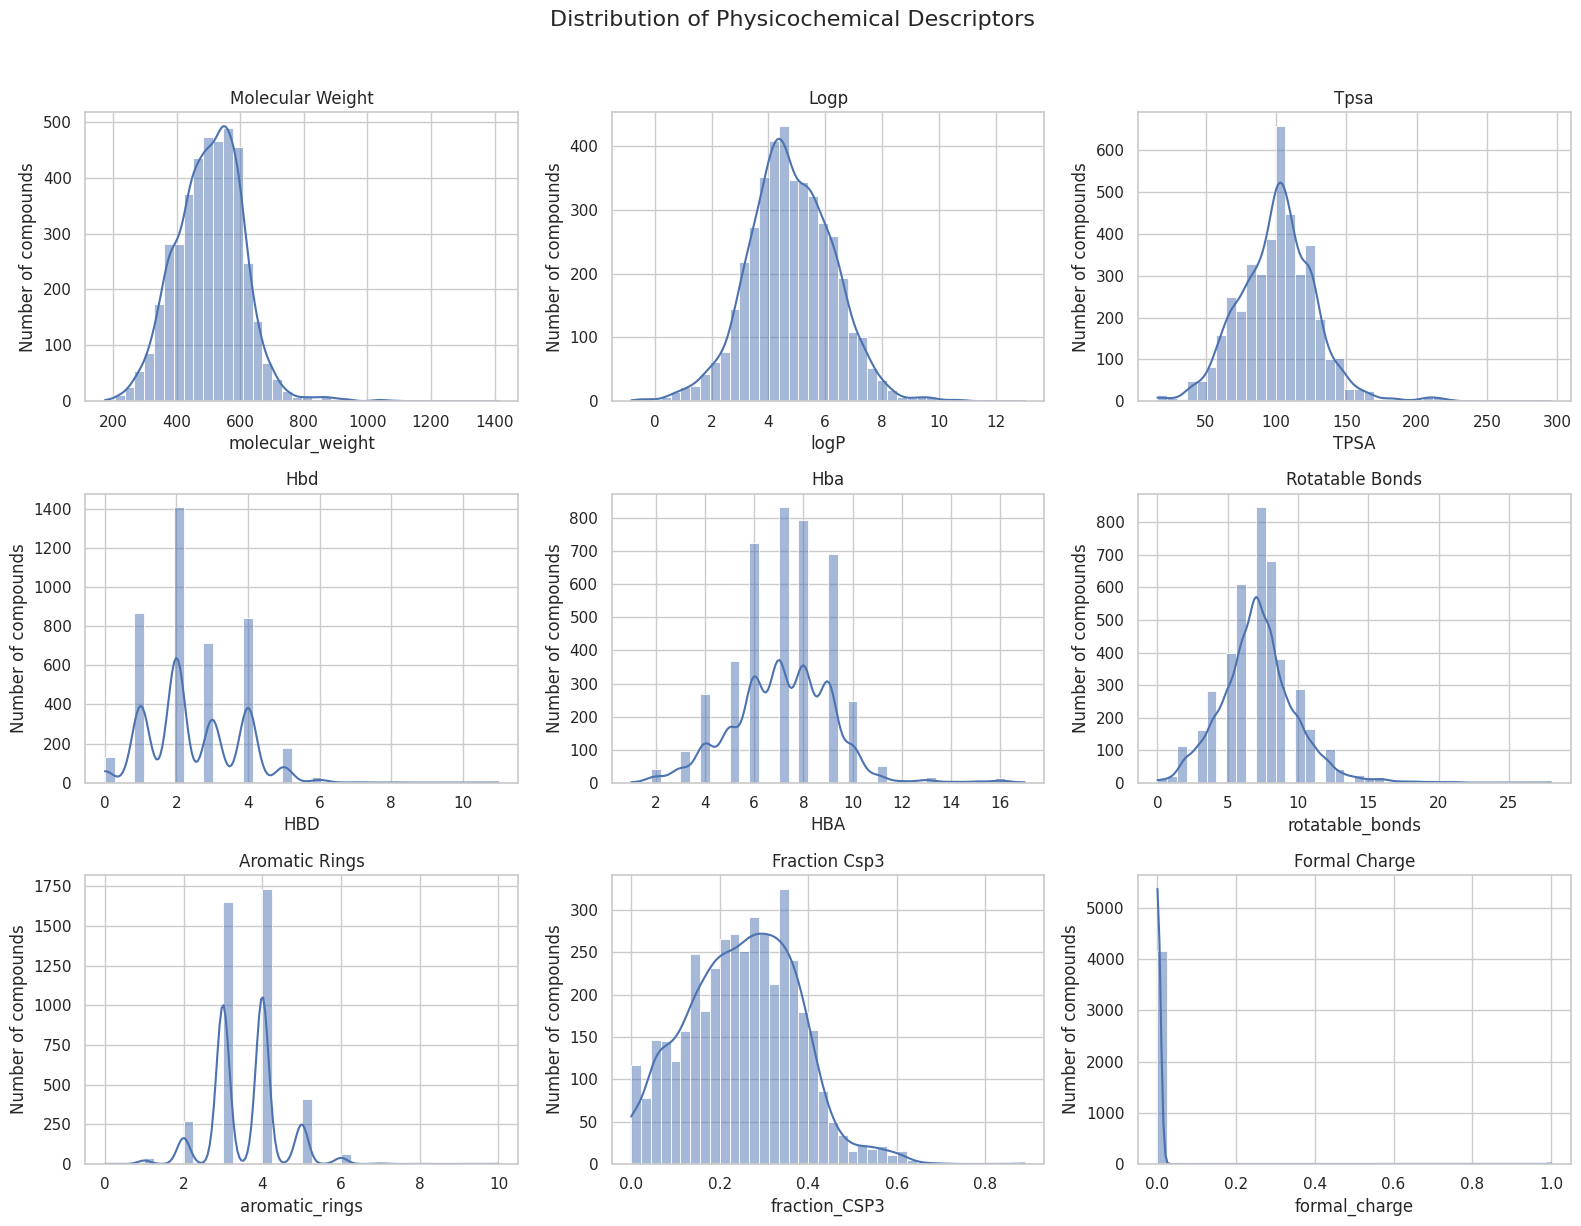

In [ ]:

# PHASE 3 — STEP 5
# Descriptor distribution visualisation

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, descriptor in zip(axes.flatten(), descriptor_columns):

    sns.histplot(
        data=unique_parent_df,
        x=descriptor,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(descriptor.replace("_", " ").title())
    ax.set_xlabel(descriptor)
    ax.set_ylabel("Number of compounds")

plt.suptitle(
    "Distribution of Physicochemical Descriptors",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


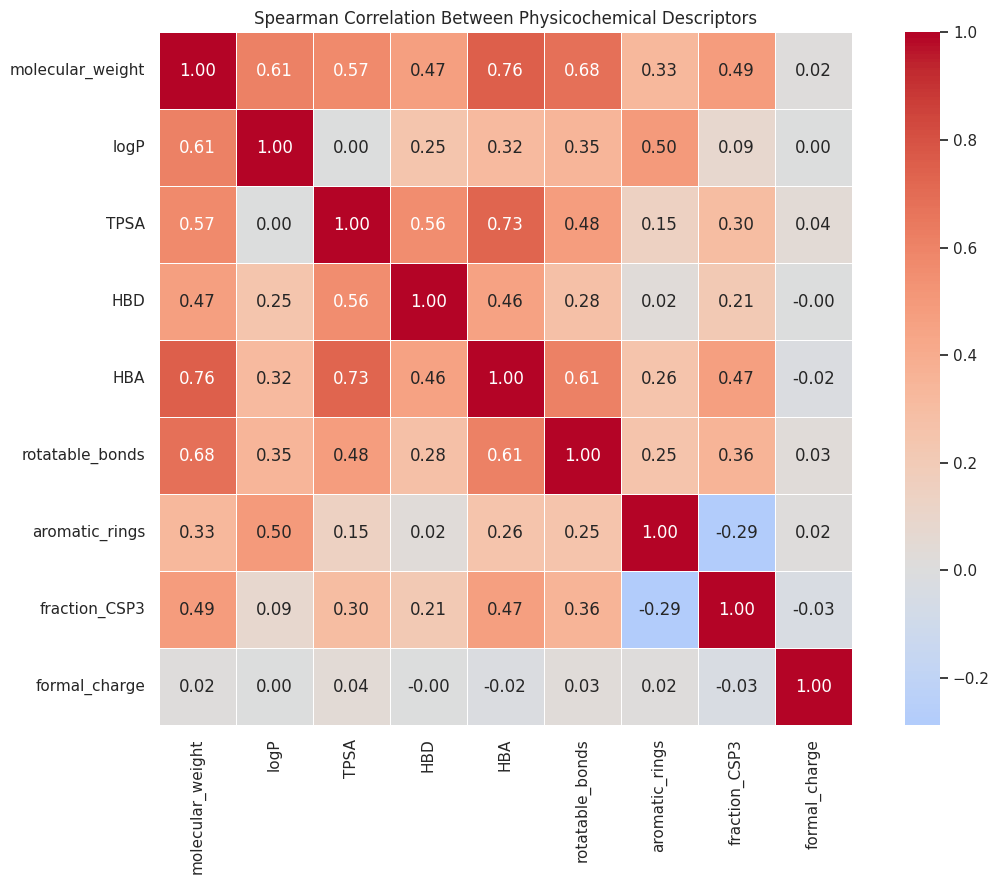

SPEARMAN CORRELATION MATRIX


,molecular_weight,logP,TPSA,HBD,HBA,rotatable_bonds,aromatic_rings,fraction_CSP3,formal_charge
molecular_weight,1.000,0.610,0.568,0.471,0.756,0.681,0.328,0.488,0.016
logP,0.610,1.000,0.002,0.247,0.319,0.351,0.502,0.085,0.001
TPSA,0.568,0.002,1.000,0.560,0.726,0.480,0.148,0.299,0.042
HBD,0.471,0.247,0.560,1.000,0.460,0.280,0.025,0.213,-0.001
HBA,0.756,0.319,0.726,0.460,1.000,0.613,0.258,0.468,-0.021
rotatable_bonds,0.681,0.351,0.480,0.280,0.613,1.000,0.252,0.355,0.026
aromatic_rings,0.328,0.502,0.148,0.025,0.258,0.252,1.000,-0.288,0.018
fraction_CSP3,0.488,0.085,0.299,0.213,0.468,0.355,-0.288,1.000,-0.033
formal_charge,0.016,0.001,0.042,-0.001,-0.021,0.026,0.018,-0.033,1.000


In [ ]:

# PHASE 3 — STEP 6
# Spearman correlation analysis

import matplotlib.pyplot as plt
import seaborn as sns

spearman_corr = unique_parent_df[
    descriptor_columns
].corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Between Physicochemical Descriptors")
plt.tight_layout()
plt.show()

print("SPEARMAN CORRELATION MATRIX")
display(spearman_corr.round(3))


In [ ]:

# PHASE 3 — STEP 7
# Identify highly correlated descriptor pairs

import numpy as np
import pandas as pd

correlation_threshold = 0.70

# Extract upper triangle to avoid duplicate pairs
upper_triangle = spearman_corr.where(
    np.triu(np.ones(spearman_corr.shape), k=1).astype(bool)
)

correlated_pairs = (
    upper_triangle.stack()
    .reset_index()
)

correlated_pairs.columns = [
    "descriptor_1",
    "descriptor_2",
    "spearman_correlation"
]

correlated_pairs["absolute_correlation"] = (
    correlated_pairs["spearman_correlation"].abs()
)

correlated_pairs = correlated_pairs[
    correlated_pairs["absolute_correlation"] >= correlation_threshold
].sort_values(
    "absolute_correlation",
    ascending=False
).reset_index(drop=True)

print("HIGHLY CORRELATED DESCRIPTOR PAIRS")
print("=" * 60)
print("Correlation threshold:", correlation_threshold)
print("Number of highly correlated pairs:", len(correlated_pairs))

display(correlated_pairs)


HIGHLY CORRELATED DESCRIPTOR PAIRS
Correlation threshold: 0.7
Number of highly correlated pairs: 2


,descriptor_1,descriptor_2,spearman_correlation,absolute_correlation
0,molecular_weight,HBA,0.756101,0.756101
1,TPSA,HBA,0.725565,0.725565


In [ ]:

# PHASE 3 — STEP 8
# Construct the physicochemical descriptor feature dataset

descriptor_feature_df = unique_parent_df[
    ["parent_smiles"] + descriptor_columns
].copy()

# Reset index
descriptor_feature_df = descriptor_feature_df.reset_index(drop=True)

# Dataset integrity audit
print("PHYSICOCHEMICAL FEATURE DATASET AUDIT")
print("=" * 60)

print("Total parent structures:", len(descriptor_feature_df))
print("Unique parent structures:", descriptor_feature_df["parent_smiles"].nunique())
print("Number of descriptors:", len(descriptor_columns))
print("Missing values:", descriptor_feature_df.isna().sum().sum())
print(
    "Infinite values:",
    np.isinf(
        descriptor_feature_df[descriptor_columns].to_numpy()
    ).sum()
)

print(
    "Duplicate parent structures:",
    descriptor_feature_df["parent_smiles"].duplicated().sum()
)

print("\nFEATURE DATASET SHAPE:")
print(descriptor_feature_df.shape)

print("\nFEATURE DATASET PREVIEW:")
display(descriptor_feature_df.head())

print("\nDESCRIPTOR COLUMN NAMES:")
print(descriptor_feature_df.columns.tolist())


PHYSICOCHEMICAL FEATURE DATASET AUDIT
Total parent structures: 4171
Unique parent structures: 4171
Number of descriptors: 9
Missing values: 0
Infinite values: 0
Duplicate parent structures: 0

FEATURE DATASET SHAPE:
(4171, 10)

FEATURE DATASET PREVIEW:


,parent_smiles,molecular_weight,logP,TPSA,HBD,HBA,rotatable_bonds,aromatic_rings,fraction_CSP3,formal_charge
0,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,446.910,4.27560,68.74,1,7,8,3,0.363636,0
1,C#Cc1cccc(Nc2c(C#N)cnc3cc(OCCOC)c(OCCOC)cc23)c1,417.465,3.88178,85.63,1,7,10,3,0.250000,0
2,O=C(CCc1c(SSc2[nH]c3ccccc3c2CCC(=O)NCc2ccccc2)...,618.828,7.94660,89.78,4,4,13,6,0.166667,0
3,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN...,485.947,4.39150,88.61,2,7,9,3,0.291667,0
4,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)c(C#N)cnc2cc1...,509.969,4.86818,99.51,2,7,9,3,0.269231,0



DESCRIPTOR COLUMN NAMES:
['parent_smiles', 'molecular_weight', 'logP', 'TPSA', 'HBD', 'HBA', 'rotatable_bonds', 'aromatic_rings', 'fraction_CSP3', 'formal_charge']


In [ ]:

# PHASE 3 — STEP 9A
# Initialise Morgan fingerprint generator

from rdkit.Chem import rdFingerprintGenerator

MORGAN_RADIUS = 2
MORGAN_FP_SIZE = 2048

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=MORGAN_RADIUS,
    fpSize=MORGAN_FP_SIZE
)

print("MORGAN FINGERPRINT CONFIGURATION")
print("=" * 50)
print("Fingerprint type: Morgan")
print("Radius:", MORGAN_RADIUS)
print("Fingerprint size:", MORGAN_FP_SIZE)
print("Approximate ECFP equivalent: ECFP4")
print("Unique parent structures:", len(descriptor_feature_df))


MORGAN FINGERPRINT CONFIGURATION
Fingerprint type: Morgan
Radius: 2
Fingerprint size: 2048
Approximate ECFP equivalent: ECFP4
Unique parent structures: 4171


In [ ]:

# PHASE 3 — STEP 9B
# Generate Morgan fingerprints for all parent structures

from rdkit import DataStructs
import numpy as np

morgan_fingerprints = [
    morgan_generator.GetFingerprint(mol)
    for mol in unique_parent_df["parent_mol"]
]

print("MORGAN FINGERPRINT GENERATION")
print("=" * 60)

print("Total fingerprints generated:", len(morgan_fingerprints))
print("Expected fingerprints:", len(descriptor_feature_df))

print("Fingerprint bit length:",
      morgan_fingerprints[0].GetNumBits())

print("First fingerprint on-bits:",
      len(morgan_fingerprints[0].GetOnBits()))

print("First fingerprint active bit positions:")
print(morgan_fingerprints[0].GetOnBits()[:20])


MORGAN FINGERPRINT GENERATION
Total fingerprints generated: 4171
Expected fingerprints: 4171
Fingerprint bit length: 2048
First fingerprint on-bits: 60
First fingerprint active bit positions:


In [ ]:

# PHASE 3 — STEP 9C
# Convert Morgan fingerprints into a NumPy matrix

morgan_array = np.zeros(
    (len(morgan_fingerprints), MORGAN_FP_SIZE),
    dtype=np.uint8
)

for i, fingerprint in enumerate(morgan_fingerprints):
    DataStructs.ConvertToNumpyArray(
        fingerprint,
        morgan_array[i]
    )

print("MORGAN FINGERPRINT MATRIX AUDIT")
print("=" * 60)

print("Matrix shape:", morgan_array.shape)
print("Data type:", morgan_array.dtype)
print("Minimum value:", morgan_array.min())
print("Maximum value:", morgan_array.max())

print("Unique values:", np.unique(morgan_array))

print("Total active bits:", int(morgan_array.sum()))

print("Average active bits per molecule:",
      round(morgan_array.sum(axis=1).mean(), 2))

print("First fingerprint active bit positions:",
      np.flatnonzero(morgan_array[0]).tolist()[:20])



MORGAN FINGERPRINT MATRIX AUDIT
Matrix shape: (4171, 2048)
Data type: uint8
Minimum value: 0
Maximum value: 1
Unique values: [0 1]
Total active bits: 274001
Average active bits per molecule: 65.69
First fingerprint active bit positions: [13, 80, 191, 216, 249, 329, 366, 378, 465, 489, 491, 523, 561, 653, 656, 673, 695, 699, 708, 747]


In [ ]:

# PHASE 3 — STEP 9D
# Morgan fingerprint quality control

fingerprint_active_counts = morgan_array.sum(axis=1)

unique_fingerprints = np.unique(
    morgan_array,
    axis=0
)

empty_fingerprints = np.sum(
    fingerprint_active_counts == 0
)

duplicate_fingerprints = (
    len(morgan_array) - len(unique_fingerprints)
)

print("MORGAN FINGERPRINT QUALITY AUDIT")
print("=" * 60)

print("Total fingerprints:", len(morgan_array))
print("Empty fingerprints:", empty_fingerprints)
print("Unique fingerprint vectors:", len(unique_fingerprints))
print("Duplicate fingerprint vectors:", duplicate_fingerprints)

print("\nACTIVE BIT DISTRIBUTION")
print(
    pd.Series(fingerprint_active_counts).describe()
)

print("\nBINARY VALUE VALIDATION")
print("Unique matrix values:", np.unique(morgan_array))
print("All values binary:",
      np.isin(morgan_array, [0, 1]).all())


MORGAN FINGERPRINT QUALITY AUDIT
Total fingerprints: 4171
Empty fingerprints: 0
Unique fingerprint vectors: 4035
Duplicate fingerprint vectors: 136

ACTIVE BIT DISTRIBUTION
count    4171.00000
mean       65.69192
std        13.38863
min        24.00000
25%        57.00000
50%        67.00000
75%        76.00000
max       121.00000
dtype: float64

BINARY VALUE VALIDATION
Unique matrix values: [0 1]
All values binary: True


In [ ]:

# PHASE 3 — STEP 9E
# Investigate duplicate Morgan fingerprint groups

fingerprint_group_df = pd.DataFrame({
    "parent_smiles": descriptor_feature_df["parent_smiles"],
    "fingerprint_key": [
        fingerprint.ToBitString()
        for fingerprint in morgan_fingerprints
    ]
})

fingerprint_group_summary = (
    fingerprint_group_df
    .groupby("fingerprint_key")
    .agg(
        number_of_parent_structures=("parent_smiles", "nunique"),
        parent_smiles=("parent_smiles", list)
    )
    .reset_index()
)

duplicate_fingerprint_groups = (
    fingerprint_group_summary[
        fingerprint_group_summary["number_of_parent_structures"] > 1
    ]
    .sort_values(
        "number_of_parent_structures",
        ascending=False
    )
    .reset_index(drop=True)
)

print("DUPLICATE FINGERPRINT GROUP AUDIT")
print("=" * 60)

print("Total fingerprint groups:",
      len(fingerprint_group_summary))

print("Groups containing multiple parent structures:",
      len(duplicate_fingerprint_groups))

print("Parent structures in duplicate groups:",
      duplicate_fingerprint_groups[
          "number_of_parent_structures"
      ].sum())

print("\nDUPLICATE GROUP SIZE DISTRIBUTION")

display(
    duplicate_fingerprint_groups[
        "number_of_parent_structures"
    ].value_counts().sort_index().rename("number_of_groups")
)

print("\nFIRST FIVE DUPLICATE GROUPS")

display(
    duplicate_fingerprint_groups.head(5)
)


DUPLICATE FINGERPRINT GROUP AUDIT
Total fingerprint groups: 4035
Groups containing multiple parent structures: 115
Parent structures in duplicate groups: 251

DUPLICATE GROUP SIZE DISTRIBUTION


,number_of_groups
number_of_parent_structures,
2,100
3,9
4,6



FIRST FIVE DUPLICATE GROUPS


,fingerprint_key,number_of_parent_structures,parent_smiles
0,0000000000000000000000000000000000000000010000...,4,[CCCCCCCCCCCC(=O)N[C@@H]1[C@H]2Oc3ccc(Oc4ccnc5...
1,0000000000000100000000000000000000000000000000...,4,[COc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCCCn1ccn...
2,0000000000000100000000000000000000000000000000...,4,[C#Cc1cccc(Nc2ncnc3cc(OCCCCCn4ccnc4[N+](=O)[O-...
3,0000000000000100000000000000000000000000000000...,4,[COc1cc2c(Nc3ccc(OCc4cccc(F)c4)c(Cl)c3)ncnc2cc...
4,0000010000000000000000000000000000000000000000...,4,[COc1ccccc1C(=O)NCc1ccc(-c2nn([C@H]3C=C[C@H](O...


In [ ]:

# PHASE 3 — STEP 10A
# Combine Morgan fingerprints and physicochemical descriptors

fingerprint_columns = [
    f"morgan_{i}" for i in range(MORGAN_FP_SIZE)
]

morgan_feature_df = pd.DataFrame(
    morgan_array,
    columns=fingerprint_columns
)

combined_feature_df = pd.concat(
    [
        descriptor_feature_df[
            ["parent_smiles"] + descriptor_columns
        ].reset_index(drop=True),
        morgan_feature_df.reset_index(drop=True)
    ],
    axis=1
)

print("COMBINED MOLECULAR FEATURE DATASET")
print("=" * 60)

print("Parent structures:", len(combined_feature_df))
print("Physicochemical descriptors:", len(descriptor_columns))
print("Morgan fingerprint features:", len(fingerprint_columns))
print("Total molecular features:",
      len(descriptor_columns) + len(fingerprint_columns))
print("Dataset shape:", combined_feature_df.shape)
print("Missing values:", combined_feature_df.isna().sum().sum())
print(
    "Duplicate parent structures:",
    combined_feature_df["parent_smiles"].duplicated().sum()
)

display(combined_feature_df.iloc[:, :15].head())


COMBINED MOLECULAR FEATURE DATASET
Parent structures: 4171
Physicochemical descriptors: 9
Morgan fingerprint features: 2048
Total molecular features: 2057
Dataset shape: (4171, 2058)
Missing values: 0
Duplicate parent structures: 0


,parent_smiles,molecular_weight,logP,TPSA,HBD,HBA,rotatable_bonds,aromatic_rings,fraction_CSP3,formal_charge,morgan_0,morgan_1,morgan_2,morgan_3,morgan_4
0,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,446.910,4.27560,68.74,1,7,8,3,0.363636,0,0,0,0,0,0
1,C#Cc1cccc(Nc2c(C#N)cnc3cc(OCCOC)c(OCCOC)cc23)c1,417.465,3.88178,85.63,1,7,10,3,0.250000,0,0,0,0,0,0
2,O=C(CCc1c(SSc2[nH]c3ccccc3c2CCC(=O)NCc2ccccc2)...,618.828,7.94660,89.78,4,4,13,6,0.166667,0,0,0,0,0,0
3,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN...,485.947,4.39150,88.61,2,7,9,3,0.291667,0,0,0,0,0,0
4,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)c(C#N)cnc2cc1...,509.969,4.86818,99.51,2,7,9,3,0.269231,0,0,0,0,0,0


In [ ]:

# PHASE 3 — STEP 10B
# Final combined feature integrity audit

expected_feature_count = 9 + MORGAN_FP_SIZE

# Verify parent structure alignment
descriptor_alignment = (
    combined_feature_df["parent_smiles"].tolist()
    == descriptor_feature_df["parent_smiles"].tolist()
)

fingerprint_alignment = (
    combined_feature_df["parent_smiles"].tolist()
    == unique_parent_df["parent_smiles"].tolist()
)

# Verify feature values
numeric_features = combined_feature_df.drop(
    columns=["parent_smiles"]
)

missing_count = numeric_features.isna().sum().sum()

infinite_count = np.isinf(
    numeric_features.to_numpy(dtype=float)
).sum()

fingerprint_values_valid = np.isin(
    combined_feature_df[fingerprint_columns].to_numpy(),
    [0, 1]
).all()

print("FINAL FEATURE INTEGRITY AUDIT")
print("=" * 60)

print("Parent structures:", len(combined_feature_df))
print("Expected numerical features:", expected_feature_count)
print("Actual numerical features:", numeric_features.shape[1])

print("Descriptor row alignment:", descriptor_alignment)
print("Fingerprint row alignment:", fingerprint_alignment)

print("Missing values:", missing_count)
print("Infinite values:", infinite_count)

print("Binary fingerprint validation:", fingerprint_values_valid)

print(
    "Duplicate parent structures:",
    combined_feature_df["parent_smiles"].duplicated().sum()
)

print("\nFINAL DATASET SHAPE:", combined_feature_df.shape)


FINAL FEATURE INTEGRITY AUDIT
Parent structures: 4171
Expected numerical features: 2057
Actual numerical features: 2057
Descriptor row alignment: True
Fingerprint row alignment: True
Missing values: 0
Infinite values: 0
Binary fingerprint validation: True
Duplicate parent structures: 0

FINAL DATASET SHAPE: (4171, 2058)



# Phase 3 — Molecular Feature Engineering

## Objective
To generate and validate numerical molecular representations for each unique EGFR parent structure using RDKit. These features will support downstream machine learning models for molecular activity prediction.

## 1. Physicochemical Descriptors

Nine molecular descriptors were calculated for each of the 4,171 unique parent structures:

- Molecular weight
- Crippen LogP
- Topological polar surface area (TPSA)
- Hydrogen bond donors (HBD)
- Hydrogen bond acceptors (HBA)
- Rotatable bonds
- Aromatic ring count
- Fraction of sp3-hybridised carbon atoms (Fraction Csp3)
- Formal charge

All nine descriptors were successfully calculated, with no missing or infinite values.

## 2. Descriptor Distribution and Quality Assessment

Descriptor distributions and extreme values were examined to understand the physicochemical characteristics of the dataset.

Key observations:
- Mean molecular weight: approximately 505.01 Da.
- Mean LogP: approximately 4.79.
- Mean TPSA: approximately 100.72 Å².
- Mean rotatable bonds: approximately 7.18.
- Mean Fraction Csp3: approximately 0.25.
- Most parent structures had a formal charge of zero.

Unusually high molecular weight, LogP and TPSA values were investigated. Chemically valid structures were retained rather than automatically excluded using drug-likeness thresholds.

## 3. Descriptor Correlation Analysis

Spearman rank correlation was used to examine relationships between physicochemical descriptors.

The strongest observed correlations included:
- Molecular weight and HBA: ρ = 0.756.
- TPSA and HBA: ρ = 0.726.

All nine descriptors were retained at this stage. Correlation alone was not considered sufficient justification for removing features; feature importance and redundancy will be evaluated during modelling.

## 4. Morgan Fingerprint Generation

Circular Morgan fingerprints were generated using RDKit with the following parameters:

- Radius: 2
- Fingerprint size: 2,048 bits
- Representation: approximately ECFP4
- Data type: binary (0/1)

A fingerprint was generated for each of the 4,171 unique parent structures.

Fingerprint quality assessment:
- Empty fingerprints: 0
- Unique fingerprint vectors: 4,035
- Average active bits per molecule: approximately 65.69
- Minimum active bits: 24
- Maximum active bits: 121

A total of 115 fingerprint groups contained multiple distinct parent structures, involving 251 parent structures. These groups were retained because identical hashed fingerprints do not establish identical chemical structures. No compounds were deleted on this basis.

## 5. Combined Molecular Feature Dataset

The physicochemical descriptors and Morgan fingerprints were combined into a single parent-level feature table.

Final composition:
- Unique parent structures: 4,171
- Physicochemical descriptors: 9
- Morgan fingerprint features: 2,048
- Total numerical features: 2,057
- Parent identity column: parent_smiles
- Final dataset shape: 4,171 × 2,058

## 6. Final Feature Integrity Audit

The combined feature dataset passed the following checks:

- Descriptor and fingerprint row alignment: passed.
- Missing numerical values: 0.
- Infinite numerical values: 0.
- Binary fingerprint validation: passed.
- Duplicate parent structures: 0.
- Expected and actual numerical feature counts: matched.

## 7. Methodological Considerations

- Descriptors and fingerprints were calculated from RDKit-reconstructed parent molecular structures.
- No automatic filtering based on Lipinski rules or extreme descriptor values was applied.
- Morgan fingerprints are hashed representations and may not uniquely distinguish every molecular structure.
- The feature table contains one row per unique parent structure.
- Molecular features have not yet been scaled or transformed.
- Any data-dependent preprocessing must be fitted using training data only to prevent information leakage.
- Parent structures must remain grouped during subsequent dataset splitting to prevent the same molecular identity from appearing in both training and testing sets.

## Phase 3 Conclusion

Molecular feature engineering was successfully completed for 4,171 unique EGFR parent structures. A validated feature matrix containing 2,057 numerical molecular features per parent structure was generated for subsequent integration with experimental bioactivity measurements.


In [ ]:

# PHASE 4 — STEP 1
# Activity-level dataset baseline audit

print("ACTIVITY-LEVEL DATASET AUDIT")
print("=" * 60)

print("\nDATASET DIMENSIONS")
print("Rows:", len(final_df))
print("Columns:", len(final_df.columns))

print("\nKEY IDENTIFIER COUNTS")

identifier_columns = [
    "activity_id",
    "molecule_chembl_id",
    "assay_chembl_id",
    "document_chembl_id"
]

for column in identifier_columns:
    if column in final_df.columns:
        print(
            f"{column}:",
            final_df[column].nunique()
        )
    else:
        print(f"{column}: NOT FOUND")

print("\nBIOACTIVITY FIELD AVAILABILITY")

activity_columns = [
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "pIC50",
    "canonical_smiles"
]

for column in activity_columns:
    if column in final_df.columns:
        print(
            f"{column}: "
            f"{final_df[column].notna().sum()} non-missing / "
            f"{final_df[column].isna().sum()} missing"
        )
    else:
        print(f"{column}: NOT FOUND")

print("\nDUPLICATE ACTIVITY IDs")

if "activity_id" in final_df.columns:
    print(
        "Duplicate activity IDs:",
        final_df["activity_id"].duplicated().sum()
    )

print("\nDATASET COLUMN NAMES")
print(final_df.columns.tolist())


ACTIVITY-LEVEL DATASET AUDIT

DATASET DIMENSIONS
Rows: 4482
Columns: 50

KEY IDENTIFIER COUNTS
activity_id: 4482
molecule_chembl_id: 4181
assay_chembl_id: 533
document_chembl_id: 445

BIOACTIVITY FIELD AVAILABILITY
standard_type: 4482 non-missing / 0 missing
standard_relation: 4482 non-missing / 0 missing
standard_value: 4482 non-missing / 0 missing
standard_units: 4482 non-missing / 0 missing
pIC50: 4482 non-missing / 0 missing
canonical_smiles: 4482 non-missing / 0 missing

DUPLICATE ACTIVITY IDs
Duplicate activity IDs: 0

DATASET COLUMN NAMES
['action_type', 'activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'bao_endpoint', 'bao_format', 'bao_label', 'canonical_smiles', 'data_validity_comment', 'data_validity_description', 'document_chembl_id', 'document_journal', 'document_year', 'ligand_efficiency', 'modality', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecu

In [ ]:

# PHASE 4 — STEP 2
# Bioactivity endpoint and pIC50 validation

import numpy as np
import pandas as pd

# Convert measurement fields to numeric for validation
ic50_values = pd.to_numeric(
    final_df["standard_value"], errors="coerce"
)

pic50_values = pd.to_numeric(
    final_df["pIC50"], errors="coerce"
)

# Recalculate pIC50 independently
recalculated_pic50 = 9 - np.log10(ic50_values)

# Compare original and recalculated values
pic50_difference = np.abs(
    pic50_values - recalculated_pic50
)

print("BIOACTIVITY ENDPOINT VALIDATION")
print("=" * 60)

print("\nSTANDARD TYPE DISTRIBUTION")
print(final_df["standard_type"].value_counts(dropna=False))

print("\nSTANDARD RELATION DISTRIBUTION")
print(final_df["standard_relation"].value_counts(dropna=False))

print("\nSTANDARD UNIT DISTRIBUTION")
print(final_df["standard_units"].value_counts(dropna=False))

print("\nNUMERICAL VALIDATION")
print("Non-numeric IC50 values:", ic50_values.isna().sum())
print("Non-numeric pIC50 values:", pic50_values.isna().sum())

print("Non-positive IC50 values:", (ic50_values <= 0).sum())
print("Non-finite IC50 values:", (~np.isfinite(ic50_values)).sum())
print("Non-finite pIC50 values:", (~np.isfinite(pic50_values)).sum())

print("\npIC50 CONVERSION VALIDATION")
print(
    "Maximum absolute conversion difference:",
    pic50_difference.max()
)

print(
    "Records matching conversion (tolerance 1e-6):",
    (pic50_difference <= 1e-6).sum()
)

print(
    "Records failing conversion:",
    (pic50_difference > 1e-6).sum()
)

print("\nFINAL pIC50 DISTRIBUTION")
print(pic50_values.describe())


BIOACTIVITY ENDPOINT VALIDATION

STANDARD TYPE DISTRIBUTION
standard_type
IC50    4482
Name: count, dtype: int64

STANDARD RELATION DISTRIBUTION
standard_relation
=    4482
Name: count, dtype: int64

STANDARD UNIT DISTRIBUTION
standard_units
nM    4482
Name: count, dtype: int64

NUMERICAL VALIDATION
Non-numeric IC50 values: 0
Non-numeric pIC50 values: 0
Non-positive IC50 values: 0
Non-finite IC50 values: 0
Non-finite pIC50 values: 0

pIC50 CONVERSION VALIDATION
Maximum absolute conversion difference: 1.7763568394002505e-15
Records matching conversion (tolerance 1e-6): 4482
Records failing conversion: 0

FINAL pIC50 DISTRIBUTION
count    4482.000000
mean        7.242603
std         1.284400
min         4.000000
25%         6.259637
50%         7.365523
75%         8.301030
max        11.000000
Name: pIC50, dtype: float64


In [ ]:

# PHASE 4 — STEP 3
# Compound-level measurement audit

compound_measurement_audit = (
    final_df.groupby("molecule_chembl_id")
    .agg(
        activity_record_count=("activity_id", "count"),
        unique_assay_count=("assay_chembl_id", "nunique"),
        unique_publication_count=("document_chembl_id", "nunique"),
        unique_pic50_values=("pIC50", "nunique"),
        mean_pic50=("pIC50", "mean"),
        std_pic50=("pIC50", "std"),
        min_pic50=("pIC50", "min"),
        max_pic50=("pIC50", "max")
    )
    .reset_index()
)

# Classify compounds by number of activity records
measurement_distribution = (
    compound_measurement_audit["activity_record_count"]
    .value_counts()
    .sort_index()
)

# Identify compounds with repeated activity records
repeated_compounds = compound_measurement_audit[
    compound_measurement_audit["activity_record_count"] > 1
].copy()

# Identify compounds with different measured pIC50 values
variable_activity_compounds = compound_measurement_audit[
    compound_measurement_audit["unique_pic50_values"] > 1
].copy()

print("COMPOUND-LEVEL MEASUREMENT AUDIT")
print("=" * 60)

print("\nMEASUREMENT DISTRIBUTION")
print(measurement_distribution.to_string())

print("\nSUMMARY")
print("Unique compounds:", len(compound_measurement_audit))
print("Compounds with repeated records:", len(repeated_compounds))
print(
    "Compounds with multiple pIC50 values:",
    len(variable_activity_compounds)
)
print(
    "Compounds measured in multiple assays:",
    (compound_measurement_audit["unique_assay_count"] > 1).sum()
)
print(
    "Compounds measured in multiple publications:",
    (compound_measurement_audit["unique_publication_count"] > 1).sum()
)

print("\nREPEATED COMPOUND ACTIVITY VARIATION")

if len(variable_activity_compounds) > 0:
    print(
        variable_activity_compounds[
            ["max_pic50", "min_pic50"]
        ].assign(
            pic50_range=lambda x: x["max_pic50"] - x["min_pic50"]
        )["pic50_range"].describe()
    )
else:
    print("No compounds with varying pIC50 values.")

print("\nTOP 10 MOST FREQUENTLY MEASURED COMPOUNDS")
print(
    compound_measurement_audit.sort_values(
        "activity_record_count", ascending=False
    ).head(10).to_string(index=False)
)


COMPOUND-LEVEL MEASUREMENT AUDIT

MEASUREMENT DISTRIBUTION
activity_record_count
1     4006
2      146
3       12
4        1
5        4
6        2
7        3
9        2
10       2
11       1
19       1
23       1

SUMMARY
Unique compounds: 4181
Compounds with repeated records: 175
Compounds with multiple pIC50 values: 154
Compounds measured in multiple assays: 78
Compounds measured in multiple publications: 49

REPEATED COMPOUND ACTIVITY VARIATION
count    154.000000
mean       0.928437
std        1.029955
min        0.000022
25%        0.257443
50%        0.561926
75%        1.218270
max        5.330694
Name: pic50_range, dtype: float64

TOP 10 MOST FREQUENTLY MEASURED COMPOUNDS
molecule_chembl_id  activity_record_count  unique_assay_count  unique_publication_count  unique_pic50_values  mean_pic50  std_pic50  min_pic50  max_pic50
         CHEMBL939                     23                  23                        22                   23    7.809566   1.288193   4.809668  10.000000
   

In [ ]:

# PHASE 4 — STEP 4
# Compound-assay level measurement audit

compound_assay_audit = (
    final_df.groupby(
        ["molecule_chembl_id", "assay_chembl_id"]
    )
    .agg(
        activity_record_count=("activity_id", "count"),
        unique_pic50_values=("pIC50", "nunique"),
        mean_pic50=("pIC50", "mean"),
        std_pic50=("pIC50", "std"),
        min_pic50=("pIC50", "min"),
        max_pic50=("pIC50", "max"),
        publication_count=("document_chembl_id", "nunique")
    )
    .reset_index()
)

# Identify compound-assay groups with repeated records
repeated_assay_groups = compound_assay_audit[
    compound_assay_audit["activity_record_count"] > 1
].copy()

# Identify groups with varying pIC50 values
variable_assay_groups = repeated_assay_groups[
    repeated_assay_groups["unique_pic50_values"] > 1
].copy()

# Calculate within-group pIC50 ranges
repeated_assay_groups["pic50_range"] = (
    repeated_assay_groups["max_pic50"]
    - repeated_assay_groups["min_pic50"]
)

print("COMPOUND–ASSAY LEVEL AUDIT")
print("=" * 60)

print("\nGROUP COUNTS")
print("Total compound-assay groups:", len(compound_assay_audit))
print("Groups with repeated records:", len(repeated_assay_groups))
print("Repeated groups with varying pIC50:", len(variable_assay_groups))
print(
    "Repeated groups with identical pIC50:",
    len(repeated_assay_groups) - len(variable_assay_groups)
)

print("\nREPEATED GROUP RECORD DISTRIBUTION")
print(
    repeated_assay_groups["activity_record_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nWITHIN-ASSAY pIC50 RANGE STATISTICS")
print(repeated_assay_groups["pic50_range"].describe())

print("\nPUBLICATION COUNTS WITHIN REPEATED GROUPS")
print(
    repeated_assay_groups["publication_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nTOP 10 REPEATED COMPOUND–ASSAY GROUPS")
print(
    repeated_assay_groups.sort_values(
        "activity_record_count",
        ascending=False
    ).head(10).to_string(index=False)
)


COMPOUND–ASSAY LEVEL AUDIT

GROUP COUNTS
Total compound-assay groups: 4376
Groups with repeated records: 97
Repeated groups with varying pIC50: 79
Repeated groups with identical pIC50: 18

REPEATED GROUP RECORD DISTRIBUTION
activity_record_count
2    91
3     5
6     1

WITHIN-ASSAY pIC50 RANGE STATISTICS
count    97.000000
mean      0.524203
std       0.727485
min       0.000000
25%       0.000389
50%       0.301030
75%       0.698970
max       3.600319
Name: pic50_range, dtype: float64

PUBLICATION COUNTS WITHIN REPEATED GROUPS
publication_count
1    97

TOP 10 REPEATED COMPOUND–ASSAY GROUPS
molecule_chembl_id assay_chembl_id  activity_record_count  unique_pic50_values  mean_pic50  std_pic50  min_pic50  max_pic50  publication_count  pic50_range
     CHEMBL5805378   CHEMBL5736995                      6                    5    8.256768   0.945596   6.397940   9.000000                  1     2.602060
     CHEMBL5903840   CHEMBL5738448                      3                    1    5.720

In [ ]:

# PHASE 4 — STEP 5
# Assay-level measurement audit

assay_measurement_audit = (
    final_df.groupby("assay_chembl_id")
    .agg(
        activity_record_count=("activity_id", "count"),
        unique_compounds=("molecule_chembl_id", "nunique"),
        unique_publications=("document_chembl_id", "nunique"),
        unique_pic50_values=("pIC50", "nunique"),
        mean_pic50=("pIC50", "mean"),
        std_pic50=("pIC50", "std"),
        min_pic50=("pIC50", "min"),
        max_pic50=("pIC50", "max"),
        assay_type_count=("assay_type", "nunique"),
        bao_format_count=("bao_format", "nunique")
    )
    .reset_index()
)

assay_measurement_audit["pic50_range"] = (
    assay_measurement_audit["max_pic50"]
    - assay_measurement_audit["min_pic50"]
)

print("ASSAY-LEVEL MEASUREMENT AUDIT")
print("=" * 60)

print("\nOVERALL COUNTS")
print("Unique assays:", len(assay_measurement_audit))
print(
    "Assays with multiple compounds:",
    (assay_measurement_audit["unique_compounds"] > 1).sum()
)
print(
    "Assays linked to multiple publications:",
    (assay_measurement_audit["unique_publications"] > 1).sum()
)
print(
    "Assays with multiple distinct pIC50 values:",
    (assay_measurement_audit["unique_pic50_values"] > 1).sum()
)

print("\nACTIVITY RECORDS PER ASSAY")
print(
    assay_measurement_audit["activity_record_count"]
    .describe()
)

print("\nASSAY RECORD COUNT DISTRIBUTION")
print(
    assay_measurement_audit["activity_record_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nCOMPOUNDS PER ASSAY")
print(
    assay_measurement_audit["unique_compounds"]
    .describe()
)

print("\nASSAY pIC50 RANGE DISTRIBUTION")
print(
    assay_measurement_audit["pic50_range"]
    .describe()
)

print("\nASSAYS WITH MULTIPLE PUBLICATIONS")
print(
    assay_measurement_audit[
        assay_measurement_audit["unique_publications"] > 1
    ].sort_values(
        "activity_record_count",
        ascending=False
    ).head(10).to_string(index=False)
)

print("\nTOP 10 ASSAYS BY ACTIVITY RECORD COUNT")
print(
    assay_measurement_audit.sort_values(
        "activity_record_count",
        ascending=False
    ).head(10).to_string(index=False)
)


ASSAY-LEVEL MEASUREMENT AUDIT

OVERALL COUNTS
Unique assays: 533
Assays with multiple compounds: 310
Assays linked to multiple publications: 0
Assays with multiple distinct pIC50 values: 300

ACTIVITY RECORDS PER ASSAY
count    533.000000
mean       8.409006
std       43.669444
min        1.000000
25%        1.000000
50%        2.000000
75%        7.000000
max      966.000000
Name: activity_record_count, dtype: float64

ASSAY RECORD COUNT DISTRIBUTION
activity_record_count
1      223
2       69
3       44
4       28
5       17
6       14
7       18
8       13
9       13
10      12
11       3
12       5
13      11
14       5
15       1
16       2
17       3
18       2
19       3
20       1
21       6
22       4
23       1
24       6
25       3
26       1
28       2
29       2
30       2
33       2
37       2
40       1
41       1
42       1
44       1
45       1
46       1
50       1
54       1
60       1
82       1
85       1
94       1
106      1
173      1
966      1

COMPOUNDS PER A

In [ ]:

# PHASE 4 — STEP 6
# Assay concentration and metadata consistency audit

total_records = len(final_df)

# Sort assays by activity record count
assay_concentration = (
    final_df["assay_chembl_id"]
    .value_counts()
    .rename_axis("assay_chembl_id")
    .reset_index(name="activity_records")
)

assay_concentration["record_percentage"] = (
    assay_concentration["activity_records"]
    / total_records * 100
)

assay_concentration["cumulative_percentage"] = (
    assay_concentration["record_percentage"].cumsum()
)

print("ASSAY CONCENTRATION AUDIT")
print("=" * 60)

for n in [1, 3, 5, 10, 20, 50]:
    records = assay_concentration.head(n)["activity_records"].sum()
    percentage = records / total_records * 100

    print(
        f"Top {n:2} assays: "
        f"{records:4} records "
        f"({percentage:.2f}%)"
    )

print("\nTOP 10 ASSAY CONCENTRATION")
print(assay_concentration.head(10).to_string(index=False))

# Check metadata consistency within each assay
metadata_columns = [
    "assay_type",
    "bao_format",
    "bao_label",
    "assay_description",
    "confidence_score",
    "target_chembl_id",
    "target_organism",
    "document_chembl_id"
]

available_metadata = [
    column for column in metadata_columns
    if column in final_df.columns
]

assay_metadata_audit = (
    final_df.groupby("assay_chembl_id")[available_metadata]
    .nunique(dropna=False)
)

print("\nASSAY METADATA CONSISTENCY")
print("=" * 60)

for column in available_metadata:
    inconsistent_count = (
        assay_metadata_audit[column] > 1
    ).sum()

    print(
        f"{column}: "
        f"{inconsistent_count} assays with multiple values"
    )

# Inspect metadata for the 10 largest assays
top_assay_ids = assay_concentration.head(10)["assay_chembl_id"]

top_assay_metadata = (
    final_df[
        final_df["assay_chembl_id"].isin(top_assay_ids)
    ][
        ["assay_chembl_id"] + available_metadata
    ]
    .drop_duplicates(subset="assay_chembl_id")
)

print("\nMETADATA OF TOP 10 ASSAYS")
print(top_assay_metadata.to_string(index=False))


ASSAY CONCENTRATION AUDIT
Top  1 assays:  966 records (21.55%)
Top  3 assays: 1245 records (27.78%)
Top  5 assays: 1424 records (31.77%)
Top 10 assays: 1716 records (38.29%)
Top 20 assays: 2098 records (46.81%)
Top 50 assays: 2801 records (62.49%)

TOP 10 ASSAY CONCENTRATION
assay_chembl_id  activity_records  record_percentage  cumulative_percentage
  CHEMBL5736995               966          21.552878              21.552878
  CHEMBL3705421               173           3.859884              25.412762
   CHEMBL944276               106           2.365016              27.777778
  CHEMBL5731823                94           2.097278              29.875056
  CHEMBL5730776                85           1.896475              31.771531
  CHEMBL5734361                82           1.829540              33.601071
  CHEMBL5731481                60           1.338688              34.939759
  CHEMBL3625155                54           1.204819              36.144578
  CHEMBL5737421                50       

In [ ]:

# PHASE 4 — STEP 7
# Experimental protocol diversity audit

# One metadata row per assay
assay_protocol_df = (
    final_df.sort_values("assay_chembl_id")
    .drop_duplicates(subset="assay_chembl_id")
    [[
        "assay_chembl_id",
        "assay_description",
        "bao_format",
        "bao_label",
        "assay_type",
        "document_chembl_id",
        "document_year"
    ]]
    .copy()
)

# Attach assay-level record counts
assay_protocol_df = assay_protocol_df.merge(
    assay_measurement_audit[
        ["assay_chembl_id", "activity_record_count", "unique_compounds"]
    ],
    on="assay_chembl_id",
    how="left",
    validate="one_to_one"
)

# Normalise descriptions for exploratory keyword analysis
assay_protocol_df["description_text"] = (
    assay_protocol_df["assay_description"]
    .fillna("")
    .str.lower()
)

print("EXPERIMENTAL PROTOCOL DIVERSITY AUDIT")
print("=" * 60)

print("\nDESCRIPTION COMPLETENESS")
print(
    "Missing descriptions:",
    assay_protocol_df["assay_description"].isna().sum()
)
print(
    "Empty descriptions:",
    (assay_protocol_df["description_text"].str.strip() == "").sum()
)
print(
    "Descriptions containing TBD:",
    assay_protocol_df["description_text"].str.contains(
        r"\btbd\b", regex=True
    ).sum()
)

# Exploratory method keyword screening
method_keywords = {
    "TR-FRET / HTRF": r"tr[\s-]?fret|htrf|time[- ]resolved fluorescence",
    "ELISA": r"\belisa\b",
    "Radiometric / radioactive": r"radiometric|radioactive|33p|32p",
    "Fluorescence": r"fluorescen|fluorometric",
    "Luminescence": r"luminescen|luminescent",
    "Mass spectrometry": r"mass spectrom",
    "HotSpot": r"hotspot",
    "Kinase assay": r"kinase",
    "Binding assay": r"binding affinity|binding assay"
}

print("\nEXPLORATORY METHOD KEYWORD COUNTS")

for method, pattern in method_keywords.items():
    count = assay_protocol_df["description_text"].str.contains(
        pattern, regex=True, na=False
    ).sum()

    print(f"{method}: {count} assays")

print("\nPUBLICATION YEAR DISTRIBUTION")
print(
    assay_protocol_df["document_year"]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)

print("\nTOP 15 ASSAYS — COMPACT PROTOCOL REVIEW")

top_protocols = assay_protocol_df.sort_values(
    "activity_record_count",
    ascending=False
).head(15)

for _, row in top_protocols.iterrows():
    description = str(row["assay_description"])

    print("\nAssay:", row["assay_chembl_id"])
    print("Activity records:", row["activity_record_count"])
    print("Unique compounds:", row["unique_compounds"])
    print("Publication year:", row["document_year"])
    print("BAO format:", row["bao_format"])
    print(
        "Description:",
        description[:300].replace("\n", " ")
    )
    if len(description) > 300:
        print("[Description truncated for display]")


EXPERIMENTAL PROTOCOL DIVERSITY AUDIT

DESCRIPTION COMPLETENESS
Missing descriptions: 0
Empty descriptions: 0
Descriptions containing TBD: 4

EXPLORATORY METHOD KEYWORD COUNTS
TR-FRET / HTRF: 59 assays
ELISA: 43 assays
Radiometric / radioactive: 29 assays
Fluorescence: 25 assays
Luminescence: 28 assays
Mass spectrometry: 0 assays
HotSpot: 9 assays
Kinase assay: 110 assays
Binding assay: 6 assays

PUBLICATION YEAR DISTRIBUTION
document_year
1991.0     2
1994.0     3
1997.0     2
1998.0     4
2000.0     3
2001.0     2
2002.0     3
2003.0     3
2004.0    10
2005.0     3
2006.0    19
2007.0     7
2008.0     3
2009.0     1
2010.0     2
2011.0     5
2012.0     9
2013.0    24
2014.0    19
2015.0    22
2016.0    26
2017.0    29
2018.0    18
2019.0    35
2020.0    43
2021.0    66
2022.0    47
2023.0    48
2024.0    59
2025.0    16

TOP 15 ASSAYS — COMPACT PROTOCOL REVIEW

Assay: CHEMBL5736995
Activity records: 966
Unique compounds: 902
Publication year: 2021.0
BAO format: BAO_0000357
Descriptio

In [ ]:

# PHASE 4 — STEP 8
# Target, mutation and data-quality audit

print("TARGET AND DATA-QUALITY AUDIT")
print("=" * 60)

# 1. Target identity
target_columns = [
    "target_chembl_id",
    "target_pref_name",
    "target_organism",
    "target_tax_id",
    "confidence_score"
]

print("\nTARGET IDENTITY")

for column in target_columns:
    if column in final_df.columns:
        print(f"\n{column}:")
        print(final_df[column].value_counts(dropna=False).to_string())

# 2. Mutation annotation
mutation_columns = [
    "mutation_flag",
    "assay_variant_mutation",
    "assay_variant_accession"
]

print("\nMUTATION ANNOTATION")

for column in mutation_columns:
    if column in final_df.columns:
        print(f"\n{column}:")
        print(final_df[column].value_counts(dropna=False).head(20).to_string())

# 3. Data validity and duplicate flags
quality_columns = [
    "data_validity_comment",
    "potential_duplicate",
    "standard_flag"
]

print("\nDATA QUALITY FLAGS")

for column in quality_columns:
    if column in final_df.columns:
        print(f"\n{column}:")
        print(final_df[column].value_counts(dropna=False).to_string())

# 4. Parent structure mapping availability
print("\nPARENT STRUCTURE MAPPING READINESS")

print("Unique ChEMBL compounds in activity data:",
      final_df["molecule_chembl_id"].nunique())

print("Unique ChEMBL compounds in parent mapping:",
      parent_mapping_df["molecule_chembl_id"].nunique())

print("Unique parent structures in feature table:",
      descriptor_feature_df["parent_smiles"].nunique())

print("Unique parent structures in combined feature table:",
      combined_feature_df["parent_smiles"].nunique())

# Compare identifier sets without performing a merge
activity_ids = set(final_df["molecule_chembl_id"].dropna())
mapping_ids = set(parent_mapping_df["molecule_chembl_id"].dropna())

print("Activity compounds missing from parent mapping:",
      len(activity_ids - mapping_ids))

print("Parent mapping compounds absent from activity data:",
      len(mapping_ids - activity_ids))

feature_parent_keys = set(combined_feature_df["parent_smiles"].dropna())
mapping_parent_keys = set(parent_mapping_df["parent_smiles"].dropna())

print("Mapped parents missing from feature table:",
      len(mapping_parent_keys - feature_parent_keys))

print("Feature parents absent from activity parent mapping:",
      len(feature_parent_keys - mapping_parent_keys))


TARGET AND DATA-QUALITY AUDIT

TARGET IDENTITY

target_chembl_id:
target_chembl_id
CHEMBL203    4482

target_pref_name:
target_pref_name
Epidermal growth factor receptor    4482

target_organism:
target_organism
Homo sapiens    4482

target_tax_id:
target_tax_id
9606    4482

confidence_score:
confidence_score
9    4482

MUTATION ANNOTATION

mutation_flag:
mutation_flag
False    4482

assay_variant_mutation:
assay_variant_mutation
NaN    4482

assay_variant_accession:
assay_variant_accession
NaN    4482

DATA QUALITY FLAGS

data_validity_comment:
data_validity_comment
NaN    4482

potential_duplicate:
potential_duplicate
0    4482

standard_flag:
standard_flag
1    4482

PARENT STRUCTURE MAPPING READINESS
Unique ChEMBL compounds in activity data: 4181
Unique ChEMBL compounds in parent mapping: 4181
Unique parent structures in feature table: 4171
Unique parent structures in combined feature table: 4171
Activity compounds missing from parent mapping: 0
Parent mapping compounds absent fro

In [ ]:

# PHASE 4 — STEP 9
# Controlled bioactivity and molecular feature integration

# 1. Verify integration prerequisites
assert activity_parent_df["activity_id"].is_unique, \
    "Duplicate activity IDs detected."

assert combined_feature_df["parent_smiles"].is_unique, \
    "Duplicate parent structures in feature table."

assert activity_parent_df["parent_smiles"].notna().all(), \
    "Missing parent structures in activity data."

assert combined_feature_df["parent_smiles"].notna().all(), \
    "Missing parent structures in feature table."

# Preserve original activity identifiers and target values
original_activity_ids = activity_parent_df["activity_id"].copy()
original_pic50 = activity_parent_df["pIC50"].copy()

# 2. Perform validated many-to-one integration
integrated_activity_feature_df = activity_parent_df.merge(
    combined_feature_df,
    on="parent_smiles",
    how="left",
    validate="many_to_one",
    indicator=True
)

# 3. Evaluate join completeness
join_distribution = (
    integrated_activity_feature_df["_merge"]
    .value_counts()
)

matched_records = (
    integrated_activity_feature_df["_merge"] == "both"
).sum()

unmatched_records = (
    integrated_activity_feature_df["_merge"] == "left_only"
).sum()

# 4. Verify activity record preservation
activity_id_alignment = (
    integrated_activity_feature_df["activity_id"].equals(
        original_activity_ids
    )
)

pic50_preservation = np.allclose(
    integrated_activity_feature_df["pIC50"].to_numpy(),
    original_pic50.to_numpy(),
    equal_nan=True
)

# 5. Final integration audit
print("BIOACTIVITY–FEATURE INTEGRATION AUDIT")
print("=" * 60)

print("\nINPUT DATASETS")
print("Activity records:", len(activity_parent_df))
print("Unique parent structures:", combined_feature_df["parent_smiles"].nunique())
print("Molecular numerical features:", combined_feature_df.shape[1] - 1)

print("\nJOIN RESULTS")
print("Matched activity records:", matched_records)
print("Unmatched activity records:", unmatched_records)
print("Join distribution:")
print(join_distribution.to_string())

print("\nDATA PRESERVATION")
print("Activity record count preserved:",
      len(integrated_activity_feature_df) == len(activity_parent_df))

print("Activity ID alignment:", activity_id_alignment)
print("Original pIC50 values preserved:", pic50_preservation)

print("\nINTEGRATED DATASET")
print("Shape:", integrated_activity_feature_df.drop(
    columns="_merge"
).shape)

print("Unique activity IDs:",
      integrated_activity_feature_df["activity_id"].nunique())

print("Unique ChEMBL compounds:",
      integrated_activity_feature_df["molecule_chembl_id"].nunique())

print("Unique parent structures:",
      integrated_activity_feature_df["parent_smiles"].nunique())

# Remove temporary join indicator after recording audit
integrated_activity_feature_df.drop(
    columns="_merge",
    inplace=True
)


BIOACTIVITY–FEATURE INTEGRATION AUDIT

INPUT DATASETS
Activity records: 4482
Unique parent structures: 4171
Molecular numerical features: 2057

JOIN RESULTS
Matched activity records: 4482
Unmatched activity records: 0
Join distribution:
_merge
both          4482
left_only        0
right_only       0

DATA PRESERVATION
Activity record count preserved: True
Activity ID alignment: True
Original pIC50 values preserved: True

INTEGRATED DATASET
Shape: (4482, 2108)
Unique activity IDs: 4482
Unique ChEMBL compounds: 4181
Unique parent structures: 4171


In [ ]:

# PHASE 4 — STEP 10
# Integrated molecular feature integrity audit

# 1. Identify the original molecular feature columns
feature_columns = [
    column for column in combined_feature_df.columns
    if column != "parent_smiles"
]

descriptor_columns = [
    "molecular_weight",
    "logP",
    "TPSA",
    "HBD",
    "HBA",
    "rotatable_bonds",
    "aromatic_rings",
    "fraction_CSP3",
    "formal_charge"
]

fingerprint_columns = [
    column for column in feature_columns
    if column.startswith("morgan_")
]

# 2. Extract integrated feature matrix
integrated_feature_matrix = integrated_activity_feature_df[
    feature_columns
]

# 3. Missing and infinite value checks
missing_feature_values = integrated_feature_matrix.isna().sum().sum()

numeric_feature_matrix = integrated_feature_matrix.to_numpy(
    dtype=np.float64
)

infinite_feature_values = np.isinf(
    numeric_feature_matrix
).sum()

# 4. Numerical feature and binary fingerprint validation
all_features_numeric = all(
    pd.api.types.is_numeric_dtype(
        integrated_feature_matrix[column]
    )
    for column in feature_columns
)

binary_fingerprint_validation = (
    integrated_feature_matrix[fingerprint_columns]
    .isin([0, 1])
    .all()
    .all()
)

# 5. Verify feature-vector alignment against original feature table
reference_feature_matrix = (
    combined_feature_df
    .set_index("parent_smiles")[feature_columns]
)

expected_feature_matrix = reference_feature_matrix.loc[
    integrated_activity_feature_df["parent_smiles"]
].to_numpy()

actual_feature_matrix = integrated_feature_matrix.to_numpy()

feature_alignment = np.array_equal(
    actual_feature_matrix,
    expected_feature_matrix
)

# 6. Final integrity report
print("INTEGRATED FEATURE INTEGRITY AUDIT")
print("=" * 60)

print("\nFEATURE COUNTS")
print("Expected molecular features:", len(feature_columns))
print("Actual molecular features:", integrated_feature_matrix.shape[1])
print("Descriptor features:", len(descriptor_columns))
print("Morgan fingerprint features:", len(fingerprint_columns))

print("\nFEATURE QUALITY")
print("All features numerical:", all_features_numeric)
print("Missing feature values:", missing_feature_values)
print("Infinite feature values:", infinite_feature_values)
print("Binary fingerprint validation:", binary_fingerprint_validation)

print("\nFEATURE ALIGNMENT")
print("Feature vectors match original parent feature table:",
      feature_alignment)

print("\nDATASET STRUCTURE")
print("Integrated dataset shape:",
      integrated_activity_feature_df.shape)

print("Activity records:",
      integrated_activity_feature_df["activity_id"].nunique())

print("Unique parent structures:",
      integrated_activity_feature_df["parent_smiles"].nunique())

print("\nFINAL PASS/FAIL CHECKS")

checks = {
    "Expected feature count": len(feature_columns) == 2057,
    "Descriptor count": len(descriptor_columns) == 9,
    "Morgan fingerprint count": len(fingerprint_columns) == 2048,
    "All features numerical": all_features_numeric,
    "No missing feature values": missing_feature_values == 0,
    "No infinite feature values": infinite_feature_values == 0,
    "Binary fingerprints": binary_fingerprint_validation,
    "Feature-vector alignment": feature_alignment,
    "Activity records preserved": len(integrated_activity_feature_df) == 4482
}

for check, passed in checks.items():
    print(f"{check}: {'PASS' if passed else 'FAIL'}")

print("\nOVERALL RESULT:",
      "PASS" if all(checks.values()) else "FAIL")


INTEGRATED FEATURE INTEGRITY AUDIT

FEATURE COUNTS
Expected molecular features: 2057
Actual molecular features: 2057
Descriptor features: 9
Morgan fingerprint features: 2048

FEATURE QUALITY
All features numerical: True
Missing feature values: 0
Infinite feature values: 0
Binary fingerprint validation: True

FEATURE ALIGNMENT
Feature vectors match original parent feature table: True

DATASET STRUCTURE
Integrated dataset shape: (4482, 2108)
Activity records: 4482
Unique parent structures: 4171

FINAL PASS/FAIL CHECKS
Expected feature count: PASS
Descriptor count: PASS
Morgan fingerprint count: PASS
All features numerical: PASS
No missing feature values: PASS
No infinite feature values: PASS
Binary fingerprints: PASS
Feature-vector alignment: PASS
Activity records preserved: PASS

OVERALL RESULT: PASS


In [ ]:

# PHASE 5 — STEP 1A
# Assay comparability and cross-assay consistency audit

import pandas as pd
import numpy as np
from itertools import combinations

df = integrated_activity_feature_df.copy()

# --------------------------------------------------
# 1. Assay-level summary
# --------------------------------------------------

assay_summary = (
    df.groupby("assay_chembl_id")
    .agg(
        activity_records=("activity_id", "nunique"),
        parent_structures=("parent_smiles", "nunique"),
        chembl_compounds=("molecule_chembl_id", "nunique"),
        publications=("document_chembl_id", "nunique"),
        pic50_mean=("pIC50", "mean"),
        pic50_median=("pIC50", "median"),
        pic50_std=("pIC50", "std"),
        pic50_min=("pIC50", "min"),
        pic50_max=("pIC50", "max"),
        protocol_descriptions=("assay_description", "nunique"),
        assay_formats=("bao_format", "nunique")
    )
    .reset_index()
)

print("ASSAY-LEVEL SUMMARY")
print("=" * 65)
print("Total assays:", len(assay_summary))
print("Assays with multiple parent structures:",
      (assay_summary["parent_structures"] > 1).sum())
print("Assays with multiple protocol descriptions:",
      (assay_summary["protocol_descriptions"] > 1).sum())
print("Assays with multiple assay formats:",
      (assay_summary["assay_formats"] > 1).sum())

print("\nASSAY pIC50 DISTRIBUTION")
print(assay_summary[
    ["pic50_mean", "pic50_median", "pic50_std",
     "pic50_min", "pic50_max"]
].describe().round(3).to_string())

print("\nLARGEST ASSAYS")
print(
    assay_summary.sort_values(
        "activity_records", ascending=False
    ).head(10).round(3).to_string(index=False)
)

# --------------------------------------------------
# 2. Parent structures measured in multiple assays
# --------------------------------------------------

parent_assay_counts = (
    df.groupby("parent_smiles")
    .agg(
        number_of_assays=("assay_chembl_id", "nunique"),
        number_of_records=("activity_id", "nunique"),
        number_of_chembl_ids=("molecule_chembl_id", "nunique")
    )
    .reset_index()
)

multi_assay_parents = parent_assay_counts[
    parent_assay_counts["number_of_assays"] > 1
]

print("\nCROSS-ASSAY PARENT STRUCTURE OVERLAP")
print("=" * 65)
print("Total parent structures:", len(parent_assay_counts))
print("Parents tested in multiple assays:", len(multi_assay_parents))

print("\nNumber of assays per parent structure:")
print(
    parent_assay_counts["number_of_assays"]
    .value_counts()
    .sort_index()
    .to_string()
)

# --------------------------------------------------
# 3. Summarise repeated measurements within each
#    parent-structure / assay combination.
#
# Median is used ONLY for this diagnostic comparison.
# It is NOT yet our modelling-label aggregation policy.
# --------------------------------------------------

parent_assay_median = (
    df.groupby(["parent_smiles", "assay_chembl_id"])["pIC50"]
    .median()
    .unstack("assay_chembl_id")
)

# --------------------------------------------------
# 4. Compare assay pairs sharing the same parents
# --------------------------------------------------

pair_results = []

assay_ids = parent_assay_median.columns.tolist()

for assay_a, assay_b in combinations(assay_ids, 2):

    paired = parent_assay_median[[assay_a, assay_b]].dropna()

    if len(paired) >= 5:

        differences = paired[assay_a] - paired[assay_b]

        pair_results.append({
            "assay_a": assay_a,
            "assay_b": assay_b,
            "shared_parent_structures": len(paired),
            "median_signed_difference": differences.median(),
            "median_absolute_difference": differences.abs().median(),
            "spearman_correlation": paired[assay_a].corr(
                paired[assay_b], method="spearman"
            )
        })

pairwise_assay_comparison = pd.DataFrame(pair_results)

print("\nPAIRED CROSS-ASSAY COMPARISON")
print("=" * 65)
print("Assay pairs with at least 5 shared parent structures:",
      len(pairwise_assay_comparison))

if len(pairwise_assay_comparison) > 0:

    print("\nShared-parent structure counts:")
    print(
        pairwise_assay_comparison[
            "shared_parent_structures"
        ].describe().round(3).to_string()
    )

    print("\nAssay pairs with largest median absolute differences:")
    print(
        pairwise_assay_comparison.sort_values(
            "median_absolute_difference", ascending=False
        ).head(10).round(3).to_string(index=False)
    )

    print("\nAssay pairs with highest shared-parent overlap:")
    print(
        pairwise_assay_comparison.sort_values(
            "shared_parent_structures", ascending=False
        ).head(10).round(3).to_string(index=False)
    )

else:
    print("Insufficient shared-parent overlap for pairwise comparisons.")

print("\nAUDIT COMPLETE")


ASSAY-LEVEL SUMMARY
Total assays: 533
Assays with multiple parent structures: 310
Assays with multiple protocol descriptions: 0
Assays with multiple assay formats: 0

ASSAY pIC50 DISTRIBUTION
       pic50_mean  pic50_median  pic50_std  pic50_min  pic50_max
count     533.000       533.000    310.000    533.000    533.000
mean        6.856         6.859      0.567      6.425      7.289
std         1.227         1.260      0.429      1.261      1.402
min         4.000         4.000      0.000      4.000      4.000
25%         6.015         6.009      0.238      5.449      6.237
50%         6.810         6.810      0.476      6.276      7.268
75%         7.678         7.658      0.798      7.229      8.337
max        10.544        10.668      2.464     10.301     11.000

LARGEST ASSAYS
assay_chembl_id  activity_records  parent_structures  chembl_compounds  publications  pic50_mean  pic50_median  pic50_std  pic50_min  pic50_max  protocol_descriptions  assay_formats
  CHEMBL5736995          

In [ ]:

# PHASE 5 — STEP 1B
# Inspect experimental context of overlapping assay pairs

metadata_columns = [
    "assay_chembl_id",
    "assay_description",
    "assay_type",
    "bao_format",
    "bao_label",
    "document_chembl_id",
    "document_year",
    "document_journal",
    "target_pref_name",
    "confidence_score"
]

# The three pairs identified in Step 1A
selected_pairs = pairwise_assay_comparison.sort_values(
    "shared_parent_structures", ascending=False
).head(3)

print("OVERLAPPING ASSAY PAIRS")
print("=" * 75)

for _, pair in selected_pairs.iterrows():

    assay_a = pair["assay_a"]
    assay_b = pair["assay_b"]

    print("\n" + "=" * 75)
    print(f"PAIR: {assay_a} vs {assay_b}")
    print("Shared parent structures:",
          pair["shared_parent_structures"])
    print("Median signed difference:",
          round(pair["median_signed_difference"], 3))
    print("Median absolute difference:",
          round(pair["median_absolute_difference"], 3))
    print("Spearman correlation:",
          round(pair["spearman_correlation"], 3))

    for assay_id in [assay_a, assay_b]:

        assay_data = df[df["assay_chembl_id"] == assay_id]

        print("\nASSAY:", assay_id)

        metadata = (
            assay_data[metadata_columns]
            .drop_duplicates()
        )

        print("\nMetadata:")
        print(metadata.to_string(index=False))

    # Compare measurements for the same parent structures
    paired_values = (
        df[df["assay_chembl_id"].isin([assay_a, assay_b])]
        .groupby(["parent_smiles", "assay_chembl_id"])["pIC50"]
        .median()
        .unstack()
        .dropna()
    )

    paired_values["difference_A_minus_B"] = (
        paired_values[assay_a] - paired_values[assay_b]
    )

    print("\nSHARED COMPOUND MEASUREMENTS")
    print(
        paired_values[
            [assay_a, assay_b, "difference_A_minus_B"]
        ].round(3).to_string()
    )

    print("\nDifference summary:")
    print(
        paired_values["difference_A_minus_B"]
        .describe()
        .round(3).to_string()
    )

print("\nPAIR INSPECTION COMPLETE")


OVERLAPPING ASSAY PAIRS

PAIR: CHEMBL892951 vs CHEMBL892954
Shared parent structures: 12
Median signed difference: 0.855
Median absolute difference: 0.855
Spearman correlation: 0.72

ASSAY: CHEMBL892951

Metadata:
assay_chembl_id                                assay_description assay_type  bao_format             bao_label document_chembl_id  document_year document_journal                 target_pref_name  confidence_score
   CHEMBL892951 Inhibition of human EGFR in presence of 1 uM ATP          B BAO_0000357 single protein format      CHEMBL1147965         2007.0  Bioorg Med Chem Epidermal growth factor receptor                 9

ASSAY: CHEMBL892954

Metadata:
assay_chembl_id                                assay_description assay_type  bao_format             bao_label document_chembl_id  document_year document_journal                 target_pref_name  confidence_score
   CHEMBL892954 Inhibition of human EGFR in presence of 1 mM ATP          B BAO_0000357 single protein format      CHE

In [ ]:

# PHASE 5 — STEP 1C
# Assay coverage and single-assay modelling feasibility

# 1. Assay coverage
assay_coverage = assay_summary.sort_values(
    "activity_records", ascending=False
).copy()

total_records = len(df)

assay_coverage["record_percentage"] = (
    assay_coverage["activity_records"] / total_records * 100
)

assay_coverage["cumulative_record_percentage"] = (
    assay_coverage["record_percentage"].cumsum()
)

print("ASSAY COVERAGE")
print("=" * 65)

for threshold in [1, 5, 10, 20, 50, 100]:
    eligible = assay_coverage[
        assay_coverage["activity_records"] >= threshold
    ]

    print(
        f"Assays with >= {threshold:3} records:",
        f"{len(eligible):3}",
        "| Records covered:",
        int(eligible["activity_records"].sum())
    )

print("\nTOP 15 ASSAYS BY RECORD COUNT")

print(
    assay_coverage[
        [
            "assay_chembl_id",
            "activity_records",
            "parent_structures",
            "publications",
            "pic50_mean",
            "pic50_std",
            "record_percentage",
            "cumulative_record_percentage"
        ]
    ].head(15).round(3).to_string(index=False)
)

# 2. Evaluate the largest assay as a candidate
candidate_assay_id = "CHEMBL5736995"

candidate_df = df[
    df["assay_chembl_id"] == candidate_assay_id
].copy()

print("\nCANDIDATE SINGLE-ASSAY AUDIT")
print("=" * 65)

print("Assay ID:", candidate_assay_id)
print("Activity records:", len(candidate_df))
print("Unique parent structures:",
      candidate_df["parent_smiles"].nunique())
print("Unique ChEMBL compounds:",
      candidate_df["molecule_chembl_id"].nunique())
print("Unique publications:",
      candidate_df["document_chembl_id"].nunique())

print("\nTarget pIC50 distribution:")
print(candidate_df["pIC50"].describe().round(4).to_string())

print("\nRepeated parent structures:")
print(
    (candidate_df["parent_smiles"].value_counts() > 1).sum()
)

print("\nRepeated compound-assay groups:")
print(
    candidate_df.groupby(
        ["parent_smiles", "assay_chembl_id"]
    ).size().gt(1).sum()
)

# 3. Compare candidate assay against the full dataset
print("\nFULL DATASET VS CANDIDATE ASSAY")
print("=" * 65)

comparison = pd.DataFrame({
    "Full curated dataset": df["pIC50"].describe(),
    "Candidate assay": candidate_df["pIC50"].describe()
})

print(comparison.round(4).to_string())

# 4. Verify candidate assay protocol metadata
protocol_columns = [
    "assay_chembl_id",
    "assay_description",
    "assay_type",
    "bao_format",
    "document_chembl_id",
    "document_year",
    "document_journal",
    "confidence_score"
]

print("\nCANDIDATE ASSAY PROTOCOL")
print(
    candidate_df[protocol_columns]
    .drop_duplicates()
    .to_string(index=False)
)

print("\nSTEP 1C AUDIT COMPLETE")


ASSAY COVERAGE
Assays with >=   1 records: 533 | Records covered: 4482
Assays with >=   5 records: 169 | Records covered: 3877
Assays with >=  10 records:  94 | Records covered: 3361
Assays with >=  20 records:  47 | Records covered: 2744
Assays with >=  50 records:   9 | Records covered: 1670
Assays with >= 100 records:   3 | Records covered: 1245

TOP 15 ASSAYS BY RECORD COUNT
assay_chembl_id  activity_records  parent_structures  publications  pic50_mean  pic50_std  record_percentage  cumulative_record_percentage
  CHEMBL5736995               966                902             1       8.144      0.617             21.553                        21.553
  CHEMBL3705421               173                170             1       7.357      0.670              3.860                        25.413
   CHEMBL944276               106                106             1       8.088      1.399              2.365                        27.778
  CHEMBL5731823                94                 94          

In [ ]:
# PHASE 5 — STEP 1D
# Repeated measurements and potential endpoint censoring

candidate_df = df[
    df["assay_chembl_id"] == "CHEMBL5736995"
].copy()

# 1. Inspect pIC50 value frequency
print("PIC50 VALUE FREQUENCY")
print("=" * 65)

print(
    candidate_df["pIC50"]
    .value_counts()
    .sort_index()
    .tail(20)
    .to_string()
)

print("\nEXACT pIC50 = 9.0")
print(
    "Records:",
    int(candidate_df["pIC50"].eq(9.0).sum())
)

print(
    "Percentage:",
    round(candidate_df["pIC50"].eq(9.0).mean() * 100, 3)
)

# 2. Inspect original IC50 values and measurement metadata
measurement_columns = [
    "activity_id",
    "molecule_chembl_id",
    "parent_smiles",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "pIC50",
    "standard_text_value"
]

available_columns = [
    col for col in measurement_columns
    if col in candidate_df.columns
]

print("\nMEASUREMENT METADATA")
print("=" * 65)

print(
    candidate_df[available_columns]
    .sort_values("pIC50", ascending=False)
    .head(15)
    .to_string(index=False)
)

# 3. Characterise repeated parent structures
repeated_parents = (
    candidate_df.groupby("parent_smiles")
    .agg(
        record_count=("activity_id", "count"),
        unique_compounds=("molecule_chembl_id", "nunique"),
        unique_pic50=("pIC50", "nunique"),
        pic50_min=("pIC50", "min"),
        pic50_max=("pIC50", "max"),
        pic50_median=("pIC50", "median"),
        pic50_std=("pIC50", "std")
    )
)

repeated_parents = repeated_parents[
    repeated_parents["record_count"] > 1
].sort_values(
    ["record_count", "pic50_std"],
    ascending=False
)

print("\nREPEATED PARENT STRUCTURE SUMMARY")
print("=" * 65)

print("Repeated parent groups:", len(repeated_parents))
print(
    "Records belonging to repeated groups:",
    int(repeated_parents["record_count"].sum())
)

print("\nRepeated group size distribution:")
print(
    repeated_parents["record_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nRepeated parent measurement details:")
print(repeated_parents.round(4).to_string())

# 4. Inspect all records at the upper pIC50 boundary
print("\nUPPER-BOUNDARY MEASUREMENTS")
print("=" * 65)

boundary_records = candidate_df[
    candidate_df["pIC50"] == 9.0
]

print(
    boundary_records[available_columns]
    .sort_values("standard_value")
    .to_string(index=False)
)

print("\nSTEP 1D AUDIT COMPLETE")

PIC50 VALUE FREQUENCY
pIC50
7.698970      8
7.721246      5
7.744727      5
7.769551     10
7.795880     14
7.823909     10
7.853872     15
7.886057     24
7.920819     20
7.958607     21
8.000000     27
8.045757     25
8.096910     28
8.154902     40
8.221849     53
8.301030     61
8.397940     78
8.522879    130
8.698970    174
9.000000     50

EXACT pIC50 = 9.0
Records: 50
Percentage: 5.176

MEASUREMENT METADATA
 activity_id molecule_chembl_id                                                                               parent_smiles standard_type standard_relation  standard_value standard_units  pIC50  standard_text_value
    28405733      CHEMBL5786862    Cn1ccc2c([C@H](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C(F)(F)F)c4c3)C3=CN(C4(C)CC4)NN3)cccc2c1=O          IC50                 =             1.0             nM    9.0                  NaN
    28405730      CHEMBL5770582 Cn1ccc2c([C@H](Nc3cc(C#N)c4ncc(C#N)c(NCC(C)(C)C(F)(F)F)c4c3)C3=CN(C45CC(C4)C5)NN3)cccc2c1=O          IC50              

In [ ]:
# PHASE 5 — STEP 1E
# Trace repeated measurements to source metadata

candidate_df = df[
    df["assay_chembl_id"] == "CHEMBL5736995"
].copy()

keywords = [
    "activity", "molecule", "assay", "document",
    "source", "src", "comment", "variant",
    "standard", "record", "confidence"
]

metadata_columns = [
    col for col in candidate_df.columns
    if any(word in col.lower() for word in keywords)
]

# Explicitly include the measured bioactivity endpoint
for col in ["pIC50", "parent_smiles"]:
    if col in candidate_df.columns and col not in metadata_columns:
        metadata_columns.append(col)

print("AVAILABLE PROVENANCE COLUMNS")
print("=" * 65)
print(metadata_columns)

# Identify repeated parent structures
parent_counts = candidate_df["parent_smiles"].value_counts()
repeated_smiles = parent_counts[parent_counts > 1].index

repeated_records = candidate_df[
    candidate_df["parent_smiles"].isin(repeated_smiles)
].copy()

# Inspect the six-record group
six_record_smiles = parent_counts[parent_counts == 6].index[0]

six_record_group = repeated_records[
    repeated_records["parent_smiles"] == six_record_smiles
]

print("\nSIX-RECORD GROUP — COMPLETE AVAILABLE METADATA")
print("=" * 65)

print(
    six_record_group[metadata_columns]
    .sort_values("pIC50")
    .to_string(index=False)
)

# Summarise source identifiers
print("\nSOURCE METADATA DISTRIBUTION")
print("=" * 65)

for col in [
    "document_chembl_id",
    "assay_chembl_id",
    "src_id",
    "src_assay_id",
    "activity_comment",
    "data_validity_comment",
    "standard_text_value"
]:
    if col in repeated_records.columns:
        print(f"\n{col}")
        print(
            repeated_records[col]
            .value_counts(dropna=False)
            .head(15)
            .to_string()
        )

# Identifier integrity
print("\nIDENTIFIER INTEGRITY")
print("=" * 65)

for col in [
    "activity_id",
    "molecule_chembl_id",
    "src_id",
    "src_assay_id"
]:
    if col in repeated_records.columns:
        print(
            col,
            "| unique:", repeated_records[col].nunique(dropna=True),
            "| missing:", repeated_records[col].isna().sum()
        )

print("\nSTEP 1E AUDIT COMPLETE")

AVAILABLE PROVENANCE COLUMNS
['activity_comment', 'activity_id', 'activity_properties', 'assay_chembl_id', 'assay_description', 'assay_type', 'assay_variant_accession', 'assay_variant_mutation', 'data_validity_comment', 'document_chembl_id', 'document_journal', 'document_year', 'molecule_chembl_id', 'molecule_pref_name', 'parent_molecule_chembl_id', 'record_id', 'src_id', 'standard_flag', 'standard_relation', 'standard_text_value', 'standard_type', 'standard_units', 'standard_upper_value', 'standard_value', 'confidence_score', 'pIC50', 'parent_smiles']

SIX-RECORD GROUP — COMPLETE AVAILABLE METADATA
 activity_comment  activity_id activity_properties assay_chembl_id                                                                                                                                                                                                                                                                                                                                       

In [ ]:
import requests

activity_ids = six_record_group["activity_id"].tolist()

print("RAW CHEMBL ACTIVITY RECORDS")
print("=" * 70)

for activity_id in activity_ids:
    url = (
        "https://www.ebi.ac.uk/chembl/api/data/"
        f"activity/{activity_id}.json"
    )

    response = requests.get(url, timeout=30)
    response.raise_for_status()
    record = response.json()

    print(f"\nActivity ID: {activity_id}")

    for field in [
        "activity_id",
        "molecule_chembl_id",
        "assay_chembl_id",
        "document_chembl_id",
        "record_id",
        "src_id",
        "activity_comment",
        "activity_properties",
        "standard_type",
        "standard_relation",
        "standard_value",
        "standard_units",
        "standard_text_value",
        "standard_upper_value",
    ]:
        print(f"{field}: {record.get(field)}")

print("\nRAW RECORD INSPECTION COMPLETE")

RAW CHEMBL ACTIVITY RECORDS

Activity ID: 28403330
activity_id: 28403330
molecule_chembl_id: CHEMBL5805378
assay_chembl_id: CHEMBL5736995
document_chembl_id: CHEMBL5728555
record_id: 4509570
src_id: 37
activity_comment: 1058663
activity_properties: []
standard_type: IC50
standard_relation: =
standard_value: 1.0
standard_units: nM
standard_text_value: None
standard_upper_value: None

Activity ID: 28403333
activity_id: 28403333
molecule_chembl_id: CHEMBL5805378
assay_chembl_id: CHEMBL5736995
document_chembl_id: CHEMBL5728555
record_id: 4509570
src_id: 37
activity_comment: 1058664
activity_properties: []
standard_type: IC50
standard_relation: =
standard_value: 400.0
standard_units: nM
standard_text_value: None
standard_upper_value: None

Activity ID: 28403363
activity_id: 28403363
molecule_chembl_id: CHEMBL5805378
assay_chembl_id: CHEMBL5736995
document_chembl_id: CHEMBL5728555
record_id: 4509570
src_id: 37
activity_comment: 1058674
activity_properties: []
standard_type: IC50
standard_rel

In [ ]:
import requests
import json

endpoints = {
    "DOCUMENT": (
        "https://www.ebi.ac.uk/chembl/api/data/"
        "document/CHEMBL5728555.json"
    ),
    "SOURCE": (
        "https://www.ebi.ac.uk/chembl/api/data/"
        "source/37.json"
    ),
    "ASSAY": (
        "https://www.ebi.ac.uk/chembl/api/data/"
        "assay/CHEMBL5736995.json"
    )
}

for label, url in endpoints.items():
    print(f"\n{label} METADATA")
    print("=" * 70)

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    data = response.json()
    print(json.dumps(data, indent=2))


DOCUMENT METADATA
{
  "abstract": "",
  "authors": null,
  "chembl_release": {
    "chembl_release": "CHEMBL_36",
    "creation_date": "2025-07-28"
  },
  "contact": null,
  "doc_type": "PATENT",
  "document_chembl_id": "CHEMBL5728555",
  "doi": null,
  "doi_chembl": null,
  "first_page": null,
  "issue": null,
  "journal": null,
  "journal_full_title": null,
  "last_page": null,
  "patent_id": "US-11066414-B2",
  "pubmed_id": null,
  "src_id": 37,
  "title": "Cot modulators and methods of use thereof",
  "volume": null,
  "year": 2021
}

SOURCE METADATA
{
  "src_comment": "We have worked with the BindingDB team to integrate the bioactivity data that they have extracted from more than 1000 granted US patents published from 2013 onwards (https://www.bindingdb.org/bind/ByPatent.jsp) into ChEMBL.",
  "src_description": "BindingDB Patent Bioactivity Data",
  "src_id": 37,
  "src_short_name": "BINDINGDB",
  "src_url": "https://www.bindingdb.org/rwd/bind/index.jsp"
}

ASSAY METADATA
{
  "ai

In [ ]:
import requests
import json

url = (
    "https://www.ebi.ac.uk/chembl/api/data/"
    "molecule/CHEMBL5805378.json"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

molecule_record = response.json()

print("MOLECULE IDENTIFICATION")
print("=" * 70)

for field in [
    "molecule_chembl_id",
    "pref_name",
    "molecule_type",
    "max_phase",
    "molecule_synonyms",
    "molecule_properties",
    "molecule_structures"
]:
    print(f"\n{field}:")
    print(json.dumps(molecule_record.get(field), indent=2))

MOLECULE IDENTIFICATION

molecule_chembl_id:
"CHEMBL5805378"

pref_name:
null

molecule_type:
null

max_phase:
null

molecule_synonyms:
[]

molecule_properties:
{
  "alogp": "5.52",
  "aromatic_rings": 3,
  "full_molformula": "C31H37ClN8OS",
  "full_mwt": "605.21",
  "hba": 10,
  "hbd": 4,
  "heavy_atoms": 42,
  "mw_freebase": "605.21",
  "np_likeness_score": "-0.93",
  "num_ro5_violations": 2,
  "psa": "100.51",
  "qed_weighted": "0.26",
  "ro3_pass": "N",
  "rtb": 8
}

molecule_structures:
{
  "canonical_smiles": "CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(NC(C3=CN(C4CC4)NN3)c3csc4c3CCN(C3COC3)C4)cc12",
  "molfile": "BDBM505417\n     RDKit          2D\n\n 42 48  0  0  0  0  0  0  0  0999 V2000\n    5.2500   -2.7990    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0\n    5.2500   -1.2990    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0\n    5.2500    0.2010    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0\n    6.7500   -1.2990    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0\n    3.7500   -1.2990   

In [ ]:
# PHASE 5 — STEP 1F
# Quantify within-parent variation in the candidate assay

import numpy as np
import pandas as pd

candidate_df = df[
    df["assay_chembl_id"] == "CHEMBL5736995"
].copy()

repeat_summary = (
    candidate_df
    .groupby("parent_smiles")
    .agg(
        record_count=("pIC50", "size"),
        unique_compounds=("molecule_chembl_id", "nunique"),
        unique_source_records=("record_id", "nunique"),
        unique_documents=("document_chembl_id", "nunique"),
        mean_pIC50=("pIC50", "mean"),
        median_pIC50=("pIC50", "median"),
        std_pIC50=("pIC50", "std"),
        min_pIC50=("pIC50", "min"),
        max_pIC50=("pIC50", "max")
    )
    .reset_index()
)

repeat_summary["pIC50_range"] = (
    repeat_summary["max_pIC50"]
    - repeat_summary["min_pIC50"]
)

repeated = repeat_summary[
    repeat_summary["record_count"] > 1
].copy()

print("REPEATED-STRUCTURE SUMMARY")
print("=" * 70)
print("Repeated parent structures:", len(repeated))
print("Records belonging to repeated structures:",
      repeated["record_count"].sum())

print("\nREPEATED RECORD COUNT DISTRIBUTION")
print(repeated["record_count"].value_counts().sort_index())

print("\nWITHIN-STRUCTURE pIC50 RANGE")
print(repeated["pIC50_range"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
))

print("\nREPEATED GROUPS WITH LARGEST pIC50 RANGES")
print(
    repeated.sort_values("pIC50_range", ascending=False)
    [[
        "record_count",
        "unique_compounds",
        "unique_source_records",
        "unique_documents",
        "median_pIC50",
        "pIC50_range"
    ]]
    .head(15)
    .to_string(index=False)
)

print("\nSTEP 1F AUDIT COMPLETE")

REPEATED-STRUCTURE SUMMARY
Repeated parent structures: 57
Records belonging to repeated structures: 121

REPEATED RECORD COUNT DISTRIBUTION
record_count
2    53
3     3
6     1
Name: count, dtype: int64

WITHIN-STRUCTURE pIC50 RANGE
count    57.000000
mean      0.731029
std       0.790879
min       0.000000
25%       0.176091
50%       0.477121
75%       0.845098
90%       1.826694
95%       2.418005
max       3.600319
Name: pIC50_range, dtype: float64

REPEATED GROUPS WITH LARGEST pIC50 RANGES
 record_count  unique_compounds  unique_source_records  unique_documents  median_pIC50  pIC50_range
            2                 1                      1                 1      7.199840     3.600319
            3                 1                      2                 1      8.698970     2.843855
            6                 1                      4                 1      8.610924     2.602060
            2                 1                      2                 1      7.211945     2.371991


In [ ]:
# PHASE 5 — STEP 1G
# Separate within-record and between-record variability

candidate_df = df[
    df["assay_chembl_id"] == "CHEMBL5736995"
].copy()

# Summarise measurements sharing the same source record
source_record_summary = (
    candidate_df
    .groupby(["parent_smiles", "record_id"], dropna=False)
    .agg(
        activity_count=("activity_id", "nunique"),
        unique_pIC50=("pIC50", "nunique"),
        mean_pIC50=("pIC50", "mean"),
        min_pIC50=("pIC50", "min"),
        max_pIC50=("pIC50", "max")
    )
    .reset_index()
)

source_record_summary["within_record_range"] = (
    source_record_summary["max_pIC50"]
    - source_record_summary["min_pIC50"]
)

# Summarise each parent structure across source records
parent_source_summary = (
    source_record_summary
    .groupby("parent_smiles")
    .agg(
        source_record_count=("record_id", "nunique"),
        activity_count=("activity_count", "sum"),
        within_record_variable_groups=(
            "within_record_range",
            lambda x: (x > 0).sum()
        ),
        max_within_record_range=("within_record_range", "max")
    )
    .reset_index()
)

repeated_parent_summary = parent_source_summary[
    parent_source_summary["activity_count"] > 1
].copy()

print("SOURCE-RECORD STRUCTURE")
print("=" * 70)

print("Total source-record groups:", len(source_record_summary))
print(
    "Groups with multiple activity records:",
    (source_record_summary["activity_count"] > 1).sum()
)
print(
    "Groups with varying pIC50:",
    (
        source_record_summary["within_record_range"] > 0
    ).sum()
)

print("\nREPEATED PARENT STRUCTURES BY SOURCE-RECORD COUNT")
print(
    repeated_parent_summary["source_record_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nWITHIN-SOURCE-RECORD RANGE")
print(
    source_record_summary.loc[
        source_record_summary["activity_count"] > 1,
        "within_record_range"
    ].describe()
)

print("\nLARGEST WITHIN-SOURCE-RECORD DISAGREEMENTS")
print(
    source_record_summary[
        source_record_summary["activity_count"] > 1
    ]
    .sort_values("within_record_range", ascending=False)
    .head(15)
    .to_string(index=False)
)

print("\nSTEP 1G AUDIT COMPLETE")

SOURCE-RECORD STRUCTURE
Total source-record groups: 950
Groups with multiple activity records: 13
Groups with varying pIC50: 8

REPEATED PARENT STRUCTURES BY SOURCE-RECORD COUNT
source_record_count
1    11
2    45
4     1

WITHIN-SOURCE-RECORD RANGE
count    13.000000
mean      0.743635
std       1.175090
min       0.000000
25%       0.000000
50%       0.176091
75%       0.698970
max       3.600319
Name: within_record_range, dtype: float64

LARGEST WITHIN-SOURCE-RECORD DISAGREEMENTS
                                                                           parent_smiles  record_id  activity_count  unique_pIC50  mean_pIC50  min_pIC50  max_pIC50  within_record_range
        CCN1CCC(N2C=C([C@@H](Nc3cc(Cl)c4ncc(C#N)c(Nc5ccc(F)c(Cl)c5)c4c3)c3cccnc3)NN2)CC1    4509835               2             2    7.199840   5.399681   9.000000             3.600319
             CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(NC(C3=CN(C4CC4)NN3)c3csc4c3CCN(C3COC3)C4)cc12    4509570               3             3    8.032303 

In [ ]:
# PHASE 5 — STEP 1H
# Audit source provenance for the candidate assay

candidate_df = df[
    df["assay_chembl_id"] == "CHEMBL5736995"
].copy()

print("CANDIDATE ASSAY SOURCE AUDIT")
print("=" * 70)

for col in [
    "src_id",
    "document_chembl_id",
    "document_year",
    "assay_chembl_id",
    "target_chembl_id",
    "target_pref_name",
    "assay_description"
]:
    if col in candidate_df.columns:
        print(f"\n{col}")
        print(candidate_df[col].value_counts(dropna=False).head(10))

print("\nRECORD COUNTS BY SOURCE AND DOCUMENT")
print(
    candidate_df.groupby(
        ["src_id", "document_chembl_id", "document_year"],
        dropna=False
    )
    .agg(
        activity_records=("activity_id", "nunique"),
        compounds=("parent_smiles", "nunique"),
        source_records=("record_id", "nunique")
    )
    .reset_index()
    .to_string(index=False)
)

print("\nSTEP 1H AUDIT COMPLETE")

CANDIDATE ASSAY SOURCE AUDIT

src_id
src_id
37    966
Name: count, dtype: int64

document_chembl_id
document_chembl_id
CHEMBL5728555    966
Name: count, dtype: int64

document_year
document_year
2021.0    966
Name: count, dtype: int64

assay_chembl_id
assay_chembl_id
CHEMBL5736995    966
Name: count, dtype: int64

target_chembl_id
target_chembl_id
CHEMBL203    966
Name: count, dtype: int64

target_pref_name
target_pref_name
Epidermal growth factor receptor    966
Name: count, dtype: int64

assay_description
assay_description
High Throughput Biochemical Assay: EGFR activity was measured using KinEASE (Cisbio), a time-resolved fluorescence resonance energy transfer (TR-FRET) immunoassay. In this assay, EGFR-catalyzes the phosphorylation of a universal Tyrosine kinase peptide substrate labeled with XL665. Europium conjugated phosphor-tyrosine specific antibody binds the resulting phosphorylated peptide. Formation of phosphorylated peptide is quantified by TR-FRET with Europium as the dono

In [ ]:
# PHASE 5 — STEP 1I
# Dataset-scale record provenance audit for CHEMBL5736995

candidate_df = df[
    df["assay_chembl_id"] == "CHEMBL5736995"
].copy()

print("DATASET-SCALE PROVENANCE AUDIT")
print("=" * 70)

print("Activity records:", candidate_df["activity_id"].nunique())
print("ChEMBL compounds:", candidate_df["molecule_chembl_id"].nunique())
print("Parent structures:", candidate_df["parent_smiles"].nunique())
print("Distinct source record IDs:", candidate_df["record_id"].nunique())

print("\nIC50 VALUE DISTRIBUTION")
print(candidate_df["standard_value"].describe())

print("\nRECORDS PER SOURCE RECORD ID")
print(
    candidate_df.groupby("record_id")
    .agg(
        activity_records=("activity_id", "nunique"),
        compounds=("molecule_chembl_id", "nunique"),
        distinct_values=("standard_value", "nunique")
    )
    .sort_values(
        ["activity_records", "distinct_values"],
        ascending=False
    )
    .head(20)
    .to_string()
)

print("\nMOST FREQUENT EXACT IC50 VALUES (nM)")
print(
    candidate_df["standard_value"]
    .value_counts()
    .head(20)
    .to_string()
)

print("\nSTEP 1I AUDIT COMPLETE")

DATASET-SCALE PROVENANCE AUDIT
Activity records: 966
ChEMBL compounds: 902
Parent structures: 902
Distinct source record IDs: 950

IC50 VALUE DISTRIBUTION
count     966.000000
mean       64.728778
std       518.506611
min         1.000000
25%         3.000000
50%         5.000000
75%        13.000000
max      9644.000000
Name: standard_value, dtype: float64

RECORDS PER SOURCE RECORD ID
           activity_records  compounds  distinct_values
record_id                                              
4509570                   3          1                3
4509918                   3          1                3
4509933                   3          1                2
4509518                   2          1                2
4509835                   2          1                2
4509938                   2          1                2
4509995                   2          1                2
4510189                   2          1                2
4510190                   2          1            

In [ ]:
# PHASE 5 — STEP 1J
# Detailed audit of repeated source record IDs

candidate_df = df[
    df["assay_chembl_id"] == "CHEMBL5736995"
].copy()

record_counts = candidate_df.groupby("record_id")["activity_id"].nunique()

repeated_record_ids = record_counts[
    record_counts > 1
].index

repeated_records_df = candidate_df[
    candidate_df["record_id"].isin(repeated_record_ids)
].copy()

print("REPEATED SOURCE RECORD AUDIT")
print("=" * 70)

print("Repeated source record IDs:", len(repeated_record_ids))
print("Activity records involved:", len(repeated_records_df))
print(
    "Unique compounds involved:",
    repeated_records_df["molecule_chembl_id"].nunique()
)

columns_to_inspect = [
    "record_id",
    "activity_id",
    "molecule_chembl_id",
    "standard_value",
    "standard_units",
    "standard_relation",
    "activity_comment",
    "parent_smiles"
]

available_columns = [
    col for col in columns_to_inspect
    if col in repeated_records_df.columns
]

print("\nREPEATED SOURCE RECORD DETAILS")

print(
    repeated_records_df[available_columns]
    .sort_values(["record_id", "standard_value"])
    .to_string(index=False)
)

print("\nSTEP 1J AUDIT COMPLETE")

REPEATED SOURCE RECORD AUDIT
Repeated source record IDs: 13
Activity records involved: 29
Unique compounds involved: 13

REPEATED SOURCE RECORD DETAILS
 record_id  activity_id molecule_chembl_id  standard_value standard_units standard_relation  activity_comment                                                                            parent_smiles
   4509518     28403327      CHEMBL5924696             1.0             nM                 =         1058662.0                  CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N[C@H](C3=CN(C4CC4)NN3)c3cccc4c3CNC4)cc12
   4509518     28403171      CHEMBL5924696             2.0             nM                 =         1058610.0                  CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(N[C@H](C3=CN(C4CC4)NN3)c3cccc4c3CNC4)cc12
   4509570     28403330      CHEMBL5805378             1.0             nM                 =         1058663.0              CC(C)(C)CNc1c(C#N)cnc2c(Cl)cc(NC(C3=CN(C4CC4)NN3)c3csc4c3CCN(C3COC3)C4)cc12
   4509570     28403363      CHEMBL5805378          

In [ ]:
# PHASE 5 — STEP 1K
# Source provenance audit of the 15 largest EGFR assays

top_assays = (
    integrated_activity_feature_df
    .groupby("assay_chembl_id")
    .size()
    .sort_values(ascending=False)
    .head(15)
    .index
)

top_assay_df = integrated_activity_feature_df[
    integrated_activity_feature_df["assay_chembl_id"].isin(top_assays)
].copy()

assay_source_audit = (
    top_assay_df.groupby("assay_chembl_id", dropna=False)
    .agg(
        activity_records=("activity_id", "nunique"),
        compounds=("molecule_chembl_id", "nunique"),
        parent_structures=("parent_smiles", "nunique"),
        sources=("src_id", "nunique"),
        documents=("document_chembl_id", "nunique"),
        years=("document_year", "nunique")
    )
    .reset_index()
    .sort_values("activity_records", ascending=False)
)

print("TOP 15 ASSAY PROVENANCE AUDIT")
print("=" * 90)
print(assay_source_audit.to_string(index=False))

print("\nSOURCE AND DOCUMENT DETAILS")

available_columns = [
    col for col in [
        "assay_chembl_id",
        "src_id",
        "document_chembl_id",
        "document_year",
        "assay_type",
        "confidence_score"
    ]
    if col in top_assay_df.columns
]

print(
    top_assay_df[available_columns]
    .drop_duplicates()
    .sort_values("assay_chembl_id")
    .to_string(index=False)
)

print("\nSTEP 1K AUDIT COMPLETE")

TOP 15 ASSAY PROVENANCE AUDIT
assay_chembl_id  activity_records  compounds  parent_structures  sources  documents  years
  CHEMBL5736995               966        902                902        1          1      1
  CHEMBL3705421               173        170                170        1          1      1
   CHEMBL944276               106        106                106        1          1      1
  CHEMBL5731823                94         94                 94        1          1      1
  CHEMBL5730776                85         83                 83        1          1      1
  CHEMBL5734361                82         77                 77        1          1      1
  CHEMBL5731481                60         60                 60        1          1      1
  CHEMBL3625155                54         54                 54        1          1      1
  CHEMBL5737421                50         48                 48        1          1      1
  CHEMBL5738864                46         46                

In [ ]:
# PHASE 5 — STEP 1L
# Detailed provenance and protocol audit of CHEMBL944276

candidate_id = "CHEMBL944276"

candidate_df = integrated_activity_feature_df[
    integrated_activity_feature_df["assay_chembl_id"] == candidate_id
].copy()

print("ASSAY INVESTIGATION:", candidate_id)
print("=" * 80)

metadata_columns = [
    "assay_chembl_id",
    "document_chembl_id",
    "document_title",
    "document_journal",
    "document_year",
    "src_id",
    "assay_type",
    "assay_description",
    "bao_format",
    "confidence_score",
    "target_chembl_id",
    "target_pref_name",
    "assay_variant_accession",
    "assay_variant_mutation"
]

for col in metadata_columns:
    if col in candidate_df.columns:
        values = candidate_df[col].drop_duplicates()
        print(f"\n{col}:")
        for value in values:
            print(value)

print("\nBIOACTIVITY DISTRIBUTION")
print(
    candidate_df["pIC50"].describe().to_string()
)

print("\nCOMPOUND AND MEASUREMENT COUNTS")
print("Activity records:", candidate_df["activity_id"].nunique())
print("Unique compounds:", candidate_df["molecule_chembl_id"].nunique())
print("Unique parent structures:", candidate_df["parent_smiles"].nunique())
print("Unique pIC50 values:", candidate_df["pIC50"].nunique())

print("\nSTEP 1L AUDIT COMPLETE")

ASSAY INVESTIGATION: CHEMBL944276

assay_chembl_id:
CHEMBL944276

document_chembl_id:
CHEMBL1140899

document_journal:
J Med Chem

document_year:
2009.0

src_id:
1

assay_type:
B

assay_description:
Inhibition of human recombinant EGFR

bao_format:
BAO_0000357

confidence_score:
9

target_chembl_id:
CHEMBL203

target_pref_name:
Epidermal growth factor receptor

assay_variant_accession:
nan

assay_variant_mutation:
nan

BIOACTIVITY DISTRIBUTION
count    106.000000
mean       8.088191
std        1.399316
min        4.867420
25%        7.717431
50%        8.569925
75%        9.040005
max        9.799971

COMPOUND AND MEASUREMENT COUNTS
Activity records: 106
Unique compounds: 106
Unique parent structures: 106
Unique pIC50 values: 77

STEP 1L AUDIT COMPLETE


In [ ]:
# PHASE 5 — STEP 1M
# Measurement-level audit of CHEMBL944276

candidate_df = integrated_activity_feature_df[
    integrated_activity_feature_df["assay_chembl_id"]
    == "CHEMBL944276"
].copy()

print("CHEMBL944276 MEASUREMENT AUDIT")
print("=" * 75)

print("Activity records:", candidate_df["activity_id"].nunique())
print("Unique ChEMBL compounds:", candidate_df["molecule_chembl_id"].nunique())
print("Unique parent structures:", candidate_df["parent_smiles"].nunique())
print("Unique source record IDs:", candidate_df["record_id"].nunique())

print("\nBIOACTIVITY QUALITY")
for col in [
    "standard_type",
    "standard_relation",
    "standard_units",
    "data_validity_comment",
    "potential_duplicate"
]:
    if col in candidate_df.columns:
        print(f"\n{col}:")
        print(candidate_df[col].value_counts(dropna=False).to_string())

print("\nREPEATED SOURCE RECORD IDS")

record_counts = candidate_df.groupby("record_id")["activity_id"].nunique()
repeated_ids = record_counts[record_counts > 1].index

print("Repeated source record IDs:", len(repeated_ids))

if len(repeated_ids) > 0:
    repeated_df = candidate_df[
        candidate_df["record_id"].isin(repeated_ids)
    ]

    print(
        repeated_df[
            [
                "record_id",
                "activity_id",
                "molecule_chembl_id",
                "standard_value",
                "standard_units",
                "standard_relation"
            ]
        ]
        .sort_values(["record_id", "standard_value"])
        .to_string(index=False)
    )
else:
    print("No repeated source record IDs.")

print("\nIC50 VALUE DISTRIBUTION (nM)")
print(candidate_df["standard_value"].describe())

print("\nSTEP 1M AUDIT COMPLETE")

CHEMBL944276 MEASUREMENT AUDIT
Activity records: 106
Unique ChEMBL compounds: 106
Unique parent structures: 106
Unique source record IDs: 106

BIOACTIVITY QUALITY

standard_type:
standard_type
IC50    106

standard_relation:
standard_relation
=    106

standard_units:
standard_units
nM    106

data_validity_comment:
data_validity_comment
NaN    106

potential_duplicate:
potential_duplicate
0    106

REPEATED SOURCE RECORD IDS
Repeated source record IDs: 0
No repeated source record IDs.

IC50 VALUE DISTRIBUTION (nM)
count      106.000000
mean      1334.295306
std       3366.362168
min          0.158500
25%          0.912000
50%          2.692000
75%         19.212500
max      13570.000000
Name: standard_value, dtype: float64

STEP 1M AUDIT COMPLETE


In [ ]:
import pandas as pd

# Isolate the selected assay without modifying the source dataset
assay_id = "CHEMBL944276"

audit_cols = [
    "activity_id",
    "molecule_chembl_id",
    "parent_smiles",
    "assay_chembl_id",
    "document_chembl_id",
    "record_id",
    "standard_value",
    "standard_units",
    "pIC50"
]

assay_944276_df = (
    integrated_activity_feature_df.loc[
        integrated_activity_feature_df["assay_chembl_id"] == assay_id,
        audit_cols
    ]
    .copy()
    .sort_values(["molecule_chembl_id", "activity_id"])
    .reset_index(drop=True)
)

print("CHEMBL944276 STRUCTURE COMPARISON DATA")
print("=" * 55)
print("Activity records:", len(assay_944276_df))
print("Unique ChEMBL compounds:",
      assay_944276_df["molecule_chembl_id"].nunique())
print("Unique parent structures:",
      assay_944276_df["parent_smiles"].nunique())
print("Missing parent SMILES:",
      assay_944276_df["parent_smiles"].isna().sum())
print("Duplicate activity IDs:",
      assay_944276_df["activity_id"].duplicated().sum())

print("\nDATA PREVIEW")
display(assay_944276_df.head(10))

# Export a separate audit file
assay_944276_df.to_csv(
    "CHEMBL944276_structure_comparison.csv",
    index=False
)

print("\nExported: CHEMBL944276_structure_comparison.csv")

CHEMBL944276 STRUCTURE COMPARISON DATA
Activity records: 106
Unique ChEMBL compounds: 106
Unique parent structures: 106
Missing parent SMILES: 0
Duplicate activity IDs: 0

DATA PREVIEW


,activity_id,molecule_chembl_id,parent_smiles,assay_chembl_id,document_chembl_id,record_id,standard_value,standard_units,pIC50
0,2390158,CHEMBL178306,O=C(Nc1cccc(C(F)(F)F)c1)Nc1ncnc2nn3ccccc3c12,CHEMBL944276,CHEMBL1140899,729130,10000.0000,nM,5.000000
1,2390160,CHEMBL178488,O=C(Nc1ccc(Br)cc1)Nc1ncnc2nn3ccccc3c12,CHEMBL944276,CHEMBL1140899,729132,10000.0000,nM,5.000000
2,2390157,CHEMBL178953,N#Cc1cccc(NC(=O)Nc2ncnc3nn4ccccc4c23)c1,CHEMBL944276,CHEMBL1140899,729129,10000.0000,nM,5.000000
3,2390161,CHEMBL179224,O=C(Nc1ccc(C(F)(F)F)cc1)Nc1ncnc2nn3ccccc3c12,CHEMBL944276,CHEMBL1140899,729133,10000.0000,nM,5.000000
4,2390159,CHEMBL181029,O=C(Nc1cccc([N+](=O)[O-])c1)Nc1ncnc2nn3ccccc3c12,CHEMBL944276,CHEMBL1140899,729131,10000.0000,nM,5.000000
5,2390140,CHEMBL273789,CS(=O)(=O)CCN(CCCCOc1ccc2ncnc(Nc3ccc(OCc4ccccc...,CHEMBL944276,CHEMBL1140899,729397,234.4200,nM,6.630005
6,2390162,CHEMBL359830,O=C(Nc1ccc(F)cc1)Nc1ncnc2nn3ccccc3c12,CHEMBL944276,CHEMBL1140899,729247,10000.0000,nM,5.000000
7,2390152,CHEMBL368891,Nc1ncnc2nn3ccccc3c12,CHEMBL944276,CHEMBL1140899,729037,10000.0000,nM,5.000000
8,2390221,CHEMBL443523,C=CC(=O)Nc1ccc2c(Nc3cccc(Br)c3)ncnc2c1,CHEMBL944276,CHEMBL1140899,729683,0.2512,nM,9.599980
9,2390222,CHEMBL446019,C=CC(=O)Nc1cc2ncnc(Nc3cccc(Cl)c3)c2cn1,CHEMBL944276,CHEMBL1140899,729684,0.5370,nM,9.270026



Exported: CHEMBL944276_structure_comparison.csv


In [ ]:
# Numerical profile of the 106 ChEMBL experimental measurements

values = assay_944276_df["pIC50"]

print("CHEMBL944276 pIC50 VALUE AUDIT")
print("=" * 55)

print("\nDistribution:")
display(values.describe().to_frame("pIC50"))

print("\nMost frequent exact pIC50 values:")
display(
    values.value_counts()
    .head(20)
    .rename_axis("pIC50")
    .reset_index(name="frequency")
)

# Convert pIC50 back to IC50 (nM) to verify numerical consistency
assay_944276_df["reconstructed_IC50_nM"] = (
    10 ** (9 - assay_944276_df["pIC50"])
)

assay_944276_df["IC50_absolute_error_nM"] = (
    assay_944276_df["reconstructed_IC50_nM"]
    - assay_944276_df["standard_value"]
).abs()

print("\nIC50 conversion audit:")
print("Maximum absolute error (nM):",
      assay_944276_df["IC50_absolute_error_nM"].max())

print("\nDistinct pIC50 values:", values.nunique())
print("Values rounded to 2 decimal places:",
      values.round(2).nunique())

CHEMBL944276 pIC50 VALUE AUDIT

Distribution:


,pIC50
count,106.000000
mean,8.088191
std,1.399316
min,4.867420
25%,7.717431
50%,8.569925
75%,9.040005
max,9.799971



Most frequent exact pIC50 values:


,pIC50,frequency
0,5.000000,7
1,8.819874,4
2,8.799971,4
3,8.960189,3
4,8.569925,3
5,8.920096,3
6,9.379968,2
7,9.360016,2
8,8.430041,2
9,8.096910,2



IC50 conversion audit:
Maximum absolute error (nM): 7.275957614183426e-12

Distinct pIC50 values: 77
Values rounded to 2 decimal places: 75


In [ ]:
print("Number of values:", len(published_pic50))
print("Expected:", 206)

Number of values: 205
Expected: 206


In [ ]:
# Restore the missing value for paper compound 115
published_pic50.insert(114, 9.43)

published_reference_df = pd.DataFrame({
    "paper_compound_number": range(1, 207),
    "published_pIC50": published_pic50
})

print("Reference compounds:", len(published_reference_df))
print("Missing values:", published_reference_df["published_pIC50"].isna().sum())
print("pIC50 range:",
      published_reference_df["published_pIC50"].min(),
      "to",
      published_reference_df["published_pIC50"].max())

assert len(published_reference_df) == 206
assert published_reference_df["published_pIC50"].notna().all()

Reference compounds: 206
Missing values: 0
pIC50 range: 5.0 to 10.05


In [ ]:
# Compare each ChEMBL pIC50 with the published values
# Supporting Information reports values rounded to 2 decimal places.

comparison_df = assay_944276_df[
    ["molecule_chembl_id", "parent_smiles", "pIC50"]
].copy()

comparison_df = comparison_df.merge(
    published_reference_df,
    how="cross"
)

comparison_df["absolute_difference"] = (
    comparison_df["pIC50"] - comparison_df["published_pIC50"]
).abs()

candidate_matches_df = comparison_df[
    comparison_df["absolute_difference"] <= 0.0051
].copy()

matched_compounds = candidate_matches_df[
    "molecule_chembl_id"
].nunique()

print("ChEMBL compounds examined:", assay_944276_df["molecule_chembl_id"].nunique())
print("ChEMBL compounds with numerical matches:", matched_compounds)
print("Total candidate matches:", len(candidate_matches_df))
print("ChEMBL compounds without numerical matches:",
      assay_944276_df["molecule_chembl_id"].nunique() - matched_compounds)

print("\nCandidate matches:")
display(
    candidate_matches_df.sort_values(
        ["molecule_chembl_id", "absolute_difference"]
    )[[
        "molecule_chembl_id",
        "pIC50",
        "paper_compound_number",
        "published_pIC50",
        "absolute_difference"
    ]].reset_index(drop=True)
)

ChEMBL compounds examined: 106
ChEMBL compounds with numerical matches: 93
Total candidate matches: 230
ChEMBL compounds without numerical matches: 13

Candidate matches:


,molecule_chembl_id,pIC50,paper_compound_number,published_pIC50,absolute_difference
0,CHEMBL178306,5.000000,20,5.00,0.000000
1,CHEMBL178306,5.000000,25,5.00,0.000000
2,CHEMBL178306,5.000000,26,5.00,0.000000
3,CHEMBL178306,5.000000,27,5.00,0.000000
4,CHEMBL178306,5.000000,28,5.00,0.000000
...,...,...,...,...,...
225,CHEMBL524132,8.920096,148,8.92,0.000096
226,CHEMBL524132,8.920096,192,8.92,0.000096
227,CHEMBL554,7.769551,44,7.77,0.000449
228,CHEMBL554,7.769551,68,7.77,0.000449


In [ ]:
match_summary_df = (
    candidate_matches_df.groupby("molecule_chembl_id")
    .agg(
        candidate_paper_compounds=("paper_compound_number", "nunique"),
        minimum_difference=("absolute_difference", "min")
    )
    .reset_index()
)

match_summary_df["match_category"] = match_summary_df[
    "candidate_paper_compounds"
].map(
    lambda n: "Unique numerical match" if n == 1
    else "Ambiguous numerical match"
)

print("MATCH CLASSIFICATION")
print(match_summary_df["match_category"].value_counts())

print("\nUNIQUE NUMERICAL MATCHES")
display(
    match_summary_df[
        match_summary_df["candidate_paper_compounds"] == 1
    ].sort_values("molecule_chembl_id")
)

print("\nAMBIGUOUS NUMERICAL MATCHES")
display(
    match_summary_df[
        match_summary_df["candidate_paper_compounds"] > 1
    ].sort_values("candidate_paper_compounds", ascending=False)
)

MATCH CLASSIFICATION
match_category
Ambiguous numerical match    57
Unique numerical match       36
Name: count, dtype: int64

UNIQUE NUMERICAL MATCHES


,molecule_chembl_id,candidate_paper_compounds,minimum_difference,match_category
5,CHEMBL273789,1,0.000005,Unique numerical match
8,CHEMBL443523,1,0.000020,Unique numerical match
9,CHEMBL446019,1,0.000026,Unique numerical match
13,CHEMBL448172,1,0.000004,Unique numerical match
16,CHEMBL453379,1,0.000032,Unique numerical match
19,CHEMBL454383,1,0.000028,Unique numerical match
23,CHEMBL460722,1,0.000016,Unique numerical match
24,CHEMBL460723,1,0.000032,Unique numerical match
27,CHEMBL460894,1,0.000132,Unique numerical match
29,CHEMBL461796,1,0.000030,Unique numerical match



AMBIGUOUS NUMERICAL MATCHES


,molecule_chembl_id,candidate_paper_compounds,minimum_difference,match_category
0,CHEMBL178306,7,0.000000,Ambiguous numerical match
1,CHEMBL178488,7,0.000000,Ambiguous numerical match
2,CHEMBL178953,7,0.000000,Ambiguous numerical match
3,CHEMBL179224,7,0.000000,Ambiguous numerical match
4,CHEMBL181029,7,0.000000,Ambiguous numerical match
6,CHEMBL359830,7,0.000000,Ambiguous numerical match
7,CHEMBL368891,7,0.000000,Ambiguous numerical match
15,CHEMBL453378,5,0.000126,Ambiguous numerical match
50,CHEMBL489306,5,0.000126,Ambiguous numerical match
47,CHEMBL489111,5,0.000126,Ambiguous numerical match


In [ ]:
print(unique_candidates_df.columns.tolist())

['molecule_chembl_id', 'parent_smiles_x', 'pIC50', 'paper_compound_number', 'published_pIC50', 'absolute_difference', 'parent_smiles_y']


In [ ]:
unique_candidates_df = unique_candidates_df.drop(
    columns=["parent_smiles_y"]
).rename(
    columns={"parent_smiles_x": "parent_smiles"}
)

print("Unique candidate compounds:",
      unique_candidates_df["molecule_chembl_id"].nunique())
print("Missing structures:",
      unique_candidates_df["parent_smiles"].isna().sum())
print("Duplicate compound IDs:",
      unique_candidates_df["molecule_chembl_id"].duplicated().sum())

display(unique_candidates_df[[
    "molecule_chembl_id",
    "paper_compound_number",
    "pIC50",
    "published_pIC50",
    "parent_smiles"
]].to_string(index=False))

Unique candidate compounds: 36
Missing structures: 0
Duplicate compound IDs: 0


'molecule_chembl_id  paper_compound_number    pIC50  published_pIC50                                                           parent_smiles\n      CHEMBL273789                      8 6.630005             6.63  CS(=O)(=O)CCN(CCCCOc1ccc2ncnc(Nc3ccc(OCc4ccccc4)cc3)c2c1)C(=O)C(F)(F)F\n      CHEMBL443523                    137 9.599980             9.60                                  C=CC(=O)Nc1ccc2c(Nc3cccc(Br)c3)ncnc2c1\n      CHEMBL446019                    138 9.270026             9.27                                  C=CC(=O)Nc1cc2ncnc(Nc3cccc(Cl)c3)c2cn1\n      CHEMBL448172                    102 8.179996             8.18                C=CC(=O)Nc1nc2c(Cc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN1CCC(C)CC1\n      CHEMBL453379                    118 8.379968             8.38                         C=CC(=O)C(CCN(C)C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1\n      CHEMBL454383                     79 9.150028             9.15                                  C=CC(=O)Nc1ccc2ncnc(Cc3cccc(Br)c3)c2c1\n      CHEMBL

In [ ]:
structure_verification_df = unique_candidates_df[[
    "molecule_chembl_id",
    "paper_compound_number",
    "pIC50",
    "published_pIC50",
    "parent_smiles"
]].copy()

structure_verification_df.to_csv(
    "CHEMBL944276_unique_numerical_candidates.csv",
    index=False
)

print("Exported candidates:", len(structure_verification_df))
print("Unique paper compound numbers:",
      structure_verification_df["paper_compound_number"].nunique())

display(structure_verification_df.head(10))

Exported candidates: 36
Unique paper compound numbers: 34


,molecule_chembl_id,paper_compound_number,pIC50,published_pIC50,parent_smiles
0,CHEMBL273789,8,6.630005,6.63,CS(=O)(=O)CCN(CCCCOc1ccc2ncnc(Nc3ccc(OCc4ccccc...
1,CHEMBL443523,137,9.599980,9.60,C=CC(=O)Nc1ccc2c(Nc3cccc(Br)c3)ncnc2c1
2,CHEMBL446019,138,9.270026,9.27,C=CC(=O)Nc1cc2ncnc(Nc3cccc(Cl)c3)c2cn1
3,CHEMBL448172,102,8.179996,8.18,C=CC(=O)Nc1nc2c(Cc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN...
4,CHEMBL453379,118,8.379968,8.38,C=CC(=O)C(CCN(C)C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1
5,CHEMBL454383,79,9.150028,9.15,C=CC(=O)Nc1ccc2ncnc(Cc3cccc(Br)c3)c2c1
6,CHEMBL460722,125,9.090016,9.09,O=C(/C=C/C(=O)NCCCN1CCOCC1)Cc1cc2c(Nc3cccc(Br)...
7,CHEMBL460723,126,9.250032,9.25,O=C(/C=C/C(=O)NCCCn1ccnc1)Cc1cc2c(Nc3cccc(Br)c...
8,CHEMBL460894,127,8.840132,8.84,CC(C(=O)/C=C/C(=O)NCCCN(C)C)c1cc2c(Nc3cccc(Br)...
9,CHEMBL461796,121,8.619970,8.62,CN(C)CCCOC(=O)/C=C/C(=O)Cc1ccc2ncnc(Nc3cccc(Br...


In [ ]:
paper_number_counts = (
    structure_verification_df
    .groupby("paper_compound_number")
    .agg(
        candidate_count=("molecule_chembl_id", "nunique"),
        ChEMBL_ids=("molecule_chembl_id", lambda x: "; ".join(sorted(x)))
    )
    .reset_index()
)

duplicate_paper_numbers = paper_number_counts[
    paper_number_counts["candidate_count"] > 1
]

print("Paper compound numbers with multiple ChEMBL candidates:",
      len(duplicate_paper_numbers))

display(duplicate_paper_numbers)

Paper compound numbers with multiple ChEMBL candidates: 1


,paper_compound_number,candidate_count,ChEMBL_ids
4,5,3,CHEMBL461967; CHEMBL461968; CHEMBL515082


CHEMBL461967 | Paper compound: 5 | pIC50: 8.096910013008056 | Published: 8.1
CHEMBL461968 | Paper compound: 5 | pIC50: 8.096910013008056 | Published: 8.1
CHEMBL515082 | Paper compound: 5 | pIC50: 8.100015437450608 | Published: 8.1


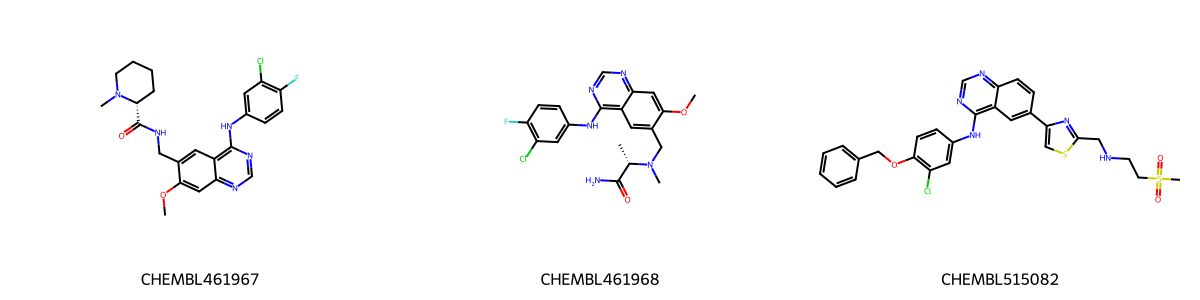

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw

ids_to_check = ["CHEMBL461967", "CHEMBL461968", "CHEMBL515082"]

duplicate_structures = structure_verification_df[
    structure_verification_df["molecule_chembl_id"].isin(ids_to_check)
].copy()

mols = [Chem.MolFromSmiles(s) for s in duplicate_structures["parent_smiles"]]

for _, row in duplicate_structures.iterrows():
    print(
        row["molecule_chembl_id"],
        "| Paper compound:", row["paper_compound_number"],
        "| pIC50:", row["pIC50"],
        "| Published:", row["published_pIC50"]
    )

display(Draw.MolsToGridImage(
    mols,
    legends=ids_to_check,
    molsPerRow=3,
    subImgSize=(400, 300)
))

In [ ]:
from rdkit import Chem

for _, row in duplicate_structures.iterrows():
    mol = Chem.MolFromSmiles(row["parent_smiles"])
    print(
        row["molecule_chembl_id"],
        "| Canonical SMILES:", Chem.MolToSmiles(mol, canonical=True),
        "| InChIKey:", Chem.MolToInchiKey(mol)
    )

print("\nPairwise structure identity:")
for i in range(len(mols)):
    for j in range(i + 1, len(mols)):
        print(
            ids_to_check[i], "vs", ids_to_check[j],
            ":",
            Chem.MolToInchiKey(mols[i]) == Chem.MolToInchiKey(mols[j])
        )

CHEMBL461967 | Canonical SMILES: COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1CNC(=O)[C@H]1CCCCN1C | InChIKey: LLRYWSSZZNXGSL-HXUWFJFHSA-N
CHEMBL461968 | Canonical SMILES: COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1CN(C)[C@@H](C)C(N)=O | InChIKey: NZOUYCUXQQRUNF-NSHDSACASA-N
CHEMBL515082 | Canonical SMILES: CS(=O)(=O)CCNCc1nc(-c2ccc3ncnc(Nc4ccc(OCc5ccccc5)c(Cl)c4)c3c2)cs1 | InChIKey: AXVKGZLOECWENV-UHFFFAOYSA-N

Pairwise structure identity:
CHEMBL461967 vs CHEMBL461968 : False
CHEMBL461967 vs CHEMBL515082 : False
CHEMBL461968 vs CHEMBL515082 : False


Valid structures: 36


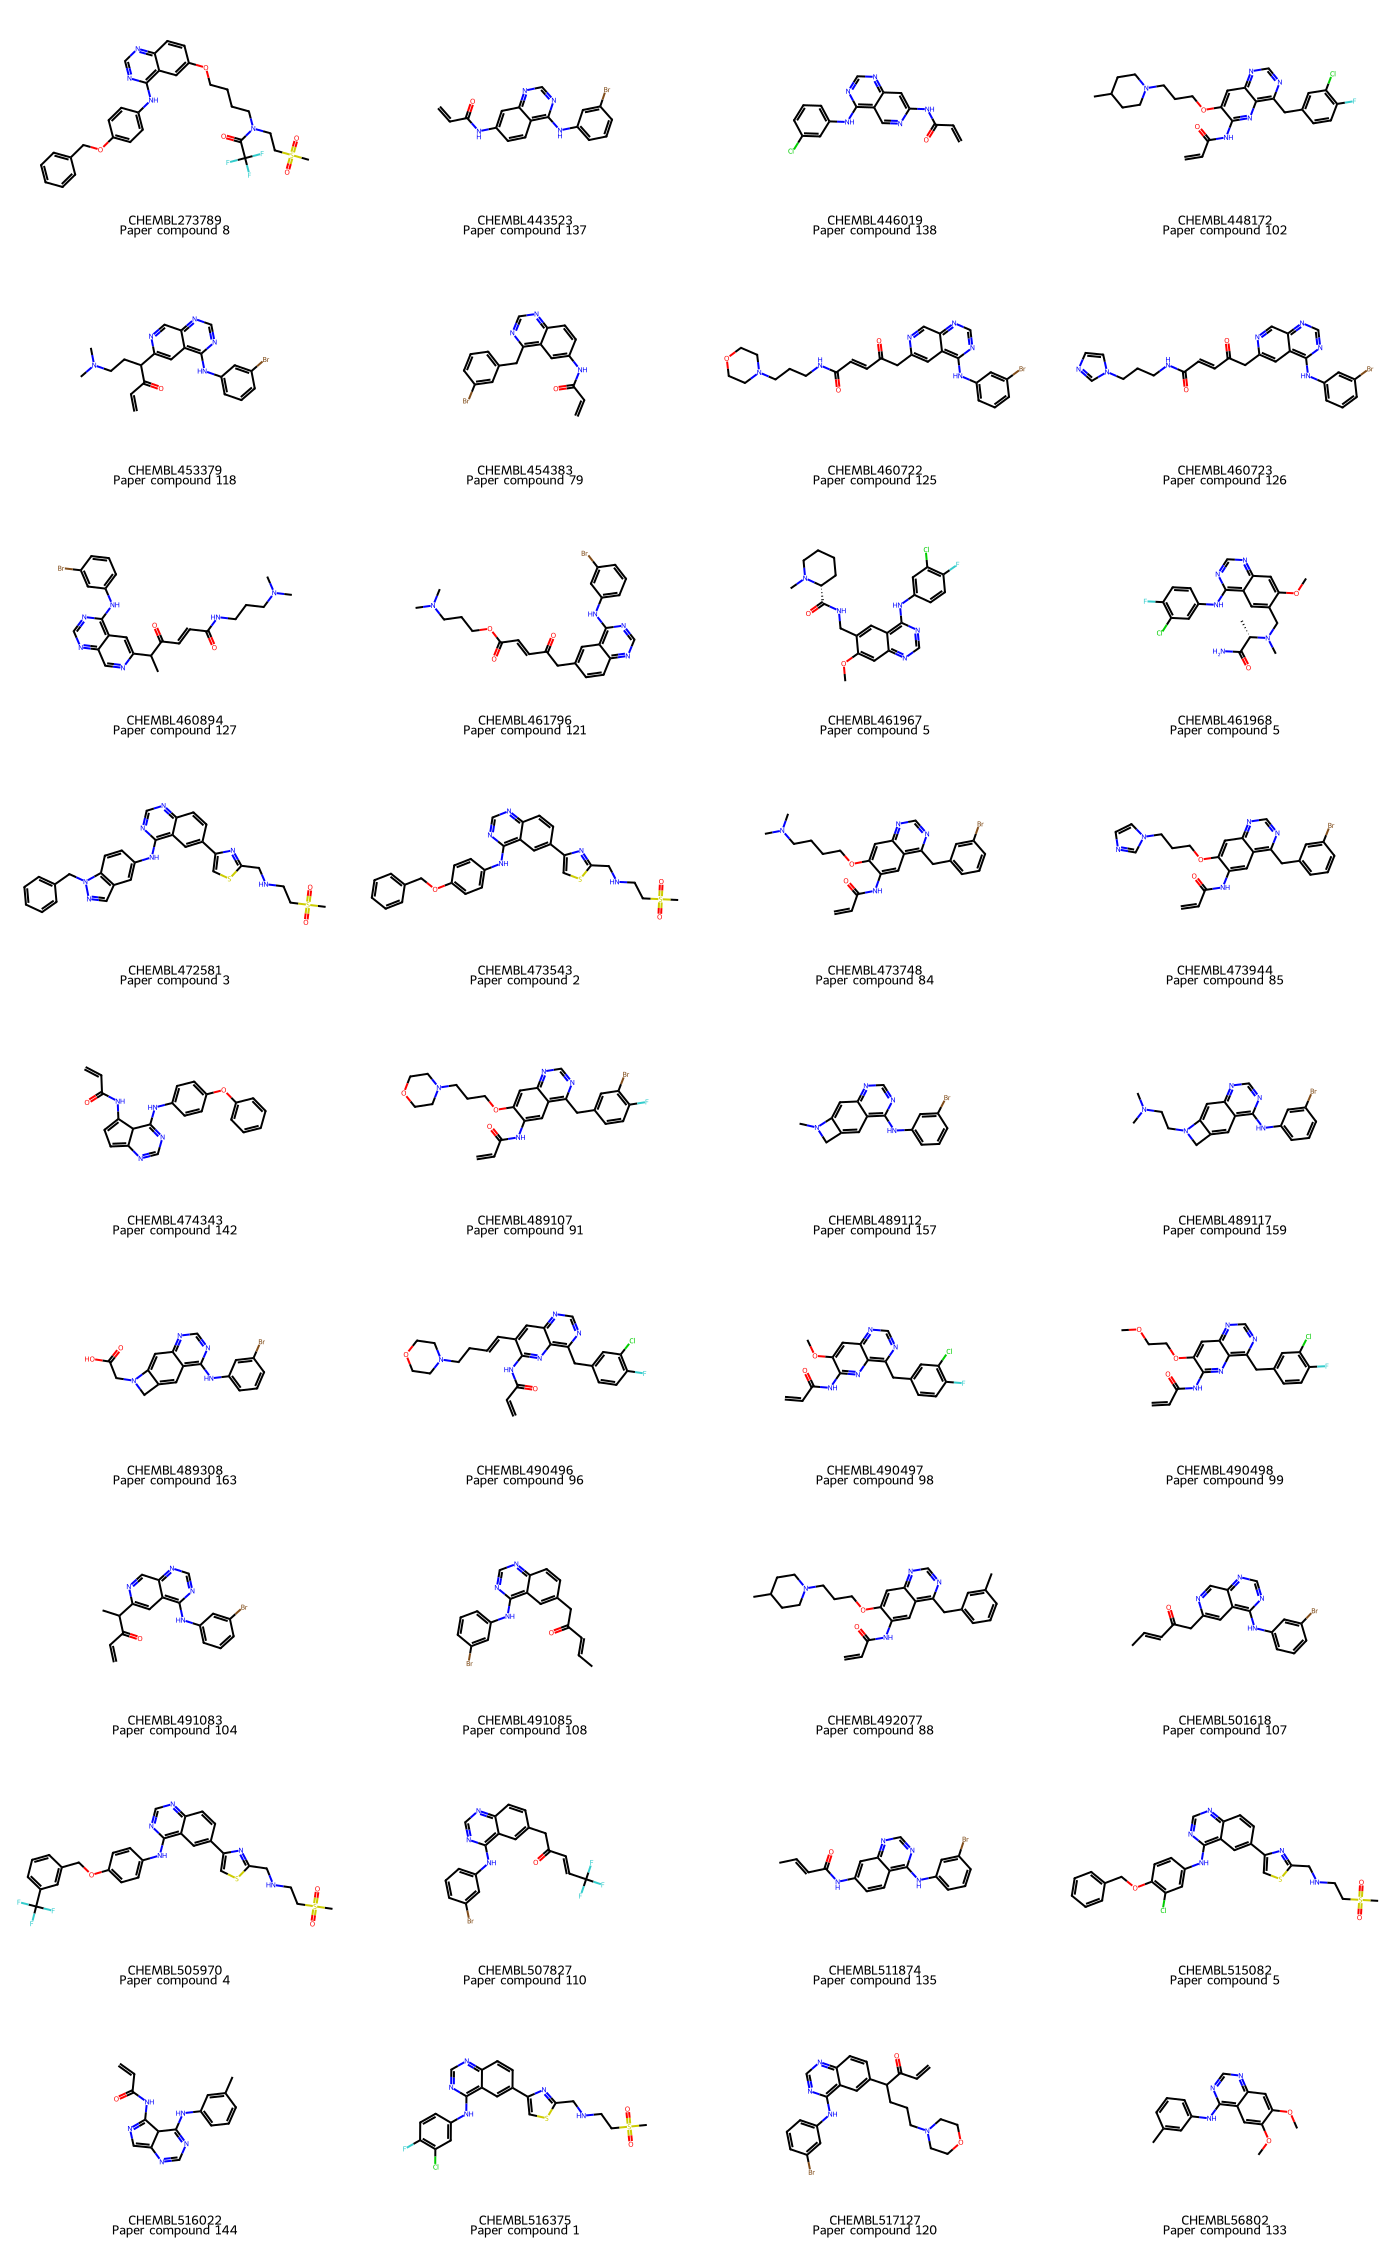

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw

mols = []
legends = []

for _, row in structure_verification_df.iterrows():
    mol = Chem.MolFromSmiles(row["parent_smiles"])
    if mol is not None:
        mols.append(mol)
        legends.append(
            f'{row["molecule_chembl_id"]}\n'
            f'Paper compound {row["paper_compound_number"]}'
        )

print("Valid structures:", len(mols))

img = Draw.MolsToGridImage(
    mols,
    molsPerRow=4,
    subImgSize=(350, 250),
    legends=legends
)

display(img)

In [ ]:
assay_id = "CHEMBL3705421"

candidate_df = integrated_activity_feature_df[
    integrated_activity_feature_df["assay_chembl_id"] == assay_id
].copy()

print("=" * 60)
print("ASSAY PROVENANCE AUDIT:", assay_id)
print("=" * 60)

for col in [
    "assay_chembl_id",
    "document_chembl_id",
    "document_year",
    "document_journal",
    "src_id",
    "assay_type",
    "bao_format",
    "confidence_score",
    "target_chembl_id",
    "target_pref_name",
    "organism",
    "assay_description"
]:
    if col in candidate_df.columns:
        print(f"\n{col}:")
        print(candidate_df[col].dropna().unique()[:5])

print("\nRECORD COUNTS")
print("Activity records:", len(candidate_df))
print("Unique compounds:", candidate_df["molecule_chembl_id"].nunique())
print("Unique parent structures:", candidate_df["parent_smiles"].nunique())
print("Unique source record IDs:", candidate_df["record_id"].nunique())

print("\nPIC50 DISTRIBUTION")
print(candidate_df["pIC50"].describe())

print("\nREPEATED MEASUREMENTS")
print("Repeated parent structures:",
      candidate_df["parent_smiles"].duplicated().sum())
print("Repeated activity IDs:",
      candidate_df["activity_id"].duplicated().sum())

ASSAY PROVENANCE AUDIT: CHEMBL3705421

assay_chembl_id:
['CHEMBL3705421']

document_chembl_id:
['CHEMBL3638799']

document_year:
[2014.]

document_journal:
[]

src_id:
[37]

assay_type:
['B']

bao_format:
['BAO_0000357']

confidence_score:
[9]

target_chembl_id:
['CHEMBL203']

target_pref_name:
['Epidermal growth factor receptor']

assay_description:
['Tyrosine Kinase Assay: EGFR1 (HER-1) enzyme assay was carried out by using Tyrosine Kinase Assay Kit Green. The entire assay was conducted in accordance with EGFR PTK inhibitor cellular activity test S.O.P.A typical kinase inhibition reaction requires a protein tyrosine kinase, a suitable buffer solution system, a peptide substrate and ATP. In the present EGFR tyrosine kinase assay, a buffer solution system containing 20 mM HEPES (pH 7.4), 5 mM MgCl2 and 2 mM MnCl2; 50 uM Na3VO4; 50 ng/10 ul EGFR (Proquinase); 100 uM ATP; and 10 ng/ml poly(Glu, Tyr) (4:1, Sigma) as a substrate were used.First, 10 ul of EGFR was added to each well of a 96

In [ ]:
repeated_df = candidate_df[
    candidate_df["parent_smiles"].duplicated(keep=False)
].copy()

audit_columns = [
    "activity_id",
    "molecule_chembl_id",
    "parent_smiles",
    "record_id",
    "standard_value",
    "standard_units",
    "pIC50",
    "standard_relation",
    "standard_text_value",
    "activity_comment"
]

audit_columns = [
    c for c in audit_columns if c in repeated_df.columns
]

print("Repeated activity records:", len(repeated_df))
print("Repeated parent structures:",
      repeated_df["parent_smiles"].nunique())

display(
    repeated_df[audit_columns]
    .sort_values(["parent_smiles", "pIC50"])
    .to_string(index=False)
)

Repeated activity records: 6
Repeated parent structures: 3


' activity_id molecule_chembl_id                                                      parent_smiles  record_id  standard_value standard_units    pIC50 standard_relation  standard_text_value  activity_comment\n    17649185      CHEMBL3676377 C=CC(=O)Nc1cc2c(Nc3ccc(Br)c(Cl)c3F)ncnc2cc1OC[C@@H](C)NC(=O)CN(C)C    2552118           286.0             nM 6.543634                 =                  NaN          266866.0\n    17649190      CHEMBL3676377 C=CC(=O)Nc1cc2c(Nc3ccc(Br)c(Cl)c3F)ncnc2cc1OC[C@@H](C)NC(=O)CN(C)C    2552118            14.0             nM 7.853872                 =                  NaN          266871.0\n    17649184      CHEMBL3676376  C=CC(=O)Nc1cc2c(Nc3ccc(Br)c(Cl)c3F)ncnc2cc1OC[C@H](C)NC(=O)CN(C)C    2552117            23.1             nM 7.636388                 =                  NaN          266865.0\n    17649189      CHEMBL3676376  C=CC(=O)Nc1cc2c(Nc3ccc(Br)c(Cl)c3F)ncnc2cc1OC[C@H](C)NC(=O)CN(C)C    2552117            12.0             nM 7.920819                 =

In [ ]:
from rdkit import Chem

for parent, group in repeated_df.groupby("parent_smiles"):
    print("\nParent structure:")
    print("ChEMBL IDs:", group["molecule_chembl_id"].unique())
    print("Measurements (nM):", group["standard_value"].tolist())

    for cid in group["molecule_chembl_id"].unique():
        smiles = group.loc[
            group["molecule_chembl_id"] == cid,
            "parent_smiles"
        ].iloc[0]

        mol = Chem.MolFromSmiles(smiles)
        print(cid, Chem.MolToInchiKey(mol))


Parent structure:
ChEMBL IDs: ['CHEMBL3676377']
Measurements (nM): [286.0, 14.0]
CHEMBL3676377 GRBIBILPWGFKCS-CYBMUJFWSA-N

Parent structure:
ChEMBL IDs: ['CHEMBL3676376']
Measurements (nM): [23.1, 12.0]
CHEMBL3676376 GRBIBILPWGFKCS-ZDUSSCGKSA-N

Parent structure:
ChEMBL IDs: ['CHEMBL3671568']
Measurements (nM): [69.0, 24.0]
CHEMBL3671568 QKEQHMZWPIXXEY-UHFFFAOYSA-N


In [ ]:
import requests
import pandas as pd

document_id = "CHEMBL3638799"

url = f"https://www.ebi.ac.uk/chembl/api/data/document/{document_id}.json"
response = requests.get(url)
response.raise_for_status()

doc = response.json()

for key in [
    "document_chembl_id",
    "title",
    "doc_type",
    "patent_number",
    "year",
    "src_id",
    "doi",
    "pubmed_id"
]:
    print(f"{key}: {doc.get(key)}")

document_chembl_id: CHEMBL3638799
title: Quinazoline derivatives as a multiplex inhibitor and method for the preparation thereof
doc_type: PATENT
patent_number: None
year: 2014
src_id: 37
doi: None
pubmed_id: None


In [ ]:
import pandas as pd

patent_url = "https://patents.google.com/patent/US8846699B2/en"

tables = pd.read_html(patent_url)

for i, table in enumerate(tables):
    print(f"Table {i}: shape={table.shape}")
    print(table.head(3).to_string(index=False))

Table 0: shape=(2, 4)
Unnamed: 0_level_0    TABLE 1                                      
Unnamed: 0_level_1 Ingredient Amount (mg/tablet) Unnamed: 3_level_1
               NaN        NaN                NaN                NaN
               NaN        NaN                NaN                NaN
Table 1: shape=(7, 4)
  0                     1      2   3
NaN            Compound X  50.00 NaN
NaN       Lactose Ph. Eur 223.75 NaN
NaN Sodium Croscarmellose   6.00 NaN
Table 2: shape=(7, 4)
Unnamed: 0_level_0             TABLE 2                                    
Unnamed: 0_level_1          Ingredient Amount (1 mg/ml) Unnamed: 3_level_1
               NaN                 NaN              NaN                NaN
               NaN          Compound X         0.1% w/v                NaN
               NaN Sodium Phosphate BP        2.26% w/v                NaN
Table 3: shape=(2, 7)
TABLE 3                                   
Example HUVEC KDR HER-1 A431 SK-Br3 SW-620
    NaN   NaN NaN   NaN  NaN   

In [ ]:
patent_table = tables[4].copy()

print("TABLE DIMENSIONS:", patent_table.shape)
print("\nFIRST 12 ROWS:")
print(patent_table.head(12).to_string(index=True))

print("\nLAST 10 ROWS:")
print(patent_table.tail(10).to_string(index=True))

print("\nCOLUMN DATA TYPES:")
print(patent_table.dtypes)

print("\nMISSING VALUES:")
print(patent_table.isna().sum())

TABLE DIMENSIONS: (177, 7)

FIRST 12 ROWS:
     0      1      2      3      4      5      6
0    1  0.085  0.131  0.003  0.048  0.283  3.058
1    2  0.096  0.250  0.047  0.082  0.240  4.578
2    3  0.090  0.108  0.026  0.048  0.216  6.308
3    4  0.087  0.136  0.015  0.025  0.147  5.675
4    5  0.034  0.203  0.003  0.037  0.241  2.347
5    6  0.450  0.500  0.056  0.168  1.346  8.456
6    7  0.099  0.250  0.026  0.038  0.067  9.567
7    8  0.098  0.148  0.013  0.020  0.149  2.527
8    9  0.048  0.045  0.036  0.051  0.266  2.585
9   10  0.049  0.055  0.006  0.008  0.330  2.755
10  11  0.041  0.050  0.014  0.059  0.456  5.678
11  12  0.156  0.347  0.002  0.017  0.157  2.504

LAST 10 ROWS:
             0         1         2         3         4         5         6
167        168     0.117     0.038     0.008     0.012     0.032        10
168        169     0.233     0.128     0.026     0.035     0.067     9.100
169        170     0.287     0.189     0.068     0.089     0.043     8.246
170  

In [ ]:
import pandas as pd
import numpy as np

# Extract patent examples 1–173 and HER-1 values (column 3)
patent_egfr = patent_table.iloc[:173, [0, 3]].copy()
patent_egfr.columns = ["patent_example", "her1_ic50_uM"]

patent_egfr["patent_example"] = pd.to_numeric(
    patent_egfr["patent_example"], errors="coerce"
)
patent_egfr["her1_ic50_uM"] = pd.to_numeric(
    patent_egfr["her1_ic50_uM"], errors="coerce"
)

# Convert µM to nM
patent_egfr["her1_ic50_nM"] = patent_egfr["her1_ic50_uM"] * 1000

chembl_values = pd.to_numeric(
    candidate_df["standard_value"], errors="coerce"
).dropna()

patent_values = patent_egfr["her1_ic50_nM"].dropna()

print("PATENT EGFR DATA")
print("Examples:", len(patent_egfr))
print("Valid HER-1 values:", len(patent_values))
print("Unique HER-1 values:", patent_values.nunique())
print("Range (nM):", patent_values.min(), "to", patent_values.max())

print("\nCHEMBL ASSAY DATA")
print("Activity records:", len(chembl_values))
print("Unique IC50 values:", chembl_values.nunique())
print("Range (nM):", chembl_values.min(), "to", chembl_values.max())

# Exact numerical overlap
patent_set = set(patent_values.round(6))
chembl_set = set(chembl_values.round(6))

print("\nNUMERICAL OVERLAP")
print("Shared distinct values:", len(patent_set & chembl_set))
print("Patent values represented in ChEMBL:",
      len(patent_set & chembl_set), "/", len(patent_set))
print("ChEMBL values represented in patent:",
      len(chembl_set & patent_set), "/", len(chembl_set))

print("\nPATENT HER-1 DISTRIBUTION (nM)")
print(patent_values.describe())

print("\nCHEMBL IC50 DISTRIBUTION (nM)")
print(chembl_values.describe())

PATENT EGFR DATA
Examples: 173
Valid HER-1 values: 173
Unique HER-1 values: 101
Range (nM): 2.0 to 10000.0

CHEMBL ASSAY DATA
Activity records: 173
Unique IC50 values: 101
Range (nM): 2.0 to 10000.0

NUMERICAL OVERLAP
Shared distinct values: 101
Patent values represented in ChEMBL: 101 / 101
ChEMBL values represented in patent: 101 / 101

PATENT HER-1 DISTRIBUTION (nM)
count      173.000000
mean       188.740462
std        792.243393
min          2.000000
25%         15.000000
50%         36.000000
75%        102.000000
max      10000.000000
Name: her1_ic50_nM, dtype: float64

CHEMBL IC50 DISTRIBUTION (nM)
count      173.000000
mean       188.740462
std        792.243393
min          2.000000
25%         15.000000
50%         36.000000
75%        102.000000
max      10000.000000
Name: standard_value, dtype: float64


In [ ]:
from collections import Counter

patent_counts = Counter(
    patent_egfr["her1_ic50_nM"].round(6)
)

chembl_counts = Counter(
    pd.to_numeric(candidate_df["standard_value"], errors="coerce")
    .dropna()
    .round(6)
)

print("EXACT MULTISET MATCH:", patent_counts == chembl_counts)

if patent_counts != chembl_counts:
    print("\nVALUES WITH DIFFERENT FREQUENCIES:")
    for value in sorted(set(patent_counts) | set(chembl_counts)):
        if patent_counts[value] != chembl_counts[value]:
            print(
                f"{value} nM | Patent: {patent_counts[value]} "
                f"| ChEMBL: {chembl_counts[value]}"
            )
else:
    print("All 101 distinct values have identical frequencies.")
    print("Total patent measurements:", sum(patent_counts.values()))
    print("Total ChEMBL measurements:", sum(chembl_counts.values()))

EXACT MULTISET MATCH: True
All 101 distinct values have identical frequencies.
Total patent measurements: 173
Total ChEMBL measurements: 173


In [ ]:
# Inspect the upper-bound measurements in both datasets

print("PATENT HER-1 VALUES AT 10 µM:")
print(
    patent_egfr.loc[
        patent_egfr["her1_ic50_uM"] == 10
    ].to_string(index=False)
)

print("\nCHEMBL RECORDS AT 10,000 nM:")
upper_df = candidate_df[
    pd.to_numeric(candidate_df["standard_value"], errors="coerce") == 10000
].copy()

cols = [
    "molecule_chembl_id",
    "activity_id",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "activity_comment",
    "data_validity_comment"
]

print(upper_df[[c for c in cols if c in upper_df.columns]].to_string(index=False))

print("\nCOUNT AT UPPER BOUND")
print("Patent:", (patent_egfr["her1_ic50_uM"] == 10).sum())
print("ChEMBL:", len(upper_df))

PATENT HER-1 VALUES AT 10 µM:
 patent_example  her1_ic50_uM  her1_ic50_nM
            131          10.0       10000.0

CHEMBL RECORDS AT 10,000 nM:
molecule_chembl_id  activity_id standard_type standard_relation  standard_value standard_units  activity_comment  data_validity_comment
     CHEMBL3676351     17649159          IC50                 =         10000.0             nM          266840.0                    NaN

COUNT AT UPPER BOUND
Patent: 1
ChEMBL: 1


### CHEMBL3705421 — Patent-Level EGFR Provenance Validation

**Source:** ChEMBL document CHEMBL3638799, 2014 patent, *Quinazoline derivatives as a multiplex inhibitor and method for the preparation thereof*.

**Patent reference:** US 8,846,699 B2.

**Assay:** Human EGFR/HER-1 tyrosine kinase inhibition assay.

**Validation performed:**
- Retrieved the patent's Table 3 and Table 4.
- Identified the HER-1 column as the EGFR endpoint.
- Extracted all 173 numbered compound examples.
- Converted patent IC50 values from µM to nM.
- Compared patent and ChEMBL measurements.

**Results:**
- Patent EGFR measurements: 173.
- ChEMBL activity records: 173.
- Distinct IC50 values in both datasets: 101.
- Exact numerical multiset match: PASS.
- Identical value frequencies: PASS.
- Identical IC50 distribution statistics: PASS.

**Upper-bound observation:** One measurement is reported as 10 µM in the patent and 10,000 nM in ChEMBL. The ChEMBL relation is `=`. Whether this represents a true measured IC50 or an assay-limit value remains unresolved.

**Conclusion:** CHEMBL3705421 has strong patent-level numerical provenance supporting its assignment to the EGFR/HER-1 assay. Individual ChEMBL compound-to-patent-example structure correspondence has not yet been independently established. The assay is retained as a high-priority candidate source, with the upper-bound measurement flagged for sensitivity analysis.

**Interpretation limitation:** Numerical provenance validation supports source consistency; it does not establish assay-wide equivalence to other EGFR datasets or eliminate all experimental uncertainty.

## Phase 5 — Bioactivity Label Strategy and Modelling Dataset Design

### Progress: Assay Provenance Investigation

The objective is to establish a scientifically defensible bioactivity label strategy before constructing the modelling dataset.

#### CHEMBL3705421 — Patent-Level EGFR Provenance Audit

- Source document: CHEMBL3638799 (2014 patent).
- Patent: US 8,846,699 B2.
- Assay endpoint: Human EGFR/HER-1 tyrosine kinase inhibition.
- Source database: BindingDB Patent Bioactivity Data (source 37).

**Patent-to-ChEMBL numerical validation:**

| Validation | Result |
|---|---:|
| Patent EGFR measurements | 173 |
| ChEMBL activity records | 173 |
| Distinct IC50 values | 101 |
| Exact numerical multiset match | PASS |
| Identical measurement frequencies | PASS |
| Identical distribution statistics | PASS |

Patent IC50 values were converted from µM to nM before comparison.

**Data quality observation:**

One measurement is reported at 10 µM (10,000 nM). Its ChEMBL relation is `=`. Whether this represents a measured IC50 or an assay reporting limit remains unresolved. It will be retained with an uncertainty flag for sensitivity analysis.

**Conclusion:**

CHEMBL3705421 has strong patent-level numerical provenance supporting its EGFR/HER-1 assignment. Individual compound-to-patent-example structure correspondence remains unverified.

### Phase 5 Status

- Assay heterogeneity and cross-assay comparability: Audited.
- Candidate assay provenance: In progress.
- Bioactivity aggregation strategy: Pending.
- Modelling dataset construction: Pending.
- Exploratory analysis and data splitting: Pending.
- Model development and evaluation: Pending.

No model training or premature bioactivity aggregation has been performed.